In [1]:
# ============================================================
# CREATE all_raw_cleaned.parquet
# Raw RINEX → Clean NavIC Feature Dataset
# ============================================================

# If required:
# !pip install georinex pandas numpy scipy pyarrow tqdm

import os
import re
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import georinex as gr

from scipy.signal import butter, filtfilt

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

In [2]:
# ============================================================
# CONFIGURATION
# ============================================================

PROJECT_ROOT = Path("navic_o1")

RAW_DIR = PROJECT_ROOT / "data" / "raw"

PROC_DIR = PROJECT_ROOT / "data" / "processed"

PROC_DIR.mkdir(
    parents=True,
    exist_ok=True
)


OUTPUT_FILE = (
    PROC_DIR /
    "all_raw_cleaned.parquet"
)


# ------------------------------------------------------------
# STATIONS
# ------------------------------------------------------------

STATIONS = {
    "IISC00IND": {
        "lat": 13.021,
        "lon": 77.570
    },

    "JDPR00IND": {
        "lat": 26.297,
        "lon": 73.026
    },

    "LCK400IND": {
        "lat": 26.910,
        "lon": 80.994
    }
}


# ------------------------------------------------------------
# NAVIC OBSERVABLES
# ------------------------------------------------------------

NAVIC_SYSTEM = "I"

PSEUDORANGE = "C5A"

CARRIER_PHASE = "L5A"

SIGNAL_STRENGTH = "S5A"


# ------------------------------------------------------------
# SAMPLING
# ------------------------------------------------------------

SAMPLE_SECONDS = 30

FS = 1.0 / SAMPLE_SECONDS


# ------------------------------------------------------------
# SCINTILLATION PARAMETERS
# ------------------------------------------------------------

# 20 × 30 s = 10 minutes
WINDOW_EPOCHS = 20

# High-pass cutoff used by your existing implementation
SIGPHI_CUTOFF_HZ = 0.1

BUTTERWORTH_ORDER = 3


# ------------------------------------------------------------
# S4 THRESHOLDS
# ------------------------------------------------------------

S4_MILD_THRESHOLD = 0.3

S4_STRONG_THRESHOLD = 0.6


print("Raw directory :", RAW_DIR)
print("Output file   :", OUTPUT_FILE)

Raw directory : navic_o1\data\raw
Output file   : navic_o1\data\processed\all_raw_cleaned.parquet


In [3]:
# ============================================================
# FIND ALL RAW FILES
# ============================================================

SUPPORTED_EXTENSIONS = {
    ".rnx",
    ".crx",
    ".obs"
}


raw_files = []

for path in RAW_DIR.rglob("*"):

    if not path.is_file():
        continue

    name = path.name.lower()

    # Handle:
    # .rnx
    # .crx
    # .rnx.gz
    # .crx.gz
    # .rnx.gz
    # etc.

    if (
        name.endswith(".rnx")
        or name.endswith(".crx")
        or name.endswith(".obs")
        or name.endswith(".rnx.gz")
        or name.endswith(".crx.gz")
        or name.endswith(".obs.gz")
    ):

        raw_files.append(path)


raw_files = sorted(
    raw_files
)


print(
    f"Found {len(raw_files):,} raw RINEX files."
)


print("\nFirst 10:")

for f in raw_files[:10]:
    print(f)

Found 908 raw RINEX files.

First 10:
navic_o1\data\raw\IISC\2022\060\IISC00IND_R_20220600000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\060\IISC00IND_R_20220600000_01D_30S_MO.rnx
navic_o1\data\raw\IISC\2022\061\IISC00IND_R_20220610000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\061\IISC00IND_R_20220610000_01D_30S_MO.rnx
navic_o1\data\raw\IISC\2022\062\IISC00IND_R_20220620000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\062\IISC00IND_R_20220620000_01D_30S_MO.rnx
navic_o1\data\raw\IISC\2022\063\IISC00IND_R_20220630000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\063\IISC00IND_R_20220630000_01D_30S_MO.rnx
navic_o1\data\raw\IISC\2022\064\IISC00IND_R_20220640000_01D_30S_MO.crx
navic_o1\data\raw\IISC\2022\064\IISC00IND_R_20220640000_01D_30S_MO.rnx


In [4]:
# ============================================================
# STATION FILE COUNTS
# ============================================================

for station in STATIONS:

    station_files = [
        f for f in raw_files
        if station in f.name.upper()
        or station[:4] in f.name.upper()
    ]

    print(
        f"{station}: "
        f"{len(station_files):,} files"
    )

IISC00IND: 336 files
JDPR00IND: 262 files
LCK400IND: 310 files


In [5]:
# ============================================================
# IDENTIFY STATION
# ============================================================

def identify_station(path):

    name = path.name.upper()

    for station in STATIONS:

        if station in name:
            return station

        if station[:4] in name:
            return station

    # Also inspect parent directories
    for parent in path.parents:

        p = parent.name.upper()

        for station in STATIONS:

            if station in p:
                return station

            if station[:4] in p:
                return station


    return None

In [6]:
# ============================================================
# IONOSPHERIC CONDITION
# ============================================================

def get_condition(timestamp):

    year = timestamp.year

    doy = timestamp.dayofyear


    # --------------------------------------------------------
    # EQUINOCTIAL
    # --------------------------------------------------------

    if year in [2022, 2023]:

        if 60 <= doy <= 90:
            return "equinoctial"

        if 244 <= doy <= 274:
            return "equinoctial"


    # --------------------------------------------------------
    # MONSOON
    # --------------------------------------------------------

    if year in [2022, 2023]:

        if 182 <= doy <= 243:
            return "monsoon"


    # --------------------------------------------------------
    # QUIET
    # --------------------------------------------------------

    if year == 2022:

        if 335 <= doy <= 365:
            return "quiet"


    # --------------------------------------------------------
    # 2024 / SOLAR-MAX PERIOD
    # --------------------------------------------------------

    if year == 2024:

        if 1 <= doy <= 59:
            return "solar_max"


    return "unknown"

In [7]:
# ============================================================
# S4
# ============================================================

def compute_s4(
    snr_dbhz,
    window=WINDOW_EPOCHS
):

    snr_dbhz = np.asarray(
        snr_dbhz,
        dtype=float
    )

    # Convert C/N0 dB-Hz → relative power
    intensity = (
        10 ** (snr_dbhz / 10.0)
    )


    n = len(intensity)

    s4 = np.full(
        n,
        np.nan,
        dtype=float
    )


    for i in range(
        window - 1,
        n
    ):

        w = intensity[
            i - window + 1 :
            i + 1
        ]

        w = w[
            np.isfinite(w)
        ]


        if len(w) < window // 2:
            continue


        mean_i = np.mean(w)

        mean_i2 = np.mean(
            w ** 2
        )


        if mean_i > 1e-12:

            variance = max(
                mean_i2 - mean_i ** 2,
                0
            )

            s4[i] = (
                np.sqrt(variance)
                / mean_i
            )


    return s4

In [8]:
# ============================================================
# HIGH-PASS FILTER
# ============================================================

def high_pass_filter(
    signal,
    cutoff=SIGPHI_CUTOFF_HZ,
    fs=FS,
    order=BUTTERWORTH_ORDER
):

    signal = np.asarray(
        signal,
        dtype=float
    )


    valid = np.isfinite(
        signal
    )


    if valid.sum() < order * 3:

        return np.full_like(
            signal,
            np.nan
        )


    nyquist = 0.5 * fs


    normalized_cutoff = np.clip(
        cutoff / nyquist,
        1e-6,
        1 - 1e-6
    )


    b, a = butter(
        order,
        normalized_cutoff,
        btype="high"
    )


    filtered_input = signal.copy()


    # Fill missing observations temporarily
    # so filtfilt can operate.

    fill_value = np.nanmean(
        signal
    )

    filtered_input[
        ~valid
    ] = fill_value


    filtered = filtfilt(
        b,
        a,
        filtered_input
    )


    return filtered

In [9]:
# ============================================================
# SIGMA-PHI
# ============================================================

def compute_sigma_phi(
    phase_cycles,
    window=WINDOW_EPOCHS
):

    phase_cycles = np.asarray(
        phase_cycles,
        dtype=float
    )


    n = len(
        phase_cycles
    )


    sigma_phi = np.full(
        n,
        np.nan,
        dtype=float
    )


    # cycles → radians
    phase_rad = (
        phase_cycles * 2 * np.pi
    )


    detrended = high_pass_filter(
        phase_rad
    )


    for i in range(
        window - 1,
        n
    ):

        original = (
            phase_cycles[
                i - window + 1 :
                i + 1
            ]
        )


        filtered = (
            detrended[
                i - window + 1 :
                i + 1
            ]
        )


        valid = np.isfinite(
            original
        )


        if valid.sum() < window // 2:
            continue


        sigma_phi[i] = np.nanstd(
            filtered
        )


    return sigma_phi

In [10]:
# ============================================================
# PROCESS ONE RINEX FILE
# ============================================================

def process_rinex_file(
    rnx_path
):

    station = identify_station(
        rnx_path
    )


    if station is None:

        print(
            f"[SKIP] Station not identified: "
            f"{rnx_path.name}"
        )

        return None


    station_lat = STATIONS[
        station
    ]["lat"]


    station_lon = STATIONS[
        station
    ]["lon"]


    try:

        obs = gr.load(
            str(rnx_path),
            use=NAVIC_SYSTEM
        )

    except Exception as e:

        print(
            f"[ERROR] {rnx_path.name}: {e}"
        )

        return None


    if obs is None:

        return None


    if "time" not in obs.coords:

        return None


    if "sv" not in obs.coords:

        return None


    times = pd.to_datetime(
        obs.coords["time"].values
    )


    satellites = (
        obs.coords["sv"]
        .values
    )


    n_times = len(
        times
    )


    if n_times == 0:

        return None


    # --------------------------------------------------------
    # TIME FEATURES
    # --------------------------------------------------------

    years = np.array([
        t.year
        for t in times
    ])

    doys = np.array([
        t.dayofyear
        for t in times
    ])

    utc_hours = np.array([
        t.hour
        + t.minute / 60.0
        + t.second / 3600.0
        for t in times
    ])


    # Simple local solar time approximation
    solar_local_time = (
        utc_hours
        + station_lon / 15.0
    ) % 24.0


    records = []


    # --------------------------------------------------------
    # PROCESS EACH NAVIC SATELLITE
    # --------------------------------------------------------

    for sv in satellites:

        def get_observable(
            name
        ):

            if name not in obs.data_vars:

                return np.full(
                    n_times,
                    np.nan
                )


            try:

                values = (
                    obs[name]
                    .sel(sv=sv)
                    .values
                    .astype(float)
                )


                # RINEX missing/invalid values
                # are treated as missing.

                values[
                    ~np.isfinite(values)
                ] = np.nan


                values[
                    values <= 0
                ] = np.nan


                return values


            except Exception:

                return np.full(
                    n_times,
                    np.nan
                )


        # ----------------------------------------------------
        # NAVIC L5 OBSERVABLES
        # ----------------------------------------------------

        c5a = get_observable(
            "C5A"
        )

        l5a = get_observable(
            "L5A"
        )

        s5a = get_observable(
            "S5A"
        )


        # ----------------------------------------------------
        # REQUIRE AT LEAST SOME VALID DATA
        # ----------------------------------------------------

        valid_count = np.sum(
            np.isfinite(s5a)
            |
            np.isfinite(l5a)
            |
            np.isfinite(c5a)
        )


        if valid_count < 20:

            continue


        # ----------------------------------------------------
        # BUILD TEMPORARY SATELLITE DATAFRAME
        # ----------------------------------------------------

        g = pd.DataFrame({

            "time": times,

            "station": station,

            "sv": str(sv),

            "C5A": c5a,

            "L5A": l5a,

            "S5A": s5a,

            "station_lat":
                station_lat,

            "station_lon":
                station_lon,

            "solar_local_time":
                solar_local_time,

            "day_of_year":
                doys,

            "year":
                years
        })


        # ----------------------------------------------------
        # SIGNAL QUALITY
        # ----------------------------------------------------

        g["cn0_mean"] = (
            g["S5A"]
            .rolling(
                10,
                min_periods=3
            )
            .mean()
        )


        g["cn0_std"] = (
            g["S5A"]
            .rolling(
                10,
                min_periods=3
            )
            .std()
        )


        g["cn0_variation"] = (
            g["S5A"]
            - g["cn0_mean"]
        )


        # ----------------------------------------------------
        # CARRIER PHASE DIFFERENCE
        # ----------------------------------------------------

        g["phase_diff"] = (
            g["L5A"].diff()
        )


        g["phase_rate"] = (
            g["phase_diff"]
            / SAMPLE_SECONDS
        )


        # ----------------------------------------------------
        # PHASE RESIDUAL
        # ----------------------------------------------------

        phase_smooth = (
            g["L5A"]
            .rolling(
                5,
                min_periods=2
            )
            .mean()
        )


        g["phase_residual"] = (
            g["L5A"]
            - phase_smooth
        )


        # ----------------------------------------------------
        # S4
        # ----------------------------------------------------

        g["s4_l5"] = compute_s4(
            g["S5A"].values
        )


        # ----------------------------------------------------
        # SIGMA-PHI
        # ----------------------------------------------------

        g["sigma_phi"] = (
            compute_sigma_phi(
                g["L5A"].values
            )
        )


        # ----------------------------------------------------
        # ROLLING VARIABILITY
        # ----------------------------------------------------

        g["phase_variability"] = (
            g["phase_residual"]
            .rolling(
                WINDOW_EPOCHS,
                min_periods=5
            )
            .std()
        )


        # ----------------------------------------------------
        # CURRENT FORECAST TARGET VARIABLE
        #
        # This is your project's current
        # carrier-phase variability proxy.
        # ----------------------------------------------------

        g["sigma_phi_proxy"] = (
            g["phase_variability"]
        )


        # ----------------------------------------------------
        # EPB / SCINTILLATION FLAGS
        #
        # Only use these as S4-derived labels if S4 is
        # genuinely being used as the event variable.
        # ----------------------------------------------------

        g["epb_mild"] = (
            g["s4_l5"]
            >= S4_MILD_THRESHOLD
        ).astype(int)


        g["epb_strong"] = (
            g["s4_l5"]
            >= S4_STRONG_THRESHOLD
        ).astype(int)


        # ----------------------------------------------------
        # CONDITION
        # ----------------------------------------------------

        g["condition"] = (
            g["time"]
            .map(get_condition)
        )


        # ----------------------------------------------------
        # KEEP
        # ----------------------------------------------------

        records.append(
            g
        )


    if not records:

        return None


    result = pd.concat(
        records,
        ignore_index=True
    )


    return result

In [11]:
# ============================================================
# PROCESS COMPLETE DATASET
# ============================================================

all_chunks = []

successful = 0

failed = 0


print(
    f"Processing {len(raw_files):,} files..."
)


for i, rnx_file in enumerate(
    tqdm(
        raw_files,
        desc="RINEX processing"
    )
):

    try:

        result = process_rinex_file(
            rnx_file
        )


        if result is None:

            failed += 1

            continue


        all_chunks.append(
            result
        )

        successful += 1


    except Exception as e:

        failed += 1

        print(
            f"\n[FAILED] "
            f"{rnx_file.name}\n"
            f"{e}"
        )


    # Periodically report memory
    if (i + 1) % 100 == 0:

        print(
            f"\nProcessed: {i+1:,}/{len(raw_files):,}"
            f" | successful={successful:,}"
            f" | failed={failed:,}"
        )


print("\nProcessing finished.")

print(
    "Successful files:",
    successful
)

print(
    "Failed files:",
    failed
)

Processing 908 files...


RINEX processing:   0%|          | 0/908 [00:00<?, ?it/s]


Processed: 100/908 | successful=100 | failed=0

Processed: 200/908 | successful=200 | failed=0

Processed: 300/908 | successful=300 | failed=0
[ERROR] JDPR00IND_R_20220610000_01D_30S_MO.crx: "system type {'I'} not found in RINEX file"
[ERROR] JDPR00IND_R_20220610000_01D_30S_MO.rnx: "system type {'I'} not found in RINEX file"
[ERROR] JDPR00IND_R_20220620000_01D_30S_MO.crx: "system type {'I'} not found in RINEX file"
[ERROR] JDPR00IND_R_20220620000_01D_30S_MO.rnx: "system type {'I'} not found in RINEX file"
[ERROR] JDPR00IND_R_20220650000_01D_30S_MO.crx: "system type {'I'} not found in RINEX file"
[ERROR] JDPR00IND_R_20220650000_01D_30S_MO.rnx: "system type {'I'} not found in RINEX file"
[ERROR] JDPR00IND_R_20220660000_01D_30S_MO.crx: "system type {'I'} not found in RINEX file"
[ERROR] JDPR00IND_R_20220660000_01D_30S_MO.rnx: "system type {'I'} not found in RINEX file"
[ERROR] JDPR00IND_R_20220670000_01D_30S_MO.crx: "system type {'I'} not found in RINEX file"
[ERROR] JDPR00IND_R_20220670

In [12]:
# ============================================================
# COMBINE ALL FILES
# ============================================================

if not all_chunks:

    raise RuntimeError(
        "No RINEX files were successfully processed."
    )


all_raw = pd.concat(
    all_chunks,
    ignore_index=True
)


del all_chunks

gc.collect()


print(
    "Combined shape:",
    all_raw.shape
)

Combined shape: (15202562, 24)


In [13]:
# ============================================================
# SORT
# ============================================================

all_raw = all_raw.sort_values(
    [
        "station",
        "sv",
        "time"
    ]
).reset_index(
    drop=True
)


print(
    all_raw[
        [
            "station",
            "sv",
            "time"
        ]
    ].head()
)

     station   sv                time
0  IISC00IND  I01 2022-03-01 00:00:00
1  IISC00IND  I01 2022-03-01 00:00:00
2  IISC00IND  I01 2022-03-01 00:00:30
3  IISC00IND  I01 2022-03-01 00:00:30
4  IISC00IND  I01 2022-03-01 00:01:00


In [14]:
# ============================================================
# DUPLICATE RECONCILIATION
# ============================================================

duplicate_mask = all_raw.duplicated(
    subset=[
        "station",
        "sv",
        "time"
    ],
    keep="first"
)


duplicate_count = (
    duplicate_mask.sum()
)


print(
    "Duplicate station/satellite/time rows:",
    duplicate_count
)


if duplicate_count > 0:

    all_raw = all_raw[
        ~duplicate_mask
    ].copy()


    all_raw.reset_index(
        drop=True,
        inplace=True
    )


print(
    "Shape after duplicate removal:",
    all_raw.shape
)

Duplicate station/satellite/time rows: 7601281
Shape after duplicate removal: (7601281, 24)


In [15]:
# ============================================================
# CADENCE CHECK
# ============================================================

cadence = (
    all_raw
    .groupby(
        ["station", "sv"]
    )["time"]
    .diff()
    .dt.total_seconds()
)


print(
    "Most common time differences:"
)

print(
    cadence
    .value_counts()
    .head(10)
)

Most common time differences:
time
30.0          7600926
9158430.0          48
86430.0            39
60.0               32
2678430.0          27
90.0               24
6480030.0          14
5961630.0          12
11145630.0         12
990.0               8
Name: count, dtype: int64


In [16]:
# ============================================================
# TEMPORAL FEATURES
# ============================================================

def add_temporal_features(g):

    g = g.sort_values(
        "time"
    ).copy()


    x = g[
        "sigma_phi_proxy"
    ]


    # --------------------------------------------------------
    # LAGS
    # --------------------------------------------------------

    for lag in [
        1,
        2,
        5,
        10,
        20
    ]:

        g[
            f"lag_{lag}"
        ] = x.shift(lag)


    # --------------------------------------------------------
    # DIFFERENCE
    # --------------------------------------------------------

    g["diff_1"] = (
        x.diff()
    )


    g["abs_diff_1"] = (
        g["diff_1"].abs()
    )


    g["rate_1"] = (
        g["diff_1"]
        / SAMPLE_SECONDS
    )


    # --------------------------------------------------------
    # ROLLING FEATURES
    # --------------------------------------------------------

    for window in [
        5,
        10,
        20
    ]:

        g[
            f"roll_mean_{window}"
        ] = (
            x.rolling(
                window,
                min_periods=3
            ).mean()
        )


        g[
            f"roll_std_{window}"
        ] = (
            x.rolling(
                window,
                min_periods=3
            ).std()
        )


        g[
            f"roll_min_{window}"
        ] = (
            x.rolling(
                window,
                min_periods=3
            ).min()
        )


        g[
            f"roll_max_{window}"
        ] = (
            x.rolling(
                window,
                min_periods=3
            ).max()
        )


    return g

In [17]:
# ============================================================
# APPLY TEMPORAL FEATURES
# ============================================================

all_raw = (
    all_raw
    .groupby(
        ["station", "sv"],
        group_keys=False
    )
    .apply(
        add_temporal_features
    )
    .reset_index(drop=True)
)


print(
    "Shape after temporal features:",
    all_raw.shape
)

Shape after temporal features: (7601281, 44)


In [18]:
# ============================================================
# 10-MINUTE TARGET
# ============================================================

FORECAST_HORIZON_STEPS = 20


all_raw["target_10min"] = (
    all_raw
    .groupby(
        ["station", "sv"]
    )["sigma_phi_proxy"]
    .shift(
        -FORECAST_HORIZON_STEPS
    )
)


print(
    "10-minute target created."
)

10-minute target created.


In [19]:
# ============================================================
# VERIFY 10-MINUTE TARGET
# ============================================================

all_raw["future_time"] = (
    all_raw
    .groupby(
        ["station", "sv"]
    )["time"]
    .shift(
        -FORECAST_HORIZON_STEPS
    )
)


all_raw["target_lead_seconds"] = (
    all_raw["future_time"]
    - all_raw["time"]
).dt.total_seconds()


print(
    all_raw[
        "target_lead_seconds"
    ]
    .value_counts()
    .head(10)
)

target_lead_seconds
600.0         7594896
9159000.0         960
87000.0           780
2679000.0         540
690.0             304
6480600.0         280
11146200.0        240
5962200.0         240
630.0             184
660.0             176
Name: count, dtype: int64


In [20]:
# ============================================================
# FINAL QUALITY FILTER
# ============================================================

# Remove rows without the core forecasting target.

all_raw = all_raw.dropna(
    subset=[
        "sigma_phi_proxy",
        "target_10min"
    ]
).copy()


# Replace infinities

all_raw = all_raw.replace(
    [np.inf, -np.inf],
    np.nan
)


print(
    "Rows after target cleaning:",
    len(all_raw)
)

Rows after target cleaning: 6698777


In [21]:
# ============================================================
# DATA TYPES
# ============================================================

numeric_columns = [
    "C5A",
    "L5A",
    "S5A",

    "station_lat",
    "station_lon",

    "solar_local_time",
    "day_of_year",
    "year",

    "cn0_mean",
    "cn0_std",
    "cn0_variation",

    "phase_diff",
    "phase_rate",
    "phase_residual",
    "phase_variability",

    "sigma_phi",
    "sigma_phi_proxy",

    "s4_l5",

    "epb_mild",
    "epb_strong",

    "lag_1",
    "lag_2",
    "lag_5",
    "lag_10",
    "lag_20",

    "diff_1",
    "abs_diff_1",
    "rate_1",

    "roll_mean_5",
    "roll_std_5",
    "roll_min_5",
    "roll_max_5",

    "roll_mean_10",
    "roll_std_10",
    "roll_min_10",
    "roll_max_10",

    "roll_mean_20",
    "roll_std_20",
    "roll_min_20",
    "roll_max_20",

    "target_10min"
]


for col in numeric_columns:

    if col in all_raw.columns:

        all_raw[col] = pd.to_numeric(
            all_raw[col],
            errors="coerce"
        )

In [22]:
# ============================================================
# FINAL COLUMN ORDER
# ============================================================

preferred_columns = [

    # Metadata
    "time",
    "station",
    "sv",

    # Station context
    "station_lat",
    "station_lon",

    # Time context
    "year",
    "day_of_year",
    "solar_local_time",

    # Raw NavIC observables
    "C5A",
    "L5A",
    "S5A",

    # Signal features
    "cn0_mean",
    "cn0_std",
    "cn0_variation",

    # Carrier phase
    "phase_diff",
    "phase_rate",
    "phase_residual",
    "phase_variability",

    # Scintillation
    "s4_l5",
    "sigma_phi",

    # Current operational target/proxy
    "sigma_phi_proxy",

    # Temporal
    "lag_1",
    "lag_2",
    "lag_5",
    "lag_10",
    "lag_20",

    "diff_1",
    "abs_diff_1",
    "rate_1",

    "roll_mean_5",
    "roll_std_5",
    "roll_min_5",
    "roll_max_5",

    "roll_mean_10",
    "roll_std_10",
    "roll_min_10",
    "roll_max_10",

    "roll_mean_20",
    "roll_std_20",
    "roll_min_20",
    "roll_max_20",

    # Labels
    "epb_mild",
    "epb_strong",
    "condition",

    # Target
    "target_10min"
]


final_columns = [
    c
    for c in preferred_columns
    if c in all_raw.columns
]


all_raw = all_raw[
    final_columns
].copy()


print(
    "Final columns:",
    len(all_raw.columns)
)

print(
    all_raw.columns.tolist()
)

Final columns: 45
['time', 'station', 'sv', 'station_lat', 'station_lon', 'year', 'day_of_year', 'solar_local_time', 'C5A', 'L5A', 'S5A', 'cn0_mean', 'cn0_std', 'cn0_variation', 'phase_diff', 'phase_rate', 'phase_residual', 'phase_variability', 's4_l5', 'sigma_phi', 'sigma_phi_proxy', 'lag_1', 'lag_2', 'lag_5', 'lag_10', 'lag_20', 'diff_1', 'abs_diff_1', 'rate_1', 'roll_mean_5', 'roll_std_5', 'roll_min_5', 'roll_max_5', 'roll_mean_10', 'roll_std_10', 'roll_min_10', 'roll_max_10', 'roll_mean_20', 'roll_std_20', 'roll_min_20', 'roll_max_20', 'epb_mild', 'epb_strong', 'condition', 'target_10min']


In [23]:
# ============================================================
# FINAL DATASET VALIDATION
# ============================================================

print("=" * 70)

print(
    "FINAL CLEAN DATASET REPORT"
)

print("=" * 70)


print(
    "\nRows:",
    f"{len(all_raw):,}"
)


print(
    "Columns:",
    len(all_raw.columns)
)


print(
    "Memory:",
    f"{all_raw.memory_usage(deep=True).sum()/1024**3:.2f} GB"
)


print(
    "\nTime range:"
)

print(
    all_raw["time"].min(),
    "→",
    all_raw["time"].max()
)


print(
    "\nStations:"
)

print(
    all_raw["station"]
    .value_counts()
)


print(
    "\nSatellites:"
)

print(
    all_raw["sv"]
    .value_counts()
)


print(
    "\nConditions:"
)

print(
    all_raw["condition"]
    .value_counts()
)


print(
    "\nMissing-value percentage:"
)

missing = (
    all_raw
    .isna()
    .mean()
    .sort_values(
        ascending=False
    )
    * 100
)

print(
    missing
)

FINAL CLEAN DATASET REPORT

Rows: 6,698,777
Columns: 45
Memory: 3.19 GB

Time range:
2022-03-01 00:02:30 → 2025-03-11 23:49:30

Stations:
station
IISC00IND    3756478
LCK400IND    1848696
JDPR00IND    1093603
Name: count, dtype: int64

Satellites:
sv
I03    1154346
I02    1151986
I06    1150248
I09     767553
I01     586729
I07     559767
I05     528523
I04     437963
I10     361449
I11        213
Name: count, dtype: int64

Conditions:
condition
equinoctial    2538794
monsoon        2304985
solar_max      1042244
quiet           743931
unknown          68823
Name: count, dtype: int64

Missing-value percentage:
phase_diff           0.789323
phase_rate           0.789323
sigma_phi            0.664808
phase_residual       0.634758
L5A                  0.578225
s4_l5                0.570179
cn0_variation        0.519363
C5A                  0.512706
S5A                  0.512706
lag_20               0.349930
lag_10               0.287246
lag_5                0.237416
lag_2                0

In [24]:
# ============================================================
# SAVE PARQUET
# ============================================================

print(
    "\nSaving:"
)

print(
    OUTPUT_FILE
)


all_raw.to_parquet(
    OUTPUT_FILE,
    engine="pyarrow",
    compression="snappy",
    index=False
)


print(
    "\nSUCCESS!"
)

print(
    "Saved:",
    OUTPUT_FILE
)


print(
    "File size:",
    f"{OUTPUT_FILE.stat().st_size / 1024**3:.2f} GB"
)


Saving:
navic_o1\data\processed\all_raw_cleaned.parquet

SUCCESS!
Saved: navic_o1\data\processed\all_raw_cleaned.parquet
File size: 1.61 GB


In [25]:
# ============================================================
# RELOAD TEST
# ============================================================

df = pd.read_parquet(
    OUTPUT_FILE
)


print(
    "Reload successful."
)

print(
    "Shape:",
    df.shape
)

print(
    "\nColumns:"
)

print(
    df.columns.tolist()
)

Reload successful.
Shape: (6698777, 45)

Columns:
['time', 'station', 'sv', 'station_lat', 'station_lon', 'year', 'day_of_year', 'solar_local_time', 'C5A', 'L5A', 'S5A', 'cn0_mean', 'cn0_std', 'cn0_variation', 'phase_diff', 'phase_rate', 'phase_residual', 'phase_variability', 's4_l5', 'sigma_phi', 'sigma_phi_proxy', 'lag_1', 'lag_2', 'lag_5', 'lag_10', 'lag_20', 'diff_1', 'abs_diff_1', 'rate_1', 'roll_mean_5', 'roll_std_5', 'roll_min_5', 'roll_max_5', 'roll_mean_10', 'roll_std_10', 'roll_min_10', 'roll_max_10', 'roll_mean_20', 'roll_std_20', 'roll_min_20', 'roll_max_20', 'epb_mild', 'epb_strong', 'condition', 'target_10min']


## O1 TRAINING RUN — MAXIMUM 15 EPOCHS

**Purpose:** Full-pipeline execution and debugging on the complete processed dataset.

This copy reduces neural-network training/evaluation workload while preserving the forecasting definition (`LOOKBACK=60`, `FORECAST_HORIZON=20`), feature set, data split, and model specifications as much as possible. **Do not use the 15-epoch run as the final reported research result; use it to validate the complete pipeline.**

----------------------------------------------------------------------------------------------------------------------------------

This version removes SARIMA and adds PatchTST, iTransformer, and an optional TimesFM-3 zero-shot benchmark.


In [26]:
print("Dataset shape:", df.shape)

print("\nAll columns:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:2}. {col}")

print("\nColumns related to scintillation / ROTI:")
print([
    col for col in df.columns
    if any(x in col.lower() for x in ["s4", "sigma", "phi", "roti", "tec"])
])

Dataset shape: (6698777, 45)

All columns:
 1. time
 2. station
 3. sv
 4. station_lat
 5. station_lon
 6. year
 7. day_of_year
 8. solar_local_time
 9. C5A
10. L5A
11. S5A
12. cn0_mean
13. cn0_std
14. cn0_variation
15. phase_diff
16. phase_rate
17. phase_residual
18. phase_variability
19. s4_l5
20. sigma_phi
21. sigma_phi_proxy
22. lag_1
23. lag_2
24. lag_5
25. lag_10
26. lag_20
27. diff_1
28. abs_diff_1
29. rate_1
30. roll_mean_5
31. roll_std_5
32. roll_min_5
33. roll_max_5
34. roll_mean_10
35. roll_std_10
36. roll_min_10
37. roll_max_10
38. roll_mean_20
39. roll_std_20
40. roll_min_20
41. roll_max_20
42. epb_mild
43. epb_strong
44. condition
45. target_10min

Columns related to scintillation / ROTI:
['s4_l5', 'sigma_phi', 'sigma_phi_proxy']


In [27]:
# Check which expected O1 variables actually exist
expected = ["s4_l5", "s4_s1", "sigma_phi", "roti", "tec"]

print("\nExpected O1 variables:")
for col in expected:
    if col in df.columns:
        print(f"✓ {col}: present")
    else:
        print(f"✗ {col}: not present")


Expected O1 variables:
✓ s4_l5: present
✗ s4_s1: not present
✓ sigma_phi: present
✗ roti: not present
✗ tec: not present


In [28]:
print("Dataset shape:", df.shape)

print("\nStations:")
print(df["station"].value_counts())

print("\nConditions:")
print(df["condition"].value_counts(dropna=False))

# ------------------------------------------------------------
# Check available O1 features
# ------------------------------------------------------------

o1_candidates = [
    "s4_l5",
    "s4_s1",
    "s4",
    "sigma_phi",
    "sigma_phi_proxy",
    "roti",
    "roti_proxy",
    "tec"
]

available = [c for c in o1_candidates if c in df.columns]

print("\nAvailable O1 features:")
print(available)

if available:
    print("\nMissing-value percentages:")
    print(
        df[available]
        .isna()
        .mean()
        .mul(100)
        .sort_values()
        .round(2)
        .astype(str) + "%"
    )
else:
    print("WARNING: No O1 scintillation feature columns found.")

Dataset shape: (6698777, 45)

Stations:
station
IISC00IND    3756478
LCK400IND    1848696
JDPR00IND    1093603
Name: count, dtype: int64

Conditions:
condition
equinoctial    2538794
monsoon        2304985
solar_max      1042244
quiet           743931
unknown          68823
Name: count, dtype: int64

Available O1 features:
['s4_l5', 'sigma_phi', 'sigma_phi_proxy']

Missing-value percentages:
sigma_phi_proxy     0.0%
s4_l5              0.57%
sigma_phi          0.66%
dtype: object


In [29]:
# ============================================================
# FINAL O1 DATASET SANITY CHECK
# ============================================================

import pandas as pd
import numpy as np

DATA_PATH = "navic_o1/data/processed/all_raw_cleaned.parquet"

df = pd.read_parquet(DATA_PATH)

print("=" * 70)
print("O1 DATASET SANITY CHECK")
print("=" * 70)

print(f"\nRows       : {len(df):,}")
print(f"Columns    : {len(df.columns)}")

print("\nTime range:")
print("Start:", df["time"].min())
print("End  :", df["time"].max())

print("\nStations:")
print(df["station"].value_counts())

print("\nSatellites:")
print(df["sv"].nunique())

print("\nCondition:")
print(df["condition"].value_counts(dropna=False))

print("\nTarget:")
print("Target column:", "target_10min" in df.columns)

print("\nTarget missing:")
print(f"{df['target_10min'].isna().sum():,}")

print("\nO1 features:")
for col in ["s4_l5", "sigma_phi", "sigma_phi_proxy"]:
    print(
        f"{col:20} "
        f"present={col in df.columns} | "
        f"missing={df[col].isna().sum():,}" if col in df.columns
        else f"{col:20} MISSING"
    )

print("\nTemporal features:")
temporal_cols = [
    "lag_1", "lag_2", "lag_5", "lag_10", "lag_20",
    "diff_1", "abs_diff_1", "rate_1",
    "roll_mean_5", "roll_std_5",
    "roll_mean_10", "roll_std_10",
    "roll_mean_20", "roll_std_20"
]

for col in temporal_cols:
    print(
        f"{col:20} "
        f"{'✓' if col in df.columns else '✗'}"
    )

print("\n" + "=" * 70)
print("READY FOR O1 MODELING")
print("=" * 70)

O1 DATASET SANITY CHECK

Rows       : 6,698,777
Columns    : 45

Time range:
Start: 2022-03-01 00:02:30
End  : 2025-03-11 23:49:30

Stations:
station
IISC00IND    3756478
LCK400IND    1848696
JDPR00IND    1093603
Name: count, dtype: int64

Satellites:
10

Condition:
condition
equinoctial    2538794
monsoon        2304985
solar_max      1042244
quiet           743931
unknown          68823
Name: count, dtype: int64

Target:
Target column: True

Target missing:
0

O1 features:
s4_l5                present=True | missing=38,195
sigma_phi            present=True | missing=44,534
sigma_phi_proxy      present=True | missing=0

Temporal features:
lag_1                ✓
lag_2                ✓
lag_5                ✓
lag_10               ✓
lag_20               ✓
diff_1               ✓
abs_diff_1           ✓
rate_1               ✓
roll_mean_5          ✓
roll_std_5           ✓
roll_mean_10         ✓
roll_std_10          ✓
roll_mean_20         ✓
roll_std_20          ✓

READY FOR O1 MODELING


In [30]:
# ============================================================
# O1 — RESTRICT TO PROJECT STUDY PERIOD
# ============================================================

df["time"] = pd.to_datetime(df["time"])

df = df[
    (df["time"] >= "2022-01-01") &
    (df["time"] < "2025-01-01")
].copy()

df = df.sort_values(
    ["station", "sv", "time"]
).reset_index(drop=True)

print("O1 modelling dataset")
print("=" * 60)

print("Rows:", f"{len(df):,}")
print("Start:", df["time"].min())
print("End:", df["time"].max())

print("\nStations:")
print(df["station"].value_counts())

print("\nConditions:")
print(df["condition"].value_counts())

O1 modelling dataset
Rows: 6,675,724
Start: 2022-03-01 00:02:30
End: 2024-05-29 23:59:30

Stations:
station
IISC00IND    3733425
LCK400IND    1848696
JDPR00IND    1093603
Name: count, dtype: int64

Conditions:
condition
equinoctial    2538794
monsoon        2304985
solar_max      1042244
quiet           743931
unknown          45770
Name: count, dtype: int64


In [31]:
# ============================================================
# VERIFY 10-MINUTE TARGET
# ============================================================

check = df[
    ["station", "sv", "time", "sigma_phi_proxy", "target_10min"]
].copy()

check["expected_target_time"] = (
    check["time"] + pd.Timedelta(minutes=10)
)

future_check = df[
    ["station", "sv", "time", "sigma_phi_proxy"]
].copy()

future_check = future_check.rename(
    columns={
        "time": "expected_target_time",
        "sigma_phi_proxy": "expected_target"
    }
)

check = check.merge(
    future_check,
    on=["station", "sv", "expected_target_time"],
    how="left"
)

check["target_difference"] = (
    check["target_10min"] -
    check["expected_target"]
)

print("Target verification")
print("=" * 60)

print(
    "Maximum absolute target difference:",
    check["target_difference"].abs().max()
)

print(
    "Rows successfully matched:",
    check["expected_target"].notna().sum(),
    "/",
    len(check)
)

Target verification
Maximum absolute target difference: 988359.523645505
Rows successfully matched: 6649494 / 6675724


In [32]:
# ============================================================
# DIAGNOSE ACTUAL FORECAST HORIZON
# ============================================================

df = df.sort_values(
    ["station", "sv", "time"]
).reset_index(drop=True)

# Reconstruct what a 20-row-ahead target SHOULD be
df["check_target"] = (
    df.groupby(["station", "sv"])["sigma_phi_proxy"]
      .shift(-20)
)

# Also get the actual timestamp 20 rows ahead
df["future_time_20"] = (
    df.groupby(["station", "sv"])["time"]
      .shift(-20)
)

# Calculate actual time difference
df["actual_lead_seconds"] = (
    df["future_time_20"] - df["time"]
).dt.total_seconds()

print("=" * 70)
print("ACTUAL TARGET HORIZON DIAGNOSTIC")
print("=" * 70)

print("\nTarget equality check:")
valid = df["check_target"].notna() & df["target_10min"].notna()

print(
    "Maximum difference:",
    (df.loc[valid, "check_target"] -
     df.loc[valid, "target_10min"]).abs().max()
)

print(
    "Mean difference:",
    (df.loc[valid, "check_target"] -
     df.loc[valid, "target_10min"]).abs().mean()
)

print("\nActual lead-time statistics:")
print(
    df["actual_lead_seconds"]
    .describe()
)

print("\nExpected 600-second targets:")
print(
    (df["actual_lead_seconds"] == 600).sum()
)

print("\nTotal valid targets:")
print(
    df["actual_lead_seconds"].notna().sum()
)

ACTUAL TARGET HORIZON DIAGNOSTIC

Target equality check:
Maximum difference: 593173248.7744699
Mean difference: 1169.981246076562

Actual lead-time statistics:
count    6.675224e+06
mean     3.568242e+03
std      1.626848e+05
min      6.000000e+02
25%      6.000000e+02
50%      6.000000e+02
75%      6.000000e+02
max      2.374635e+07
Name: actual_lead_seconds, dtype: float64

Expected 600-second targets:
6576090

Total valid targets:
6675224


In [33]:
print("\nLead-time distribution:")
print(
    df["actual_lead_seconds"]
    .value_counts()
    .sort_index()
    .head(30)
)


Lead-time distribution:
actual_lead_seconds
600.0     6576090
630.0         578
660.0         330
690.0         955
720.0         401
750.0       66508
780.0         596
810.0         362
840.0         440
870.0         253
900.0       11065
930.0         349
960.0         540
990.0         254
1020.0        315
1050.0        119
1080.0        230
1110.0        111
1140.0        155
1170.0         29
1200.0        237
1230.0         21
1260.0        229
1290.0         15
1320.0        357
1350.0          7
1380.0        243
1410.0         14
1440.0        221
1470.0         25
Name: count, dtype: int64


In [34]:
print("\nPercentage exactly 10 minutes:")
print(
    (df["actual_lead_seconds"] == 600).mean() * 100
)


Percentage exactly 10 minutes:
98.50751768647116


In [35]:
print("\nLead times greater than 10 minutes:")
print(
    (df["actual_lead_seconds"] > 600).mean() * 100
)

print("\nLead times less than 10 minutes:")
print(
    (df["actual_lead_seconds"] < 600).mean() * 100
)


Lead times greater than 10 minutes:
1.4849924892041673

Lead times less than 10 minutes:
0.0


In [36]:
# ============================================================
# O1 — REBUILD EXACT 10-MINUTE TARGET
# ============================================================

import pandas as pd
import numpy as np

# Make sure ordering is correct
df["time"] = pd.to_datetime(df["time"])

df = df.sort_values(
    ["station", "sv", "time"]
).reset_index(drop=True)

print("Before target reconstruction:")
print("Rows:", f"{len(df):,}")

# ------------------------------------------------------------
# 1. Remove duplicate station-satellite-timestamp records
# ------------------------------------------------------------

duplicate_mask = df.duplicated(
    subset=["station", "sv", "time"],
    keep="first"
)

print(
    "Duplicate station-satellite-time rows:",
    duplicate_mask.sum()
)

df = df.loc[~duplicate_mask].copy()

# Re-sort after duplicate removal
df = df.sort_values(
    ["station", "sv", "time"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 2. Create exact future timestamp
# ------------------------------------------------------------

df["target_time"] = (
    df["time"] + pd.Timedelta(minutes=10)
)

# ------------------------------------------------------------
# 3. Build lookup table
# ------------------------------------------------------------

future = df[
    ["station", "sv", "time", "sigma_phi_proxy"]
].copy()

future = future.rename(
    columns={
        "time": "target_time",
        "sigma_phi_proxy": "target_10min_new"
    }
)

# ------------------------------------------------------------
# 4. Match exact +10 minute observation
# ------------------------------------------------------------

df = df.merge(
    future,
    on=["station", "sv", "target_time"],
    how="left",
    sort=False
)

# ------------------------------------------------------------
# 5. Replace old target
# ------------------------------------------------------------

df["target_10min"] = df["target_10min_new"]

df.drop(
    columns=[
        "target_10min_new",
        "target_time"
    ],
    inplace=True
)

print("\nAfter target reconstruction:")
print(
    "Valid 10-minute targets:",
    f"{df['target_10min'].notna().sum():,}"
)

print(
    "Missing 10-minute targets:",
    f"{df['target_10min'].isna().sum():,}"
)

Before target reconstruction:
Rows: 6,675,724
Duplicate station-satellite-time rows: 0

After target reconstruction:
Valid 10-minute targets: 6,649,494
Missing 10-minute targets: 26,230


In [37]:
# ============================================================
# VERIFY EXACT 10-MINUTE TARGET
# ============================================================

future_check = df[
    ["station", "sv", "time", "sigma_phi_proxy"]
].copy()

future_check["time"] = (
    future_check["time"] -
    pd.Timedelta(minutes=10)
)

future_check = future_check.rename(
    columns={
        "time": "target_origin_time",
        "sigma_phi_proxy": "expected_target"
    }
)

check = df[
    [
        "station",
        "sv",
        "time",
        "target_10min"
    ]
].copy()

check = check.rename(
    columns={
        "time": "target_origin_time"
    }
)

check = check.merge(
    future_check,
    on=[
        "station",
        "sv",
        "target_origin_time"
    ],
    how="left"
)

valid = (
    check["target_10min"].notna() &
    check["expected_target"].notna()
)

difference = (
    check.loc[valid, "target_10min"] -
    check.loc[valid, "expected_target"]
)

print("=" * 70)
print("EXACT 10-MINUTE TARGET VERIFICATION")
print("=" * 70)

print(
    "Valid target rows:",
    f"{valid.sum():,}"
)

print(
    "Maximum absolute difference:",
    difference.abs().max()
)

print(
    "Mean absolute difference:",
    difference.abs().mean()
)

print(
    "Exact matches:",
    np.isclose(
        difference,
        0,
        atol=1e-10
    ).sum()
)

EXACT 10-MINUTE TARGET VERIFICATION
Valid target rows: 6,649,494
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
Exact matches: 6649494


In [38]:
# ============================================================
# EXACT 10-MINUTE TARGET COVERAGE
# ============================================================

print("\nTarget coverage by station:")

coverage = (
    df.groupby("station")["target_10min"]
      .agg(
          total="size",
          valid="count"
      )
)

coverage["valid_percent"] = (
    coverage["valid"] /
    coverage["total"] *
    100
)

print(coverage)

print("\nTarget coverage by satellite:")

coverage_sv = (
    df.groupby(["station", "sv"])["target_10min"]
      .agg(
          total="size",
          valid="count"
      )
)

coverage_sv["valid_percent"] = (
    coverage_sv["valid"] /
    coverage_sv["total"] *
    100
)

print(coverage_sv)


Target coverage by station:
             total    valid  valid_percent
station                                   
IISC00IND  3733425  3724177      99.752292
JDPR00IND  1093603  1090696      99.734181
LCK400IND  1848696  1834621      99.238653

Target coverage by satellite:
                total   valid  valid_percent
station   sv                                
IISC00IND I01  466251  464940      99.718821
          I02  475358  474229      99.762495
          I03  475398  474289      99.766722
          I04  280225  279516      99.746989
          I05  421284  420153      99.731535
          I06  475258  474109      99.758237
          I07  469458  468374      99.769095
          I09  475095  473896      99.747629
          I10  195098  194671      99.781136
JDPR00IND I02  229836  229266      99.751997
          I03  231695  231067      99.728954
          I05   60480   60184      99.510582
          I06  229559  229026      99.767816
          I07    9342    9267      99.197174
     

------------------------------------------------------------------------------------------------------------------

In [39]:
# ============================================================
# CELL 1 — PACKAGE CHECK
# ============================================================

import sys
import subprocess

packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "statsmodels": "statsmodels",
    "tensorflow": "tensorflow",
    "matplotlib": "matplotlib",
    "joblib": "joblib",
}

missing = []

for module, package in packages.items():
    try:
        __import__(module)
        print(f"✓ {module}")
    except ImportError:
        print(f"✗ {module}")
        missing.append(package)

if missing:
    print("\nInstalling missing packages...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", *missing]
    )

print("\nBasic packages ready.")

✓ pandas
✓ numpy
✓ scipy
✓ sklearn
✓ statsmodels
✓ tensorflow
✓ matplotlib
✓ joblib

Basic packages ready.


In [40]:
# Run only if DeepAR packages are missing

import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "gluonts",
    "torch",
    "lightning"
])

0

In [41]:
# ============================================================
# CELL 2 — IMPORTS AND CONFIGURATION
# ============================================================

import os
import time
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.tsa.arima.model import ARIMA

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    GRU,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

import joblib

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

DATA_PATH = Path(
    "navic_o1/data/processed/all_raw_cleaned.parquet"
)

OUTPUT_DIR = Path("navic_o1/results/o1_full_dataset")
MODEL_DIR = OUTPUT_DIR / "models"
PRED_DIR = OUTPUT_DIR / "predictions"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# O1 configuration
# ------------------------------------------------------------

GROUP_COLS = ["station", "sv"]

TARGET_COL = "sigma_phi_proxy"

FORECAST_HORIZON = 20          # 20 × 30 sec = 10 minutes
SAMPLING_SECONDS = 30
FORECAST_MINUTES = 10

LOOKBACK = 60                  # 30 minutes of history

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# To keep classical rolling forecasts computationally manageable.
# Full dataset is still used for neural-network training.
MAX_EVAL_ORIGINS = 200

# Classical model history window
CLASSICAL_HISTORY = 10000

# ARIMA settings from prototype
ARIMA_ORDER = (5, 1, 2)

# Neural network
BATCH_SIZE = 1024
EPOCHS = 15

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Configuration loaded.")
print("Forecast horizon:", FORECAST_HORIZON, "steps")
print("Equivalent:", FORECAST_MINUTES, "minutes")

Configuration loaded.
Forecast horizon: 20 steps
Equivalent: 10 minutes


In [42]:
# ============================================================
# CELL 2 — IMPORTS AND CONFIGURATION
# ============================================================

import os
import time
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.tsa.arima.model import ARIMA

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    GRU,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

import joblib

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

DATA_PATH = Path(
    "navic_o1/data/processed/all_raw_cleaned.parquet"
)

OUTPUT_DIR = Path("navic_o1/results/o1_full_dataset")
MODEL_DIR = OUTPUT_DIR / "models"
PRED_DIR = OUTPUT_DIR / "predictions"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# O1 configuration
# ------------------------------------------------------------

GROUP_COLS = ["station", "sv"]

TARGET_COL = "sigma_phi_proxy"

FORECAST_HORIZON = 20          # 20 × 30 sec = 10 minutes
SAMPLING_SECONDS = 30
FORECAST_MINUTES = 10

LOOKBACK = 60                  # 30 minutes of history

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# To keep classical rolling forecasts computationally manageable.
# Full dataset is still used for neural-network training.
MAX_EVAL_ORIGINS = 200

# Classical model history window
CLASSICAL_HISTORY = 10000

# ARIMA settings from prototype
ARIMA_ORDER = (5, 1, 2)

# Neural network
BATCH_SIZE = 1024
EPOCHS = 15

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Configuration loaded.")
print("Forecast horizon:", FORECAST_HORIZON, "steps")
print("Equivalent:", FORECAST_MINUTES, "minutes")

Configuration loaded.
Forecast horizon: 20 steps
Equivalent: 10 minutes


In [43]:
# ============================================================
# CELL 4 — RESTRICT TO 2022–2024
# ============================================================

df = df[
    (df["time"] >= "2022-01-01") &
    (df["time"] < "2025-01-01")
].copy()

df = df.sort_values(
    GROUP_COLS + ["time"]
).reset_index(drop=True)

print("=" * 70)
print("2022–2024 DATASET")
print("=" * 70)

print("Rows:", f"{len(df):,}")
print("Start:", df["time"].min())
print("End  :", df["time"].max())

print("\nStations:")
print(df["station"].value_counts())

print("\nConditions:")
print(df["condition"].value_counts(dropna=False))

2022–2024 DATASET
Rows: 6,675,724
Start: 2022-03-01 00:02:30
End  : 2024-05-29 23:59:30

Stations:
station
IISC00IND    3733425
LCK400IND    1848696
JDPR00IND    1093603
Name: count, dtype: int64

Conditions:
condition
equinoctial    2538794
monsoon        2304985
solar_max      1042244
quiet           743931
unknown          45770
Name: count, dtype: int64


In [44]:
# ============================================================
# CELL 5 — DUPLICATE RECONCILIATION
# ============================================================

duplicate_mask = df.duplicated(
    subset=["station", "sv", "time"],
    keep="first"
)

print(
    "Duplicate station-satellite-time rows:",
    duplicate_mask.sum()
)

df = df.loc[~duplicate_mask].copy()

df = df.sort_values(
    GROUP_COLS + ["time"]
).reset_index(drop=True)

print("Rows after duplicate removal:", f"{len(df):,}")

Duplicate station-satellite-time rows: 0
Rows after duplicate removal: 6,675,724


In [45]:
# ============================================================
# CELL 6 — EXACT 10-MINUTE TARGET
# ============================================================

print("Building exact +10 minute target...")

df["target_time"] = (
    df["time"] +
    pd.Timedelta(minutes=10)
)

future_lookup = df[
    ["station", "sv", "time", "sigma_phi_proxy"]
].copy()

future_lookup = future_lookup.rename(
    columns={
        "time": "target_time",
        "sigma_phi_proxy": "target_10min_new"
    }
)

df = df.merge(
    future_lookup,
    on=["station", "sv", "target_time"],
    how="left",
    sort=False
)

# Replace old target
df["target_10min"] = df["target_10min_new"]

df.drop(
    columns=[
        "target_time",
        "target_10min_new"
    ],
    inplace=True
)

df = df.sort_values(
    GROUP_COLS + ["time"]
).reset_index(drop=True)

print("\nTarget creation complete.")

print(
    "Valid targets:",
    f"{df['target_10min'].notna().sum():,}"
)

print(
    "Missing targets:",
    f"{df['target_10min'].isna().sum():,}"
)

Building exact +10 minute target...

Target creation complete.
Valid targets: 6,649,494
Missing targets: 26,230


In [46]:
# ============================================================
# CELL 7 — TARGET VERIFICATION
# ============================================================

future_check = df[
    ["station", "sv", "time", "sigma_phi_proxy"]
].copy()

future_check["origin_time"] = (
    future_check["time"] -
    pd.Timedelta(minutes=10)
)

future_check = future_check.rename(
    columns={
        "sigma_phi_proxy": "expected_target"
    }
)

check = df[
    [
        "station",
        "sv",
        "time",
        "target_10min"
    ]
].copy()

check = check.rename(
    columns={
        "time": "origin_time"
    }
)

check = check.merge(
    future_check[
        [
            "station",
            "sv",
            "origin_time",
            "expected_target"
        ]
    ],
    on=[
        "station",
        "sv",
        "origin_time"
    ],
    how="left"
)

valid = (
    check["target_10min"].notna() &
    check["expected_target"].notna()
)

difference = (
    check.loc[valid, "target_10min"] -
    check.loc[valid, "expected_target"]
)

print("=" * 70)
print("10-MINUTE TARGET VERIFICATION")
print("=" * 70)

print(
    "Valid comparisons:",
    f"{valid.sum():,}"
)

print(
    "Maximum absolute difference:",
    difference.abs().max()
)

print(
    "Mean absolute difference:",
    difference.abs().mean()
)

print(
    "Exact matches:",
    np.isclose(
        difference,
        0,
        atol=1e-10
    ).sum()
)

print(
    "Exact match percentage:",
    100 * np.isclose(
        difference,
        0,
        atol=1e-10
    ).mean()
)

10-MINUTE TARGET VERIFICATION
Valid comparisons: 6,649,494
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
Exact matches: 6649494
Exact match percentage: 100.0


In [47]:
# ============================================================
# CELL 8 — CHRONOLOGICAL TRAIN / VAL / TEST SPLIT
# ============================================================

df["row_id"] = np.arange(len(df))

df["split"] = "unknown"

split_info = {}

for key, g in df.groupby(GROUP_COLS, sort=False):

    g = g.sort_values("time")

    n = len(g)

    train_end = int(n * TRAIN_RATIO)
    val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

    idx = g.index

    df.loc[idx[:train_end], "split"] = "train"
    df.loc[idx[train_end:val_end], "split"] = "val"
    df.loc[idx[val_end:], "split"] = "test"

    split_info[key] = {
        "n": n,
        "train_end": train_end,
        "val_end": val_end,
        "test_start": val_end
    }

print("=" * 70)
print("CHRONOLOGICAL SPLIT")
print("=" * 70)

print(df["split"].value_counts())

print("\nSplit by station:")
print(
    pd.crosstab(
        df["station"],
        df["split"]
    )
)

CHRONOLOGICAL SPLIT
split
train    4672994
test     1001368
val      1001362
Name: count, dtype: int64

Split by station:
split        test    train     val
station                           
IISC00IND  560017  2613392  560016
JDPR00IND  164043   765520  164040
LCK400IND  277308  1294082  277306


In [48]:
# ============================================================
# CELL 9 — O1 FEATURES
# ============================================================

FEATURE_COLS = [
    # Signal quality
    "cn0_mean",
    "cn0_std",
    "cn0_variation",

    # Carrier phase
    "phase_diff",
    "phase_rate",
    "phase_residual",
    "phase_variability",

    # Scintillation indices available
    "s4_l5",
    "sigma_phi",

    # Temporal lags
    "lag_1",
    "lag_2",
    "lag_5",
    "lag_10",
    "lag_20",

    # Differences / rates
    "diff_1",
    "abs_diff_1",
    "rate_1",

    # Rolling statistics
    "roll_mean_5",
    "roll_std_5",
    "roll_min_5",
    "roll_max_5",

    "roll_mean_10",
    "roll_std_10",
    "roll_min_10",
    "roll_max_10",

    "roll_mean_20",
    "roll_std_20",
    "roll_min_20",
    "roll_max_20",

    # Known static / temporal context
    "station_lat",
    "station_lon",
    "solar_local_time",
    "day_of_year",

    # EPB labels
    "epb_mild",
    "epb_strong",
]

missing_features = [
    c for c in FEATURE_COLS
    if c not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing feature columns: {missing_features}"
    )

print("Number of features:", len(FEATURE_COLS))
print("\nFeatures:")
for c in FEATURE_COLS:
    print("✓", c)

Number of features: 35

Features:
✓ cn0_mean
✓ cn0_std
✓ cn0_variation
✓ phase_diff
✓ phase_rate
✓ phase_residual
✓ phase_variability
✓ s4_l5
✓ sigma_phi
✓ lag_1
✓ lag_2
✓ lag_5
✓ lag_10
✓ lag_20
✓ diff_1
✓ abs_diff_1
✓ rate_1
✓ roll_mean_5
✓ roll_std_5
✓ roll_min_5
✓ roll_max_5
✓ roll_mean_10
✓ roll_std_10
✓ roll_min_10
✓ roll_max_10
✓ roll_mean_20
✓ roll_std_20
✓ roll_min_20
✓ roll_max_20
✓ station_lat
✓ station_lon
✓ solar_local_time
✓ day_of_year
✓ epb_mild
✓ epb_strong


In [49]:
# ============================================================
# CELL 10 — TRAIN-ONLY MEDIAN IMPUTATION
# ============================================================

train_mask = df["split"] == "train"

feature_medians = {}

for col in FEATURE_COLS:

    median_value = df.loc[
        train_mask,
        col
    ].median()

    feature_medians[col] = median_value

    df[col] = df[col].fillna(median_value)

print("Feature missing-value handling complete.")

print("\nRemaining feature missing values:")

remaining = df[
    FEATURE_COLS
].isna().sum()

print(
    remaining[remaining > 0]
)

Feature missing-value handling complete.

Remaining feature missing values:
Series([], dtype: int64)


In [50]:
# ============================================================
# CELL 11 — SAVE O1 MODEL-READY DATASET
# ============================================================

MODEL_READY_PATH = (
    OUTPUT_DIR /
    "o1_model_ready_2022_2024.parquet"
)

df.to_parquet(
    MODEL_READY_PATH,
    index=False
)

print(
    "Saved:",
    MODEL_READY_PATH
)

print(
    "Shape:",
    df.shape
)

Saved: navic_o1\results\o1_full_dataset\o1_model_ready_2022_2024.parquet
Shape: (6675724, 50)


In [51]:
# ============================================================
# CELL 12 — COMMON TEST FORECAST ORIGINS
# ============================================================

MAX_EVAL_ORIGINS = 500

eval_records = []

for key, g in df.groupby(GROUP_COLS, sort=False):

    g = g.sort_values("time").reset_index(drop=False)

    station, sv = key

    info = split_info[key]

    val_end = info["val_end"]

    # Test portion
    test_part = g.iloc[val_end:].copy()

    # Only exact 10-minute targets
    valid_test = test_part[
        test_part["target_10min"].notna()
    ].copy()

    if len(valid_test) == 0:
        continue

    if len(valid_test) > MAX_EVAL_ORIGINS:

        positions = np.linspace(
            0,
            len(valid_test) - 1,
            MAX_EVAL_ORIGINS,
            dtype=int
        )

        valid_test = valid_test.iloc[
            np.unique(positions)
        ]

    for _, row in valid_test.iterrows():

        eval_records.append({
            "station": station,
            "sv": sv,
            "row_id": int(row["row_id"]),
            "time": row["time"],
            "actual": row["target_10min"],
            "condition": row["condition"],
        })

eval_origins = pd.DataFrame(eval_records)

print("=" * 70)
print("COMMON EVALUATION ORIGINS")
print("=" * 70)

print(
    "Total evaluation points:",
    f"{len(eval_origins):,}"
)

print("\nPoints per series:")
print(
    eval_origins
    .groupby(GROUP_COLS)
    .size()
)

print("\nConditions:")
print(
    eval_origins["condition"]
    .value_counts()
)

COMMON EVALUATION ORIGINS
Total evaluation points: 12,500

Points per series:
station    sv 
IISC00IND  I01    500
           I02    500
           I03    500
           I04    500
           I05    500
           I06    500
           I07    500
           I09    500
           I10    500
JDPR00IND  I02    500
           I03    500
           I05    500
           I06    500
           I07    500
           I09    500
           I10    500
LCK400IND  I01    500
           I02    500
           I03    500
           I04    500
           I05    500
           I06    500
           I07    500
           I09    500
           I10    500
dtype: int64

Conditions:
condition
solar_max      8079
equinoctial    1970
quiet          1000
unknown         792
monsoon         659
Name: count, dtype: int64


In [52]:
# ============================================================
# CELL 13 — PERSISTENCE BASELINE
# ============================================================

persistence_records = []

start_time = time.perf_counter()

for key, origins in eval_origins.groupby(
    GROUP_COLS,
    sort=False
):

    station, sv = key

    g = df[
        (df["station"] == station) &
        (df["sv"] == sv)
    ].sort_values("time")

    g_indexed = g.set_index("row_id")

    for _, row in origins.iterrows():

        origin_row = g_indexed.loc[
            row["row_id"]
        ]

        prediction = origin_row[
            TARGET_COL
        ]

        persistence_records.append({
            "model": "Persistence",
            "station": station,
            "sv": sv,
            "time": row["time"],
            "condition": row["condition"],
            "actual": row["actual"],
            "prediction": prediction,
        })

persistence_time = (
    time.perf_counter() -
    start_time
)

persistence_pred = pd.DataFrame(
    persistence_records
)

print(
    "Persistence predictions:",
    len(persistence_pred)
)

print(
    "Total inference time:",
    persistence_time,
    "seconds"
)

Persistence predictions: 12500
Total inference time: 16.979491399994004 seconds


In [53]:
# ============================================================
# CELL 14 — METRIC FUNCTIONS
# ============================================================

def calculate_metrics(pred_df):

    y_true = pred_df["actual"].values
    y_pred = pred_df["prediction"].values

    mask = (
        np.isfinite(y_true) &
        np.isfinite(y_pred)
    )

    y_true = y_true[mask]
    y_pred = y_pred[mask]

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "N": len(y_true)
    }


persistence_metrics = calculate_metrics(
    persistence_pred
)

print(
    pd.DataFrame(
        [persistence_metrics],
        index=["Persistence"]
    )
)

                     RMSE           MAE        R2      N
Persistence  1.912103e+06  62120.292422 -0.512056  12500


In [54]:
# ============================================================
# CELL 15 — ARIMA
# ============================================================

def run_arima_for_series(
    g,
    val_end,
    origin_positions,
    order=ARIMA_ORDER,
    history_window=CLASSICAL_HISTORY
):

    y = g[TARGET_COL].astype(float).values

    # --------------------------------------------------------
    # Train + validation history
    # --------------------------------------------------------

    train_val_end = val_end

    start = max(
        0,
        train_val_end - history_window
    )

    history = y[
        start:train_val_end
    ]

    # --------------------------------------------------------
    # Fit
    # --------------------------------------------------------

    model = ARIMA(
        history,
        order=order
    )

    result = model.fit()

    last_position = train_val_end - 1

    predictions = []

    # --------------------------------------------------------
    # Rolling 10-minute forecasting
    # --------------------------------------------------------

    for origin_position in origin_positions:

        # Add observations from previous origin
        # through current origin.
        new_obs = y[
            last_position + 1:
            origin_position + 1
        ]

        if len(new_obs) > 0:

            result = result.append(
                new_obs,
                refit=False
            )

        try:

            forecast = result.forecast(
                steps=FORECAST_HORIZON
            )

            prediction = float(
                forecast[-1]
            )

        except Exception:

            prediction = np.nan

        predictions.append(
            prediction
        )

        last_position = origin_position

    return predictions


arima_records = []

arima_start = time.perf_counter()

for key, origins in eval_origins.groupby(
    GROUP_COLS,
    sort=False
):

    station, sv = key

    g = df[
        (df["station"] == station) &
        (df["sv"] == sv)
    ].sort_values("time").reset_index(drop=True)

    val_end = split_info[key]["val_end"]

    # Convert row IDs to local positions
    origin_positions = []

    for _, row in origins.iterrows():

        pos = g.index[
            g["row_id"] == row["row_id"]
        ]

        if len(pos):
            origin_positions.append(
                int(pos[0])
            )

    preds = run_arima_for_series(
        g,
        val_end,
        origin_positions
    )

    for (_, row), prediction in zip(
        origins.iterrows(),
        preds
    ):

        arima_records.append({
            "model": "ARIMA",
            "station": station,
            "sv": sv,
            "time": row["time"],
            "condition": row["condition"],
            "actual": row["actual"],
            "prediction": prediction
        })

arima_time = (
    time.perf_counter() -
    arima_start
)

arima_pred = pd.DataFrame(
    arima_records
)

print(
    "ARIMA predictions:",
    len(arima_pred)
)

print(
    "ARIMA total time:",
    arima_time,
    "seconds"
)

ARIMA predictions: 12500
ARIMA total time: 1412.8945228999946 seconds


In [55]:
# ============================================================
# CELL 17 — SCALE FEATURES
# ============================================================

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

# ------------------------------------------------------------
# Fit feature scaler ONLY on training rows
# ------------------------------------------------------------

train_features = df.loc[
    df["split"] == "train",
    FEATURE_COLS
].values.astype(np.float32)

feature_scaler.fit(
    train_features
)

# ------------------------------------------------------------
# Fit target scaler ONLY on training targets
# ------------------------------------------------------------

train_targets = df.loc[
    df["split"] == "train",
    "target_10min"
].dropna().values.reshape(-1, 1)

target_scaler.fit(
    train_targets
)

print("Feature scaler fitted.")
print("Target scaler fitted.")

joblib.dump(
    feature_scaler,
    OUTPUT_DIR / "feature_scaler.pkl"
)

joblib.dump(
    target_scaler,
    OUTPUT_DIR / "target_scaler.pkl"
)

Feature scaler fitted.
Target scaler fitted.


['navic_o1\\results\\o1_full_dataset\\target_scaler.pkl']

In [56]:
# ============================================================
# CELL 18 — GROUP ARRAYS FOR LSTM / GRU
# ============================================================

group_keys = []
group_arrays = {}

for key, g in df.groupby(
    GROUP_COLS,
    sort=False
):

    g = g.sort_values("time").reset_index(
        drop=True
    )

    X = feature_scaler.transform(
        g[FEATURE_COLS].values.astype(np.float32)
    ).astype(np.float32)

    target_raw = g[
        "target_10min"
    ].values.astype(np.float32)

    target_scaled = target_scaler.transform(
        target_raw.reshape(-1, 1)
    ).ravel().astype(np.float32)

    group_keys.append(key)

    group_arrays[key] = {
        "X": X,
        "target_raw": target_raw,
        "target_scaled": target_scaled,
        "row_id": g["row_id"].values,
        "time": g["time"].values,
        "condition": g["condition"].values
    }

print(
    "Prepared",
    len(group_arrays),
    "station-satellite series."
)

for key in group_keys:
    print(
        key,
        "→",
        len(group_arrays[key]["X"]),
        "rows"
    )

Prepared 25 station-satellite series.
('IISC00IND', 'I01') → 466251 rows
('IISC00IND', 'I02') → 475358 rows
('IISC00IND', 'I03') → 475398 rows
('IISC00IND', 'I04') → 280225 rows
('IISC00IND', 'I05') → 421284 rows
('IISC00IND', 'I06') → 475258 rows
('IISC00IND', 'I07') → 469458 rows
('IISC00IND', 'I09') → 475095 rows
('IISC00IND', 'I10') → 195098 rows
('JDPR00IND', 'I02') → 229836 rows
('JDPR00IND', 'I03') → 231695 rows
('JDPR00IND', 'I05') → 60480 rows
('JDPR00IND', 'I06') → 229559 rows
('JDPR00IND', 'I07') → 9342 rows
('JDPR00IND', 'I09') → 229432 rows
('JDPR00IND', 'I10') → 103259 rows
('LCK400IND', 'I01') → 117623 rows
('LCK400IND', 'I02') → 443937 rows
('LCK400IND', 'I03') → 444398 rows
('LCK400IND', 'I04') → 157738 rows
('LCK400IND', 'I05') → 43904 rows
('LCK400IND', 'I06') → 442576 rows
('LCK400IND', 'I07') → 78112 rows
('LCK400IND', 'I09') → 60171 rows
('LCK400IND', 'I10') → 60237 rows


In [57]:
# ============================================================
# CELL 19 — MEMORY-EFFICIENT SEQUENCE GENERATOR
# ============================================================

class O1Sequence(tf.keras.utils.Sequence):

    def __init__(
        self,
        group_arrays,
        group_keys,
        split_info,
        split_name,
        lookback,
        batch_size,
        target_scaler,
        shuffle=False
    ):

        super().__init__()

        self.group_arrays = group_arrays
        self.group_keys = group_keys
        self.split_info = split_info
        self.split_name = split_name
        self.lookback = lookback
        self.batch_size = batch_size
        self.target_scaler = target_scaler
        self.shuffle = shuffle

        self.group_windows = {}

        for gid, key in enumerate(group_keys):

            X = group_arrays[key]["X"]

            windows = np.lib.stride_tricks.sliding_window_view(
                X,
                window_shape=lookback,
                axis=0
            )

            windows = np.moveaxis(
                windows,
                -1,
                1
            )

            self.group_windows[gid] = windows

        self.group_ids = []
        self.positions = []

        for gid, key in enumerate(group_keys):

            n = split_info[key]["n"]
            train_end = split_info[key]["train_end"]
            val_end = split_info[key]["val_end"]

            if split_name == "train":

                start = lookback - 1
                end = train_end

            elif split_name == "val":

                start = train_end
                end = val_end

            elif split_name == "test":

                start = val_end
                end = n

            else:
                raise ValueError(
                    "Unknown split"
                )

            target = group_arrays[key][
                "target_raw"
            ]

            positions = np.arange(
                max(start, lookback - 1),
                end
            )

            positions = positions[
                np.isfinite(
                    target[positions]
                )
            ]

            self.group_ids.append(
                np.full(
                    len(positions),
                    gid,
                    dtype=np.int16
                )
            )

            self.positions.append(
                positions.astype(np.int32)
            )

        self.group_ids = np.concatenate(
            self.group_ids
        )

        self.positions = np.concatenate(
            self.positions
        )

        self.indices = np.arange(
            len(self.positions)
        )

        self.on_epoch_end()

    def __len__(self):

        return int(
            np.ceil(
                len(self.indices) /
                self.batch_size
            )
        )

    def on_epoch_end(self):

        if self.shuffle:

            np.random.shuffle(
                self.indices
            )

    def __getitem__(self, batch_index):

        batch_indices = self.indices[
            batch_index *
            self.batch_size:
            (batch_index + 1) *
            self.batch_size
        ]

        gids = self.group_ids[
            batch_indices
        ]

        positions = self.positions[
            batch_indices
        ]

        X_batch = np.empty(
            (
                len(batch_indices),
                self.lookback,
                len(FEATURE_COLS)
            ),
            dtype=np.float32
        )

        y_batch = np.empty(
            len(batch_indices),
            dtype=np.float32
        )

        for i, (gid, pos) in enumerate(
            zip(gids, positions)
        ):

            X_batch[i] = (
                self.group_windows[gid][
                    pos - self.lookback + 1
                ]
            )

            key = self.group_keys[gid]

            y_batch[i] = (
                self.group_arrays[key][
                    "target_scaled"
                ][pos]
            )

        return X_batch, y_batch

In [58]:
# ============================================================
# CELL 20 — TRAIN / VALIDATION SEQUENCES
# ============================================================

train_seq = O1Sequence(
    group_arrays,
    group_keys,
    split_info,
    split_name="train",
    lookback=LOOKBACK,
    batch_size=BATCH_SIZE,
    target_scaler=target_scaler,
    shuffle=True
)

val_seq = O1Sequence(
    group_arrays,
    group_keys,
    split_info,
    split_name="val",
    lookback=LOOKBACK,
    batch_size=BATCH_SIZE,
    target_scaler=target_scaler,
    shuffle=False
)

print(
    "Training samples:",
    f"{len(train_seq.positions):,}"
)

print(
    "Validation samples:",
    f"{len(val_seq.positions):,}"
)

print(
    "Training batches:",
    len(train_seq)
)

print(
    "Validation batches:",
    len(val_seq)
)

Training samples: 4,655,545
Validation samples: 997,977
Training batches: 4547
Validation batches: 975


In [59]:
# ============================================================
# CELL 21 — LSTM
# ============================================================

tf.keras.backend.clear_session()

lstm_model = Sequential([
    Input(
        shape=(
            LOOKBACK,
            len(FEATURE_COLS)
        )
    ),

    LSTM(
        32,
        return_sequences=True
    ),

    Dropout(0.2),

    LSTM(
        16
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu"
    ),

    Dense(1)
])

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="mse",
    metrics=["mae"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 32)         │         8,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,129 (47.38 KB)

 Trainable params: 12,129 (47.38 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
# ============================================================
# CELL 22 — TRAIN LSTM
# ============================================================

lstm_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
]

lstm_start = time.perf_counter()

lstm_history = lstm_model.fit(
    train_seq,
    validation_data=val_seq,
    epochs=EPOCHS,
    callbacks=lstm_callbacks,
    verbose=1
)

lstm_training_time = (
    time.perf_counter() -
    lstm_start
)

print(
    "LSTM training time:",
    lstm_training_time,
    "seconds"
)

lstm_model.save(
    MODEL_DIR / "lstm_o1.keras"
)

Epoch 1/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 518s 113ms/step - loss: 0.9789 - mae: 0.0602 - val_loss: 0.7296 - val_mae: 0.0573 - learning_rate: 0.0010
Epoch 2/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 518s 114ms/step - loss: 0.9438 - mae: 0.0541 - val_loss: 0.7307 - val_mae: 0.0529 - learning_rate: 0.0010
Epoch 3/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 532s 117ms/step - loss: 0.9198 - mae: 0.0530 - val_loss: 0.7267 - val_mae: 0.0441 - learning_rate: 0.0010
Epoch 4/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 573s 126ms/step - loss: 0.9045 - mae: 0.0529 - val_loss: 0.7271 - val_mae: 0.0450 - learning_rate: 0.0010
Epoch 5/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 517s 114ms/step - loss: 0.8682 - mae: 0.0524 - val_loss: 0.7289 - val_mae: 0.0481 - learning_rate: 0.0010
Epoch 6/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 535s 118ms/step - loss: 0.8193 - mae: 0.0525 - val_loss: 0.7119 - val_mae: 0.0468 - learning_rate: 0.0010
Epoch 7/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 531s 117ms/step - loss: 0.8233 - mae: 0.0526 - val_loss: 0.7354 - val_

In [61]:
# ============================================================
# CELL 23 — LSTM EVALUATION SEQUENCE
# ============================================================

class EvaluationSequence(
    tf.keras.utils.Sequence
):

    def __init__(
        self,
        group_arrays,
        group_keys,
        eval_origins,
        lookback,
        batch_size
    ):

        super().__init__()

        self.group_arrays = group_arrays
        self.group_keys = group_keys
        self.lookback = lookback
        self.batch_size = batch_size

        self.key_to_gid = {
            key: i
            for i, key in enumerate(group_keys)
        }

        self.samples = []

        for _, row in eval_origins.iterrows():

            key = (
                row["station"],
                row["sv"]
            )

            gid = self.key_to_gid[key]

            row_ids = (
                group_arrays[key]["row_id"]
            )

            matches = np.where(
                row_ids == row["row_id"]
            )[0]

            if len(matches) == 0:
                continue

            pos = int(matches[0])

            if pos < lookback - 1:
                continue

            self.samples.append(
                (
                    gid,
                    pos
                )
            )

        self.samples = np.array(
            self.samples,
            dtype=np.int64
        )

        self.windows = {}

        for gid, key in enumerate(
            group_keys
        ):

            X = group_arrays[key]["X"]

            w = np.lib.stride_tricks.sliding_window_view(
                X,
                window_shape=lookback,
                axis=0
            )

            self.windows[gid] = np.moveaxis(
                w,
                -1,
                1
            )

    def __len__(self):

        return int(
            np.ceil(
                len(self.samples) /
                self.batch_size
            )
        )

    def __getitem__(self, index):

        batch = self.samples[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        X = np.empty(
            (
                len(batch),
                self.lookback,
                len(FEATURE_COLS)
            ),
            dtype=np.float32
        )

        for i, (gid, pos) in enumerate(batch):

            X[i] = self.windows[gid][
                pos - self.lookback + 1
            ]

        return X

In [62]:
# ============================================================
# CELL 24 — LSTM PREDICTIONS
# ============================================================

eval_seq = EvaluationSequence(
    group_arrays,
    group_keys,
    eval_origins,
    LOOKBACK,
    BATCH_SIZE
)

lstm_pred_start = time.perf_counter()

scaled_predictions = lstm_model.predict(
    eval_seq,
    verbose=1
).ravel()

lstm_inference_time = (
    time.perf_counter() -
    lstm_pred_start
)

predictions_original = (
    target_scaler.inverse_transform(
        scaled_predictions.reshape(-1, 1)
    ).ravel()
)

lstm_pred = eval_origins.copy()

lstm_pred["model"] = "LSTM"

lstm_pred["prediction"] = (
    predictions_original
)

lstm_pred = lstm_pred[
    [
        "model",
        "station",
        "sv",
        "time",
        "condition",
        "actual",
        "prediction"
    ]
]

print(
    "LSTM predictions:",
    len(lstm_pred)
)

print(
    "LSTM inference time:",
    lstm_inference_time,
    "seconds"
)

print(
    "Average inference/sample:",
    lstm_inference_time /
    len(lstm_pred) *
    1e6,
    "µs"
)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step
LSTM predictions: 12500
LSTM inference time: 1.0362634000048274 seconds
Average inference/sample: 82.9010720003862 µs


In [63]:
# ============================================================
# CELL 25 — LSTM METRICS
# ============================================================

lstm_metrics = calculate_metrics(
    lstm_pred
)

print(
    pd.DataFrame(
        [lstm_metrics],
        index=["LSTM"]
    )
)

              RMSE           MAE        R2      N
LSTM  1.542401e+06  73017.400568  0.016125  12500


In [64]:
# ============================================================
# CELL 26 — GRU MODEL
# ============================================================

tf.keras.backend.clear_session()

gru_model = Sequential([
    Input(
        shape=(
            LOOKBACK,
            len(FEATURE_COLS)
        )
    ),

    GRU(
        32,
        return_sequences=True
    ),

    Dropout(0.2),

    GRU(
        16
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu"
    ),

    Dense(1)
])

gru_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="mse",
    metrics=["mae"]
)

gru_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 60, 32)         │         6,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 16)             │         2,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,313 (36.38 KB)

 Trainable params: 9,313 (36.38 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:
# ============================================================
# CELL 27 — TRAIN GRU
# ============================================================

gru_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
]

gru_start = time.perf_counter()

gru_history = gru_model.fit(
    train_seq,
    validation_data=val_seq,
    epochs=EPOCHS,
    callbacks=gru_callbacks,
    verbose=1
)

gru_training_time = (
    time.perf_counter() -
    gru_start
)

print(
    "GRU training time:",
    gru_training_time,
    "seconds"
)

gru_model.save(
    MODEL_DIR / "gru_o1.keras"
)

Epoch 1/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 500s 109ms/step - loss: 0.9671 - mae: 0.0587 - val_loss: 0.7304 - val_mae: 0.0467 - learning_rate: 0.0010
Epoch 2/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 515s 113ms/step - loss: 0.9221 - mae: 0.0549 - val_loss: 0.7359 - val_mae: 0.0410 - learning_rate: 0.0010
Epoch 3/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 513s 113ms/step - loss: 0.8862 - mae: 0.0554 - val_loss: 0.7318 - val_mae: 0.0490 - learning_rate: 0.0010
Epoch 4/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 514s 113ms/step - loss: 0.9705 - mae: 0.0553 - val_loss: 0.7350 - val_mae: 0.0534 - learning_rate: 0.0010
GRU training time: 2041.532485600008 seconds


In [66]:
# ============================================================
# CELL 28 — GRU PREDICTIONS
# ============================================================

gru_pred_start = time.perf_counter()

gru_scaled_predictions = (
    gru_model.predict(
        eval_seq,
        verbose=1
    ).ravel()
)

gru_inference_time = (
    time.perf_counter() -
    gru_pred_start
)

gru_predictions_original = (
    target_scaler.inverse_transform(
        gru_scaled_predictions.reshape(-1, 1)
    ).ravel()
)

gru_pred = eval_origins.copy()

gru_pred["model"] = "GRU"

gru_pred["prediction"] = (
    gru_predictions_original
)

gru_pred = gru_pred[
    [
        "model",
        "station",
        "sv",
        "time",
        "condition",
        "actual",
        "prediction"
    ]
]

gru_metrics = calculate_metrics(
    gru_pred
)

print(
    pd.DataFrame(
        [gru_metrics],
        index=["GRU"]
    )
)

print(
    "Average inference/sample:",
    gru_inference_time /
    len(gru_pred) *
    1e6,
    "µs"
)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step
             RMSE           MAE        R2      N
GRU  1.552744e+06  77819.522784  0.002885  12500
Average inference/sample: 71.1078800004907 µs


In [67]:
# ============================================================
# CELL 29 — COMBINE BASELINE + CLASSICAL + RNN MODELS
# ============================================================

all_predictions = pd.concat(
    [
        persistence_pred,
        arima_pred,
        lstm_pred,
        gru_pred
    ],
    ignore_index=True
)

print("=" * 60)
print("BASELINE + CLASSICAL + RNN PREDICTIONS")
print("=" * 60)
print(all_predictions.groupby("model").size())
print(f"\nTotal predictions: {len(all_predictions):,}")


BASELINE + CLASSICAL + RNN PREDICTIONS
model
ARIMA          12500
GRU            12500
LSTM           12500
Persistence    12500
dtype: int64

Total predictions: 50,000


In [68]:
# ============================================================
# CELL 30 — FIRST BENCHMARK
# ============================================================

benchmark_rows = []

for model_name, pred in all_predictions.groupby(
    "model"
):

    metrics = calculate_metrics(pred)

    benchmark_rows.append({
        "Model": model_name,
        "RMSE": metrics["RMSE"],
        "MAE": metrics["MAE"],
        "R2": metrics["R2"],
        "N": metrics["N"]
    })

benchmark = pd.DataFrame(
    benchmark_rows
).sort_values(
    "RMSE"
)

print("=" * 70)
print("O1 MODEL BENCHMARK")
print("=" * 70)

display(
    benchmark
)

O1 MODEL BENCHMARK


,Model,RMSE,MAE,R2,N
2,LSTM,1.542401e+06,73017.400568,0.016125,12500
1,GRU,1.552744e+06,77819.522784,0.002885,12500
0,ARIMA,1.910045e+06,66790.025802,-0.508803,12500
3,Persistence,1.912103e+06,62120.292422,-0.512056,12500


## MODERN TIME-SERIES MODELS

This section adds PatchTST and iTransformer as trainable Transformer benchmarks. Both use the existing `LOOKBACK=60` feature windows and predict the existing `target_10min` target, so they remain directly comparable with LSTM/GRU.


In [69]:
# ============================================================
# CELL 30A — PATCHTST
# ============================================================

from tensorflow.keras.layers import (
    MultiHeadAttention,
    LayerNormalization,
    Embedding,
    GlobalAveragePooling1D
)

PATCH_LEN = 10
PATCH_STRIDE = 5
PATCH_D_MODEL = 64
PATCH_HEADS = 4
PATCH_LAYERS = 2
PATCH_DROPOUT = 0.1


def transformer_encoder(x, d_model, num_heads, dropout=0.1, name_prefix="enc"):
    attn = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=dropout,
        name=f"{name_prefix}_mha"
    )(x, x)
    x = LayerNormalization(epsilon=1e-6, name=f"{name_prefix}_ln1")(x + attn)

    ff = Dense(d_model * 2, activation="gelu", name=f"{name_prefix}_ff1")(x)
    ff = Dropout(dropout)(ff)
    ff = Dense(d_model, name=f"{name_prefix}_ff2")(ff)
    x = LayerNormalization(epsilon=1e-6, name=f"{name_prefix}_ln2")(x + ff)
    return x


inputs = Input(shape=(LOOKBACK, len(FEATURE_COLS)), name="patch_input")

# Patchify along the temporal axis.
patches = tf.keras.layers.Lambda(
    lambda z: tf.signal.frame(
        z,
        frame_length=PATCH_LEN,
        frame_step=PATCH_STRIDE,
        axis=1
    ),
    name="patchify"
)(inputs)

num_patches = (LOOKBACK - PATCH_LEN) // PATCH_STRIDE + 1
patches = tf.keras.layers.Reshape(
    (num_patches, PATCH_LEN * len(FEATURE_COLS)),
    name="patch_flatten"
)(patches)

x = Dense(PATCH_D_MODEL, name="patch_projection")(patches)

pos = Embedding(num_patches, PATCH_D_MODEL, name="patch_position")
pos_ids = tf.range(start=0, limit=num_patches, delta=1)
pos_emb = pos(pos_ids)
x = x + pos_emb

for layer_id in range(PATCH_LAYERS):
    x = transformer_encoder(
        x,
        PATCH_D_MODEL,
        PATCH_HEADS,
        PATCH_DROPOUT,
        name_prefix=f"patch_enc_{layer_id}"
    )

x = GlobalAveragePooling1D()(x)
x = Dense(64, activation="gelu")(x)
x = Dropout(PATCH_DROPOUT)(x)
outputs = Dense(1, name="forecast")(x)

patchtst_model = tf.keras.Model(inputs, outputs, name="PatchTST_O1")
patchtst_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

patchtst_model.summary()

patchtst_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
]

patchtst_start = time.perf_counter()
patchtst_history = patchtst_model.fit(
    train_seq,
    validation_data=val_seq,
    epochs=EPOCHS,
    callbacks=patchtst_callbacks,
    verbose=1
)
patchtst_training_time = time.perf_counter() - patchtst_start

patchtst_pred_start = time.perf_counter()
patchtst_scaled = patchtst_model.predict(eval_seq, verbose=1).ravel()
patchtst_inference_time = time.perf_counter() - patchtst_pred_start
patchtst_prediction = target_scaler.inverse_transform(
    patchtst_scaled.reshape(-1, 1)
).ravel()

patchtst_pred = eval_origins.copy()
patchtst_pred["model"] = "PatchTST"
patchtst_pred["prediction"] = patchtst_prediction
patchtst_pred = patchtst_pred[["model","station","sv","time","condition","actual","prediction"]]

print("PatchTST predictions:", len(patchtst_pred))
print("PatchTST training time:", patchtst_training_time, "seconds")
print("PatchTST inference time:", patchtst_inference_time, "seconds")


Model: "PatchTST_O1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ patch_input         │ (None, 60, 35)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patchify (Lambda)   │ (None, 11, 10,    │          0 │ patch_input[0][0] │
│                     │ 35)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_flatten       │ (None, 11, 350)   │          0 │ patchify[0][0]    │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_projection    │ (None, 11, 64)    │     22,464 │ patch_flatten[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 11, 64)    │          0 │ patch_projection… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_enc_0_mha     │ (None, 11, 64)    │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 11, 64)    │          0 │ add[0][0],        │
│                     │                   │            │ patch_enc_0_mha[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_enc_0_ln1     │ (None, 11, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_enc_0_ff1     │ (None, 11, 128)   │      8,320 │ patch_enc_0_ln1[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 11, 128)   │          0 │ patch_enc_0_ff1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_enc_0_ff2     │ (None, 11, 64)    │      8,256 │ dropout_3[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 11, 64)    │          0 │ patch_enc_0_ln1[… │
│                     │                   │            │ patch_enc_0_ff2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_enc_0_ln2     │ (None, 11, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_enc_1_mha     │ (None, 11, 64)    │     16,640 │ patch_enc_0_ln2[… │
│ (MultiHeadAttentio… │                   │            │ patch_enc_0_ln2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 11, 64)    │          0 │ patch_enc_0_ln2[… │
│                     │                   │            │ patch_enc_1_mha[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_enc_1_ln1     │ (None, 11, 64)    │        128 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_enc_1_ff1     │ (None, 11, 128)   │      8,320 │ patch_enc_1_ln1[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 93,633 (365.75 KB)

 Trainable params: 93,633 (365.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 645s 141ms/step - loss: 0.9789 - mae: 0.0690 - val_loss: 0.7483 - val_mae: 0.0494 - learning_rate: 0.0010
Epoch 2/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 642s 141ms/step - loss: 0.9957 - mae: 0.0568 - val_loss: 0.7448 - val_mae: 0.0361 - learning_rate: 0.0010
Epoch 3/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 644s 142ms/step - loss: 0.9718 - mae: 0.0547 - val_loss: 0.7335 - val_mae: 0.0397 - learning_rate: 0.0010
Epoch 4/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 641s 141ms/step - loss: 0.9689 - mae: 0.0534 - val_loss: 0.7343 - val_mae: 0.0569 - learning_rate: 0.0010
Epoch 5/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 647s 142ms/step - loss: 0.9672 - mae: 0.0536 - val_loss: 0.7343 - val_mae: 0.0562 - learning_rate: 0.0010
Epoch 6/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 646s 142ms/step - loss: 0.9648 - mae: 0.0539 - val_loss: 0.7322 - val_mae: 0.0444 - learning_rate: 0.0010
Epoch 7/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 645s 142ms/step - loss: 0.9681 - mae: 0.0531 - val_loss: 0.7328 - val_

In [70]:
# ============================================================
# CELL 30B — iTRANSFORMER
# ============================================================

IT_D_MODEL = 64
IT_HEADS = 4
IT_LAYERS = 2
IT_DROPOUT = 0.1

# iTransformer-style representation: each feature/channel is treated
# as a token whose embedding is formed from its complete lookback history.
inputs = Input(shape=(LOOKBACK, len(FEATURE_COLS)), name="itransformer_input")

x = tf.keras.layers.Permute((2, 1), name="invert_time_feature")(inputs)
# Shape: (batch, n_features, lookback)
x = Dense(IT_D_MODEL, name="feature_token_projection")(x)

# Learn a feature-token positional embedding.
feature_pos = Embedding(len(FEATURE_COLS), IT_D_MODEL, name="feature_position")
feature_ids = tf.range(start=0, limit=len(FEATURE_COLS), delta=1)
x = x + feature_pos(feature_ids)

for layer_id in range(IT_LAYERS):
    x = transformer_encoder(
        x,
        IT_D_MODEL,
        IT_HEADS,
        IT_DROPOUT,
        name_prefix=f"itrans_enc_{layer_id}"
    )

x = GlobalAveragePooling1D()(x)
x = Dense(64, activation="gelu")(x)
x = Dropout(IT_DROPOUT)(x)
outputs = Dense(1, name="forecast")(x)

itransformer_model = tf.keras.Model(
    inputs,
    outputs,
    name="iTransformer_O1"
)
itransformer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

itransformer_model.summary()

itransformer_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
]

itransformer_start = time.perf_counter()
itransformer_history = itransformer_model.fit(
    train_seq,
    validation_data=val_seq,
    epochs=EPOCHS,
    callbacks=itransformer_callbacks,
    verbose=1
)
itransformer_training_time = time.perf_counter() - itransformer_start

itransformer_pred_start = time.perf_counter()
itransformer_scaled = itransformer_model.predict(eval_seq, verbose=1).ravel()
itransformer_inference_time = time.perf_counter() - itransformer_pred_start
itransformer_prediction = target_scaler.inverse_transform(
    itransformer_scaled.reshape(-1, 1)
).ravel()

itransformer_pred = eval_origins.copy()
itransformer_pred["model"] = "iTransformer"
itransformer_pred["prediction"] = itransformer_prediction
itransformer_pred = itransformer_pred[["model","station","sv","time","condition","actual","prediction"]]

print("iTransformer predictions:", len(itransformer_pred))
print("iTransformer training time:", itransformer_training_time, "seconds")
print("iTransformer inference time:", itransformer_inference_time, "seconds")


Model: "iTransformer_O1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ itransformer_input  │ (None, 60, 35)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ invert_time_feature │ (None, 35, 60)    │          0 │ itransformer_inp… │
│ (Permute)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_token_proj… │ (None, 35, 64)    │      3,904 │ invert_time_feat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 35, 64)    │          0 │ feature_token_pr… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ itrans_enc_0_mha    │ (None, 35, 64)    │     16,640 │ add_5[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_5[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 35, 64)    │          0 │ add_5[0][0],      │
│                     │                   │            │ itrans_enc_0_mha… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ itrans_enc_0_ln1    │ (None, 35, 64)    │        128 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ itrans_enc_0_ff1    │ (None, 35, 128)   │      8,320 │ itrans_enc_0_ln1… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 35, 128)   │          0 │ itrans_enc_0_ff1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ itrans_enc_0_ff2    │ (None, 35, 64)    │      8,256 │ dropout_8[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 35, 64)    │          0 │ itrans_enc_0_ln1… │
│                     │                   │            │ itrans_enc_0_ff2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ itrans_enc_0_ln2    │ (None, 35, 64)    │        128 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ itrans_enc_1_mha    │ (None, 35, 64)    │     16,640 │ itrans_enc_0_ln2… │
│ (MultiHeadAttentio… │                   │            │ itrans_enc_0_ln2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 35, 64)    │          0 │ itrans_enc_0_ln2… │
│                     │                   │            │ itrans_enc_1_mha… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ itrans_enc_1_ln1    │ (None, 35, 64)    │        128 │ add_8[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ itrans_enc_1_ff1    │ (None, 35, 128)   │      8,320 │ itrans_enc_1_ln1… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 35, 128)   │          0 │ itrans_enc_1_ff1… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 75,073 (293.25 KB)

 Trainable params: 75,073 (293.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 1965s 431ms/step - loss: 0.9830 - mae: 0.0657 - val_loss: 0.7416 - val_mae: 0.0422 - learning_rate: 0.0010
Epoch 2/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 1978s 435ms/step - loss: 0.9787 - mae: 0.0530 - val_loss: 0.7371 - val_mae: 0.0366 - learning_rate: 0.0010
Epoch 3/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 2010s 442ms/step - loss: 0.9732 - mae: 0.0522 - val_loss: 0.7376 - val_mae: 0.0449 - learning_rate: 0.0010
Epoch 4/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 2137s 470ms/step - loss: 0.9823 - mae: 0.0529 - val_loss: 0.7615 - val_mae: 0.0494 - learning_rate: 0.0010
Epoch 5/15
4547/4547 ━━━━━━━━━━━━━━━━━━━━ 2010s 442ms/step - loss: 0.9773 - mae: 0.0525 - val_loss: 0.7390 - val_mae: 0.0447 - learning_rate: 0.0010
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step
iTransformer predictions: 12500
iTransformer training time: 10097.862775100017 seconds
iTransformer inference time: 2.0922701000235975 seconds


In [72]:
# ============================================================
# CELL 31 — DEEPAR IMPORTS
# ============================================================

from gluonts.dataset.pandas import PandasDataset
from gluonts.dataset.split import split
from gluonts.torch import DeepAREstimator

print("DeepAR imports successful.")

DeepAR imports successful.


In [73]:
# ============================================================
# CELL 32 — PREPARE DEEPAR SERIES
# ============================================================

deep_train_dict = {}
deep_full_dict = {}
deep_cutoffs = {}

for key, g in df.groupby(
    GROUP_COLS,
    sort=False
):

    station, sv = key

    g = g.sort_values("time")

    # --------------------------------------------------------
    # Remove duplicate timestamps
    # --------------------------------------------------------

    g = g.drop_duplicates(
        subset=["time"],
        keep="first"
    )

    # --------------------------------------------------------
    # Create uniform 30-second time series
    # --------------------------------------------------------

    s = (
        g[
            [
                "time",
                TARGET_COL
            ]
        ]
        .set_index("time")
        .sort_index()
    )

    full_index = pd.date_range(
        start=s.index.min(),
        end=s.index.max(),
        freq="30s"
    )

    s = s.reindex(full_index)

    s.index.name = "timestamp"

    s = s.rename(
        columns={
            TARGET_COL: "target"
        }
    )

    # --------------------------------------------------------
    # 85% cutoff = train + validation
    # --------------------------------------------------------

    n_original = len(g)

    cutoff_position = int(
        n_original *
        (TRAIN_RATIO + VAL_RATIO)
    )

    cutoff_time = g.iloc[
        cutoff_position
    ]["time"]

    item_id = (
        f"{station}__{sv}"
    )

    train_series = (
        s[
            s.index < cutoff_time
        ]
        .reset_index()
    )

    full_series = (
        s.reset_index()
    )

    train_series["item_id"] = item_id
    full_series["item_id"] = item_id

    deep_train_dict[item_id] = (
        train_series[
            [
                "timestamp",
                "target"
            ]
        ]
    )

    deep_full_dict[item_id] = (
        full_series[
            [
                "timestamp",
                "target"
            ]
        ]
    )

    deep_cutoffs[item_id] = cutoff_time

deep_train_ds = PandasDataset(
    deep_train_dict,
    target="target",
    timestamp="timestamp",
    freq="30s"
)

print(
    "DeepAR training series:",
    len(deep_train_dict)
)

DeepAR training series: 25


In [74]:
# ============================================================
# CELL 33 — TRAIN DEEPAR
# ============================================================

deepar_estimator = DeepAREstimator(
    freq="30s",

    prediction_length=FORECAST_HORIZON,

    context_length=60,

    hidden_size=32,

    num_layers=2,

    dropout_rate=0.1,

    lr=1e-3,

    batch_size=32,

    num_batches_per_epoch=25,

    num_parallel_samples=10,

    trainer_kwargs={
        "max_epochs": 10,
        "accelerator": "auto"
    }
)

deepar_start = time.perf_counter()

deepar_predictor = (
    deepar_estimator.train(
        deep_train_ds
    )
)

deepar_training_time = (
    time.perf_counter() -
    deepar_start
)

print(
    "DeepAR training time:",
    deepar_training_time,
    "seconds"
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃   ┃ Name  ┃ Type        ┃ Params ┃ Mode  ┃  FLOPs ┃                                      In sizes ┃   Out sizes ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ 0 │ model │ DeepARModel │ 17.1 K │ train │ 48.0 K │   [[1, 1], [1, 1], [1, 421, 7], [1, 421], [1, │ [1, 10, 20] │
│   │       │             │        │       │        │                             421], [1, 20, 7]] │             │
└───┴───────┴─────────────┴────────┴───────┴────────┴───────────────────────────────────────────────┴─────────────┘

Trainable params: 17.1 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 17.1 K                                                                                               
Total estimated model params size (MB): 0.068                                                                      
Modules in train mode: 11                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 48.0 K

Output()

Epoch 0, global step 25: 'train_loss' reached 1.16121 (best 1.16121), saving model to 'd:\\My Files\\A7-A\\Kaushik\\M.Tech-AI-CB.SC.P2AIE25030\\CB.SC.P2AIE25030-Project\\Code\\Proto-7\\lightning_logs\\version_2\\checkpoints\\epoch=0-step=25.ckpt' as top 1


Epoch 1, global step 50: 'train_loss' reached 0.96127 (best 0.96127), saving model to 'd:\\My Files\\A7-A\\Kaushik\\M.Tech-AI-CB.SC.P2AIE25030\\CB.SC.P2AIE25030-Project\\Code\\Proto-7\\lightning_logs\\version_2\\checkpoints\\epoch=1-step=50.ckpt' as top 1


... (5 outputs left out)

Epoch 7, global step 200: 'train_loss' reached 0.67101 (best 0.67101), saving model to 'd:\\My Files\\A7-A\\Kaushik\\M.Tech-AI-CB.SC.P2AIE25030\\CB.SC.P2AIE25030-Project\\Code\\Proto-7\\lightning_logs\\version_2\\checkpoints\\epoch=7-step=200.ckpt' as top 1


Epoch 8, global step 225: 'train_loss' reached 0.64223 (best 0.64223), saving model to 'd:\\My Files\\A7-A\\Kaushik\\M.Tech-AI-CB.SC.P2AIE25030\\CB.SC.P2AIE25030-Project\\Code\\Proto-7\\lightning_logs\\version_2\\checkpoints\\epoch=8-step=225.ckpt' as top 1


Epoch 9, global step 250: 'train_loss' reached 0.63030 (best 0.63030), saving model to 'd:\\My Files\\A7-A\\Kaushik\\M.Tech-AI-CB.SC.P2AIE25030\\CB.SC.P2AIE25030-Project\\Code\\Proto-7\\lightning_logs\\version_2\\checkpoints\\epoch=9-step=250.ckpt' as top 1
`Trainer.fit` stopped: `max_epochs=10` reached.


DeepAR training time: 3782.1353438999795 seconds


In [75]:
# ============================================================
# CELL 34 — DEEPAR EVALUATION
# ============================================================

deepar_records = []

deepar_inference_start = time.perf_counter()

for item_id, full_series in (
    deep_full_dict.items()
):

    station, sv = item_id.split(
        "__",
        1
    )

    cutoff = deep_cutoffs[
        item_id
    ]

    # --------------------------------------------------------
    # Build single-series dataset
    # --------------------------------------------------------

    full_ds = PandasDataset(
        {
            item_id: full_series
        },
        target="target",
        timestamp="timestamp",
        freq="30s"
    )

    _, test_template = split(
        full_ds,
        date=pd.Period(
            cutoff,
            freq="30s"
        )
    )

    # Estimate test length
    test_len = (
        full_series[
            full_series["timestamp"] >= cutoff
        ]
        .shape[0]
    )

    if test_len <= FORECAST_HORIZON:
        continue

    windows = min(
        MAX_EVAL_ORIGINS,
        max(
            1,
            (test_len - FORECAST_HORIZON)
            // FORECAST_HORIZON
        )
    )

    distance = max(
        FORECAST_HORIZON,
        int(
            (test_len - FORECAST_HORIZON)
            / max(windows - 1, 1)
        )
    )

    test_pairs = (
        test_template.generate_instances(
            prediction_length=FORECAST_HORIZON,
            windows=windows,
            distance=distance
        )
    )

    for test_input, test_label in test_pairs:

        label_target = np.asarray(
            test_label["target"],
            dtype=float
        )

        # Need the complete 20-step future
        if len(label_target) < FORECAST_HORIZON:
            continue

        actual = label_target[
            FORECAST_HORIZON - 1
        ]

        if not np.isfinite(actual):
            continue

        prediction_start = time.perf_counter()

        forecast = next(
            deepar_predictor.predict(
                [test_input],
                num_samples=20
            )
        )

        prediction_time = (
            time.perf_counter() -
            prediction_start
        )

        prediction = float(
            forecast.mean[
                FORECAST_HORIZON - 1
            ]
        )

        label_start = pd.Timestamp(
            test_label["start"].to_timestamp()
        )

        origin_time = (
            label_start -
            pd.Timedelta(seconds=30)
        )

        deepar_records.append({
            "model": "DeepAR",
            "station": station,
            "sv": sv,
            "time": origin_time,
            "condition": "unknown",
            "actual": actual,
            "prediction": prediction,
            "inference_seconds":
                prediction_time
        })

deepar_pred = pd.DataFrame(
    deepar_records
)

deepar_total_inference = (
    time.perf_counter() -
    deepar_inference_start
)

print(
    "DeepAR predictions:",
    len(deepar_pred)
)

print(
    "DeepAR inference time:",
    deepar_total_inference,
    "seconds"
)

DeepAR predictions: 2800
DeepAR inference time: 1385.7540740999975 seconds


In [76]:
# ============================================================
# CELL 35 — DEEPAR METRICS
# ============================================================

deepar_metrics = calculate_metrics(
    deepar_pred
)

print(
    pd.DataFrame(
        [deepar_metrics],
        index=["DeepAR"]
    )
)

if len(deepar_pred) > 0:

    print(
        "\nAverage DeepAR inference:",
        deepar_pred[
            "inference_seconds"
        ].mean() * 1e6,
        "µs/sample"
    )

                 RMSE           MAE        R2     N
DeepAR  971678.642703  31788.450767  0.023545  2800

Average DeepAR inference: 493617.9042142924 µs/sample


In [98]:
# ============================================================
# CELL — FINAL O1 BENCHMARK
# ============================================================

prediction_frames = [
    persistence_pred,
    arima_pred,
    lstm_pred,
    gru_pred,
    patchtst_pred,
    itransformer_pred,
    deepar_pred.drop(columns=["inference_seconds"], errors="ignore")
]

if len(timesfm3_pred) > 0:
    prediction_frames.append(timesfm3_pred)

final_predictions = pd.concat(
    prediction_frames,
    ignore_index=True
)

final_metrics = []

for model_name, pred in final_predictions.groupby("model"):
    m = calculate_metrics(pred)
    final_metrics.append({
        "Model": model_name,
        "RMSE": m["RMSE"],
        "MAE": m["MAE"],
        "R2": m["R2"],
        "Samples": m["N"]
    })

final_benchmark = (
    pd.DataFrame(final_metrics)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("=" * 80)
print("FINAL O1 — 10-MINUTE FORECASTING BENCHMARK")
print("=" * 80)
display(final_benchmark)


FINAL O1 — 10-MINUTE FORECASTING BENCHMARK


,Model,RMSE,MAE,R2,Samples
0,DeepAR,9.716786e+05,31788.450767,0.023545,2800
1,TimesFM-3,1.180162e+06,28681.261739,0.446039,12021
2,LSTM,1.542401e+06,73017.400568,0.016125,12500
3,GRU,1.552744e+06,77819.522784,0.002885,12500
4,PatchTST,1.554243e+06,70647.401728,0.000960,12500
5,iTransformer,1.555128e+06,63275.268569,-0.000179,12500
6,ARIMA,1.910045e+06,66790.025802,-0.508803,12500
7,Persistence,1.912103e+06,62120.292422,-0.512056,12500


In [99]:
# ============================================================
# CELL — INFERENCE LATENCY
# ============================================================

def safe_latency(model, elapsed, n):
    return {
        "Model": model,
        "Total_seconds": elapsed,
        "Microseconds_per_sample": (elapsed / n * 1e6) if n > 0 else np.nan
    }

latency_rows = [
    safe_latency("Persistence", persistence_time, len(persistence_pred)),
    safe_latency("ARIMA", arima_time, len(arima_pred)),
    safe_latency("LSTM", lstm_inference_time, len(lstm_pred)),
    safe_latency("GRU", gru_inference_time, len(gru_pred)),
    safe_latency("PatchTST", patchtst_inference_time, len(patchtst_pred)),
    safe_latency("iTransformer", itransformer_inference_time, len(itransformer_pred))
]

if len(deepar_pred) > 0:
    latency_rows.append(
        safe_latency("DeepAR", deepar_total_inference, len(deepar_pred))
    )

if len(timesfm3_pred) > 0:
    latency_rows.append(
        safe_latency("TimesFM-3", timesfm3_inference_time, len(timesfm3_pred))
    )

latency_table = pd.DataFrame(latency_rows)
display(latency_table)


,Model,Total_seconds,Microseconds_per_sample
0,Persistence,16.979491,1358.359312
1,ARIMA,1412.894523,113031.561832
2,LSTM,1.036263,82.901072
3,GRU,0.888849,71.107880
4,PatchTST,0.994068,79.525440
5,iTransformer,2.092270,167.381608
6,DeepAR,1385.754074,494912.169321
7,TimesFM-3,6465.311719,537834.765777


In [100]:
# ============================================================
# CELL 38 — SAVE RESULTS
# ============================================================

final_benchmark.to_csv(
    OUTPUT_DIR /
    "o1_final_model_benchmark.csv",
    index=False
)

latency_table.to_csv(
    OUTPUT_DIR /
    "o1_inference_latency.csv",
    index=False
)

final_predictions.to_parquet(
    PRED_DIR /
    "o1_all_model_predictions.parquet",
    index=False
)

eval_origins.to_parquet(
    PRED_DIR /
    "o1_evaluation_origins.parquet",
    index=False
)

print("Results saved.")

print(
    "\nOutput directory:",
    OUTPUT_DIR
)

Results saved.

Output directory: navic_o1\results\o1_full_dataset


In [101]:
# ============================================================
# CELL 39 — STATION-WISE PERFORMANCE
# ============================================================

station_results = []

for (
    model,
    station
), g in final_predictions.groupby(
    ["model", "station"]
):

    m = calculate_metrics(g)

    station_results.append({
        "Model": model,
        "Station": station,
        "RMSE": m["RMSE"],
        "MAE": m["MAE"],
        "R2": m["R2"],
        "N": m["N"]
    })

station_results = pd.DataFrame(
    station_results
)

display(
    station_results.sort_values(
        ["Station", "RMSE"]
    )
)

station_results.to_csv(
    OUTPUT_DIR /
    "o1_station_wise_results.csv",
    index=False
)

,Model,Station,RMSE,MAE,R2,N
3,DeepAR,IISC00IND,1.669888e+06,90463.117966,0.021918,948
18,TimesFM-3,IISC00IND,1.951784e+06,77407.881322,0.445416,4395
9,LSTM,IISC00IND,2.570520e+06,173734.392180,0.015124,4500
6,GRU,IISC00IND,2.587663e+06,185960.107603,0.001944,4500
12,PatchTST,IISC00IND,2.590318e+06,185649.352590,-0.000105,4500
21,iTransformer,IISC00IND,2.591616e+06,131815.779004,-0.001108,4500
0,ARIMA,IISC00IND,3.183337e+06,180325.033462,-0.510445,4500
15,Persistence,IISC00IND,3.186763e+06,167092.853985,-0.513698,4500
19,TimesFM-3,JDPR00IND,6.464250e+02,76.562016,0.752890,3413
4,DeepAR,JDPR00IND,8.945650e+02,126.728539,-0.024738,648


In [102]:
# ============================================================
# CELL 40 — SATELLITE-WISE PERFORMANCE
# ============================================================

satellite_results = []

for (
    model,
    station,
    sv
), g in final_predictions.groupby(
    ["model", "station", "sv"]
):

    m = calculate_metrics(g)

    satellite_results.append({
        "Model": model,
        "Station": station,
        "Satellite": sv,
        "RMSE": m["RMSE"],
        "MAE": m["MAE"],
        "R2": m["R2"],
        "N": m["N"]
    })

satellite_results = pd.DataFrame(
    satellite_results
)

display(
    satellite_results.sort_values(
        ["Station", "Satellite", "RMSE"]
    )
)

satellite_results.to_csv(
    OUTPUT_DIR /
    "o1_satellite_wise_results.csv",
    index=False
)

,Model,Station,Satellite,RMSE,MAE,R2,N
25,DeepAR,IISC00IND,I01,3.365502e+03,543.804864,-0.018018,46
150,TimesFM-3,IISC00IND,I01,3.488941e+06,224138.430990,0.480514,487
75,LSTM,IISC00IND,I01,4.738987e+06,480711.861475,0.016147,500
50,GRU,IISC00IND,I01,4.771379e+06,531665.005104,0.002652,500
100,PatchTST,IISC00IND,I01,4.782815e+06,508500.585433,-0.002135,500
...,...,...,...,...,...,...,...
149,Persistence,LCK400IND,I10,8.365448e+01,9.529032,-0.882499,500
124,PatchTST,LCK400IND,I10,1.337489e+03,1273.547612,-480.212041,500
74,GRU,LCK400IND,I10,1.360800e+04,13105.038940,-49812.219521,500
99,LSTM,LCK400IND,I10,2.002020e+04,19781.009720,-107817.486586,500


In [103]:
# ============================================================
# CELL 41 — CONDITION-WISE PERFORMANCE
# ============================================================

condition_results = []

for (
    model,
    condition
), g in final_predictions.groupby(
    ["model", "condition"]
):

    if condition == "unknown":
        continue

    m = calculate_metrics(g)

    condition_results.append({
        "Model": model,
        "Condition": condition,
        "RMSE": m["RMSE"],
        "MAE": m["MAE"],
        "R2": m["R2"],
        "N": m["N"]
    })

condition_results = pd.DataFrame(
    condition_results
)

display(
    condition_results.sort_values(
        ["Condition", "RMSE"]
    )
)

condition_results.to_csv(
    OUTPUT_DIR /
    "o1_condition_wise_results.csv",
    index=False
)

,Model,Condition,RMSE,MAE,R2,N
20,TimesFM-3,equinoctial,1.699295e+06,69953.658210,0.539731,1827
8,LSTM,equinoctial,2.386714e+06,143108.562090,0.021048,1970
4,GRU,equinoctial,2.411646e+06,147090.122631,0.000489,1970
12,PatchTST,equinoctial,2.412834e+06,139637.462249,-0.000496,1970
24,iTransformer,equinoctial,2.413401e+06,118919.480403,-0.000966,1970
0,ARIMA,equinoctial,2.786913e+06,149786.291002,-0.334773,1970
16,Persistence,equinoctial,2.787807e+06,131300.871460,-0.335629,1970
21,TimesFM-3,monsoon,5.262639e+03,2574.441794,0.746905,556
9,LSTM,monsoon,3.646865e+04,17672.951052,-0.051486,659
25,iTransformer,monsoon,3.740428e+04,22189.326046,-0.106131,659


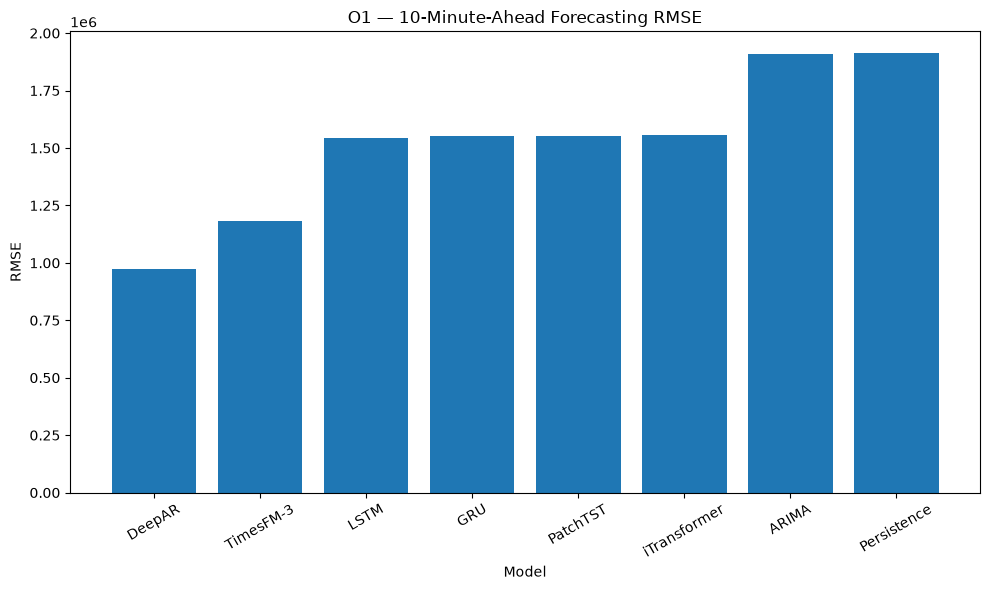

In [104]:
# ============================================================
# CELL 42 — RMSE COMPARISON
# ============================================================

plot_df = final_benchmark.copy()

plt.figure(figsize=(10, 6))

plt.bar(
    plot_df["Model"],
    plot_df["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title(
    "O1 — 10-Minute-Ahead Forecasting RMSE"
)

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "o1_rmse_comparison.png",
    dpi=300
)

plt.show()

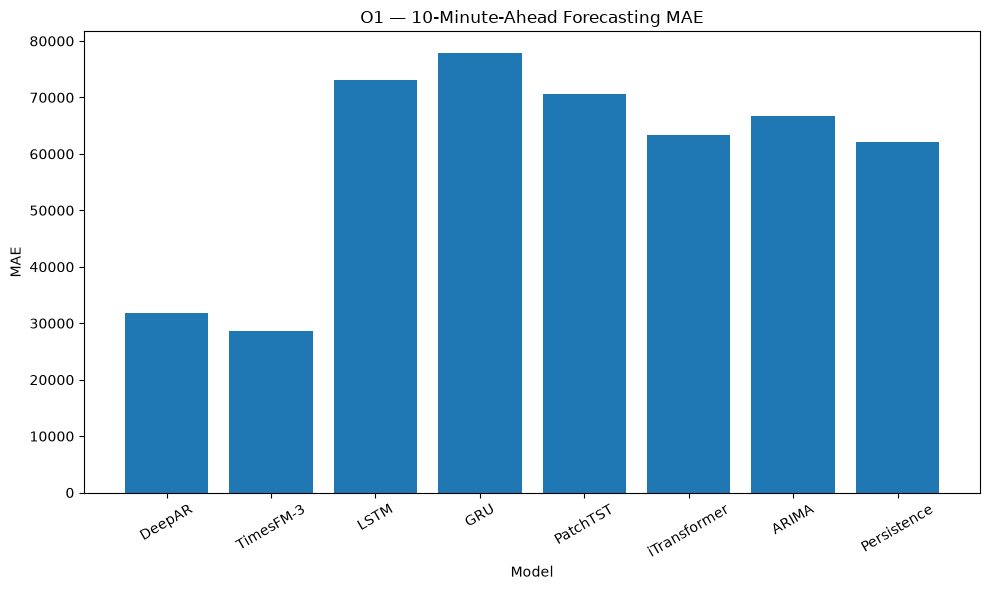

In [105]:
# ============================================================
# CELL 43 — MAE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    final_benchmark["Model"],
    final_benchmark["MAE"]
)

plt.xlabel("Model")
plt.ylabel("MAE")
plt.title(
    "O1 — 10-Minute-Ahead Forecasting MAE"
)

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "o1_mae_comparison.png",
    dpi=300
)

plt.show()

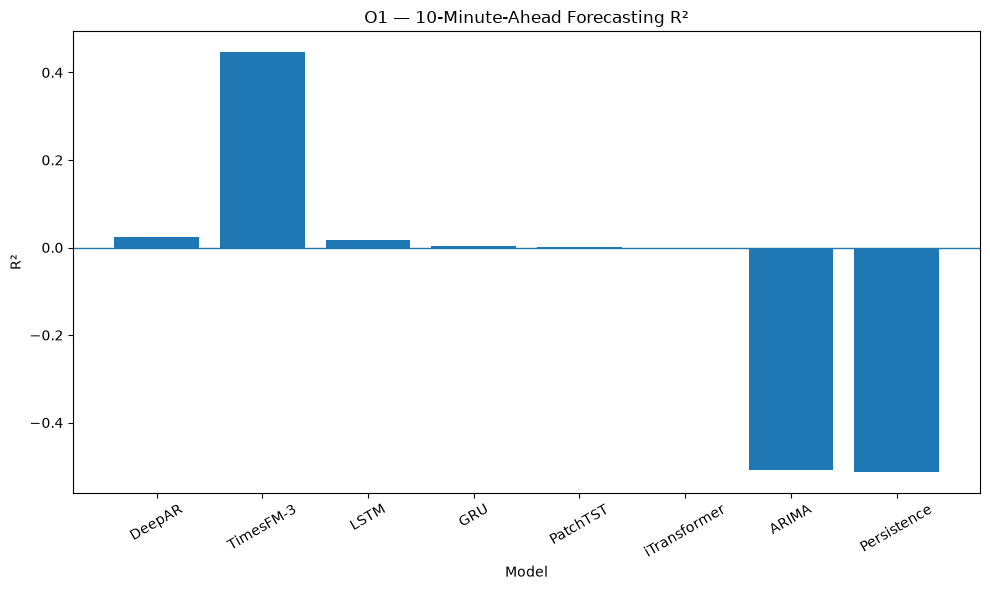

In [106]:
# ============================================================
# CELL 44 — R² COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    final_benchmark["Model"],
    final_benchmark["R2"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Model")
plt.ylabel("R²")
plt.title(
    "O1 — 10-Minute-Ahead Forecasting R²"
)

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "o1_r2_comparison.png",
    dpi=300
)

plt.show()

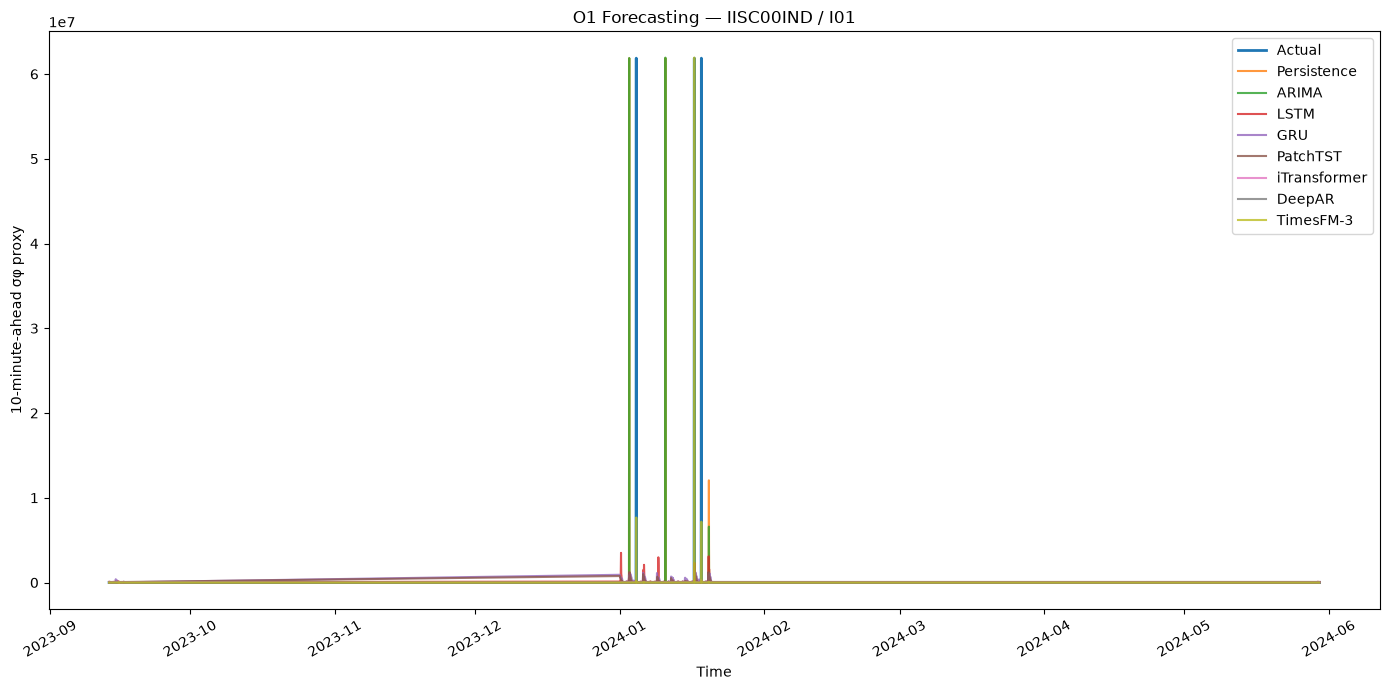

In [107]:
# ============================================================
# CELL 45 — ACTUAL VS PREDICTED
# ============================================================

REP_STATION = "IISC00IND"
REP_SV = "I01"

plot_data = final_predictions[
    (final_predictions["station"] == REP_STATION) &
    (final_predictions["sv"] == REP_SV)
].copy()

plot_data = plot_data.sort_values(
    ["model", "time"]
)

plt.figure(figsize=(14, 7))

actual_series = (
    plot_data
    .drop_duplicates("time")
    .sort_values("time")
)

plt.plot(
    actual_series["time"],
    actual_series["actual"],
    label="Actual",
    linewidth=2
)

for model_name in [
    "Persistence",
    "ARIMA",
    "LSTM",
    "GRU",
    "PatchTST",
    "iTransformer",
    "DeepAR",
    "TimesFM-3"
]:

    m = plot_data[
        plot_data["model"] == model_name
    ]

    if len(m) == 0:
        continue

    plt.plot(
        m["time"],
        m["prediction"],
        label=model_name,
        alpha=0.8
    )

plt.xlabel("Time")
plt.ylabel(
    "10-minute-ahead σφ proxy"
)

plt.title(
    f"O1 Forecasting — {REP_STATION} / {REP_SV}"
)

plt.legend()

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "o1_actual_vs_predicted_IISC_I01.png",
    dpi=300
)

plt.show()

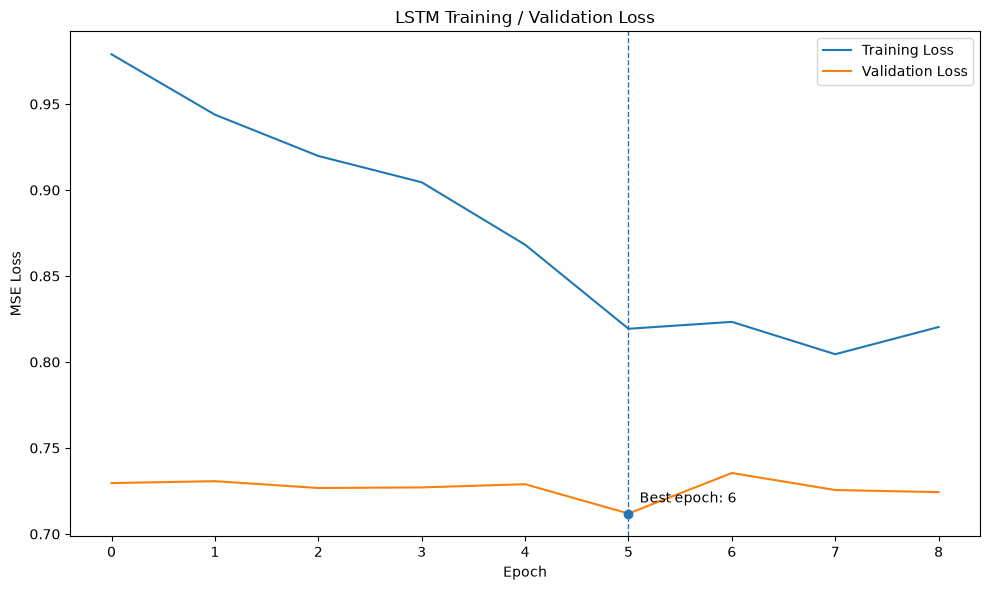

In [108]:
# ============================================================
# CELL 46 — LSTM TRAINING CURVE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    lstm_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    lstm_history.history["val_loss"],
    label="Validation Loss"
)


# Best validation epoch (1-based)
best_epoch = int(np.argmin(lstm_history.history["val_loss"]) + 1)
best_val = float(np.min(lstm_history.history["val_loss"]))
plt.axvline(best_epoch - 1, linestyle="--", linewidth=1)
plt.scatter([best_epoch - 1], [best_val], zorder=5)
plt.annotate(
    f"Best epoch: {best_epoch}",
    xy=(best_epoch - 1, best_val),
    xytext=(8, 8),
    textcoords="offset points"
)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title(
    "LSTM Training / Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "lstm_training_curve.png",
    dpi=300
)

plt.show()

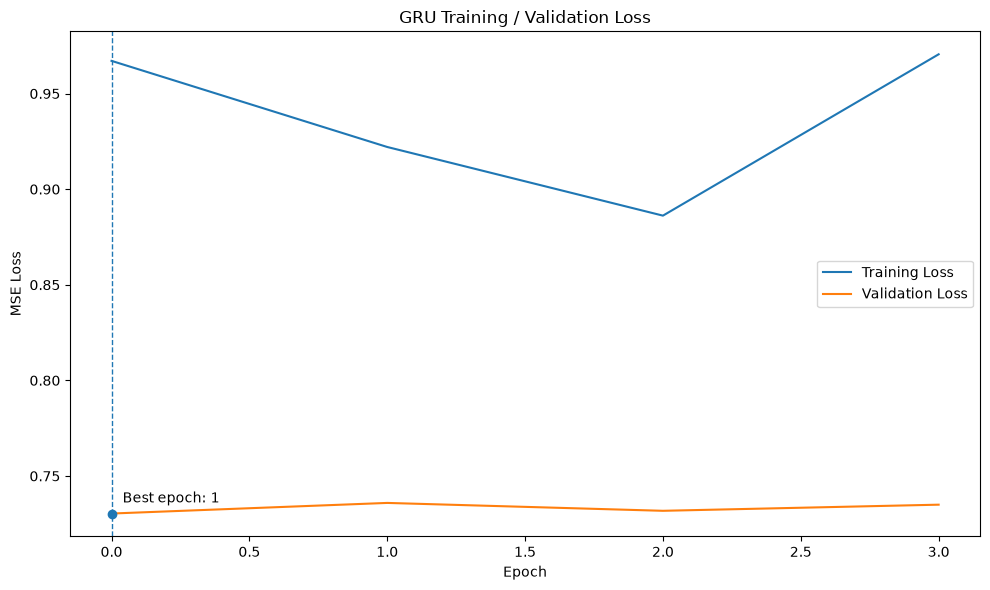

In [109]:
# ============================================================
# CELL 46B — GRU TRAINING CURVE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    gru_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    gru_history.history["val_loss"],
    label="Validation Loss"
)


# Best validation epoch (1-based)
best_epoch = int(np.argmin(gru_history.history["val_loss"]) + 1)
best_val = float(np.min(gru_history.history["val_loss"]))
plt.axvline(best_epoch - 1, linestyle="--", linewidth=1)
plt.scatter([best_epoch - 1], [best_val], zorder=5)
plt.annotate(
    f"Best epoch: {best_epoch}",
    xy=(best_epoch - 1, best_val),
    xytext=(8, 8),
    textcoords="offset points"
)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title(
    "GRU Training / Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "gru_training_curve.png",
    dpi=300
)

plt.show()

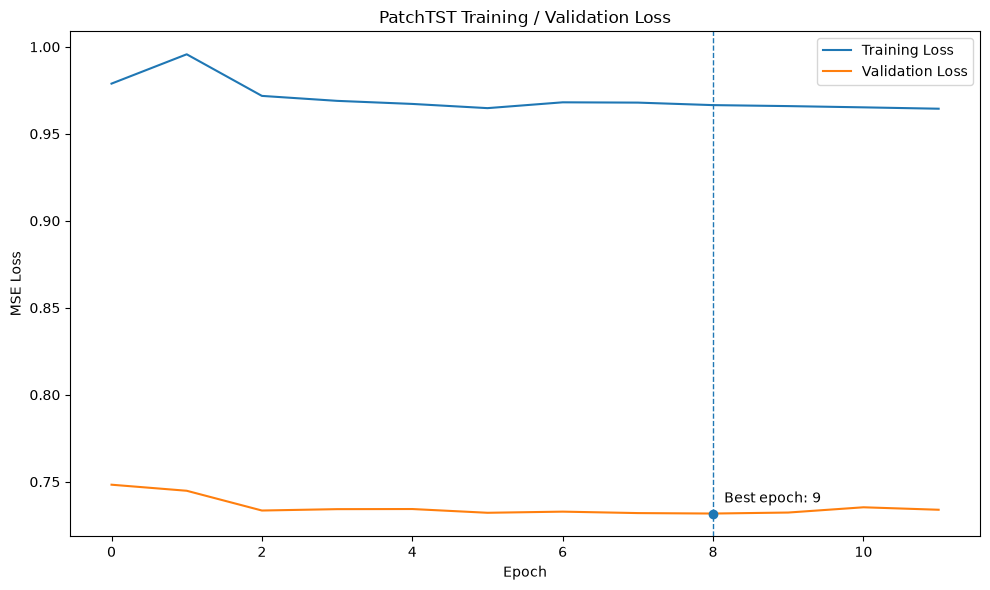

In [110]:
# ============================================================
# PATCHTST TRAINING CURVE
# ============================================================

plt.figure(figsize=(10, 6))
plt.plot(patchtst_history.history["loss"], label="Training Loss")
plt.plot(patchtst_history.history["val_loss"], label="Validation Loss")

# Best validation epoch (1-based)
best_epoch = int(np.argmin(patchtst_history.history["val_loss"]) + 1)
best_val = float(np.min(patchtst_history.history["val_loss"]))
plt.axvline(best_epoch - 1, linestyle="--", linewidth=1)
plt.scatter([best_epoch - 1], [best_val], zorder=5)
plt.annotate(
    f"Best epoch: {best_epoch}",
    xy=(best_epoch - 1, best_val),
    xytext=(8, 8),
    textcoords="offset points"
)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("PatchTST Training / Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "patchtst_training_curve.png", dpi=300)
plt.show()


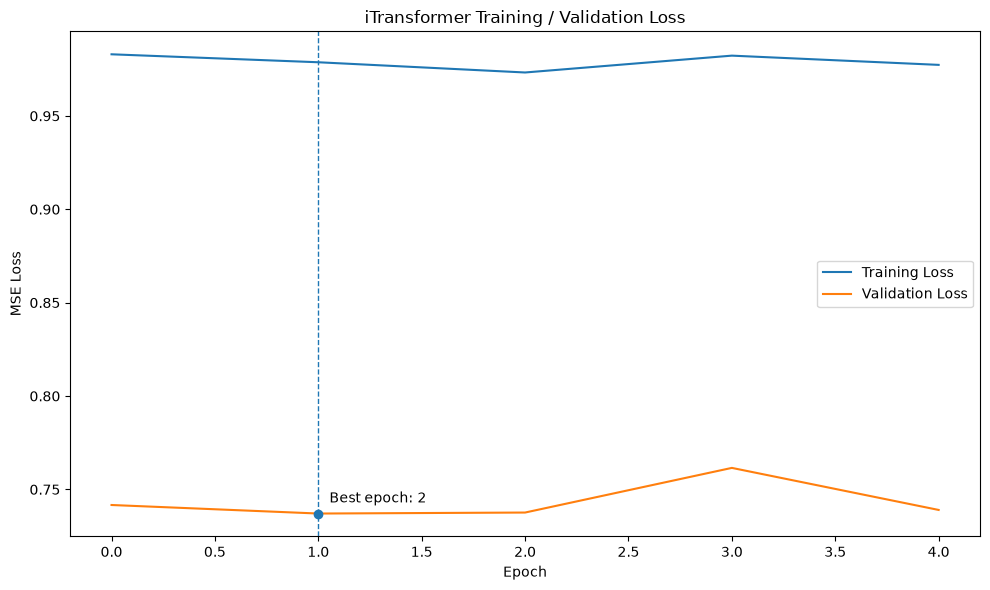

In [111]:
# ============================================================
# ITRANSFORMER TRAINING CURVE
# ============================================================

plt.figure(figsize=(10, 6))
plt.plot(itransformer_history.history["loss"], label="Training Loss")
plt.plot(itransformer_history.history["val_loss"], label="Validation Loss")

# Best validation epoch (1-based)
best_epoch = int(np.argmin(itransformer_history.history["val_loss"]) + 1)
best_val = float(np.min(itransformer_history.history["val_loss"]))
plt.axvline(best_epoch - 1, linestyle="--", linewidth=1)
plt.scatter([best_epoch - 1], [best_val], zorder=5)
plt.annotate(
    f"Best epoch: {best_epoch}",
    xy=(best_epoch - 1, best_val),
    xytext=(8, 8),
    textcoords="offset points"
)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("iTransformer Training / Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "itransformer_training_curve.png", dpi=300)
plt.show()


In [112]:
# ============================================================
# CELL — BEST EPOCH SUMMARY
# ============================================================

history_objects = {
    "LSTM": lstm_history,
    "GRU": gru_history,
    "PatchTST": patchtst_history,
    "iTransformer": itransformer_history,
}

best_epoch_rows = []
for model_name, history in history_objects.items():
    val_loss = np.asarray(history.history.get("val_loss", []), dtype=float)
    if len(val_loss) == 0:
        continue
    best_idx = int(np.nanargmin(val_loss))
    best_epoch_rows.append({
        "Model": model_name,
        "Epochs_run": len(val_loss),
        "Best_epoch": best_idx + 1,
        "Best_val_loss": float(val_loss[best_idx]),
    })

best_epoch_table = pd.DataFrame(best_epoch_rows)
print("Best validation epoch for each trainable forecasting model:")
display(best_epoch_table)

best_epoch_table.to_csv(
    OUTPUT_DIR / "best_epoch_summary.csv",
    index=False
)


Best validation epoch for each trainable forecasting model:


,Model,Epochs_run,Best_epoch,Best_val_loss
0,LSTM,9,6,0.711875
1,GRU,4,1,0.730366
2,PatchTST,12,9,0.731747
3,iTransformer,5,2,0.737071


In [113]:
# ============================================================
# CELL 47 — FINAL O1 REPORT
# ============================================================

print("=" * 90)
print("FINAL O1 — NAVIC 10-MINUTE-AHEAD FORECASTING (MAX 15 EPOCHS + EARLY STOPPING)")
print("=" * 90)

print(
    "\nDataset rows:",
    f"{len(df):,}"
)

print(
    "Study period:",
    df["time"].min(),
    "→",
    df["time"].max()
)

print(
    "Stations:",
    df["station"].nunique()
)

print(
    "NavIC satellites:",
    df["sv"].nunique()
)

print(
    "Forecast horizon:",
    "10 minutes"
)

print(
    "Sampling:",
    "30 seconds"
)

print(
    "Target:",
    TARGET_COL
)

print("\nMODEL PERFORMANCE")
print("-" * 90)

display(
    final_benchmark
)

print("\nINFERENCE LATENCY")
print("-" * 90)

display(
    latency_table
)

print("\nOUTPUT DIRECTORY")
print("-" * 90)

print(
    OUTPUT_DIR.resolve()
)

FINAL O1 — NAVIC 10-MINUTE-AHEAD FORECASTING (MAX 15 EPOCHS + EARLY STOPPING)

Dataset rows: 6,675,724
Study period: 2022-03-01 00:02:30 → 2024-05-29 23:59:30
Stations: 3
NavIC satellites: 9
Forecast horizon: 10 minutes
Sampling: 30 seconds
Target: sigma_phi_proxy

MODEL PERFORMANCE
------------------------------------------------------------------------------------------


,Model,RMSE,MAE,R2,Samples
0,DeepAR,9.716786e+05,31788.450767,0.023545,2800
1,TimesFM-3,1.180162e+06,28681.261739,0.446039,12021
2,LSTM,1.542401e+06,73017.400568,0.016125,12500
3,GRU,1.552744e+06,77819.522784,0.002885,12500
4,PatchTST,1.554243e+06,70647.401728,0.000960,12500
5,iTransformer,1.555128e+06,63275.268569,-0.000179,12500
6,ARIMA,1.910045e+06,66790.025802,-0.508803,12500
7,Persistence,1.912103e+06,62120.292422,-0.512056,12500



INFERENCE LATENCY
------------------------------------------------------------------------------------------


,Model,Total_seconds,Microseconds_per_sample
0,Persistence,16.979491,1358.359312
1,ARIMA,1412.894523,113031.561832
2,LSTM,1.036263,82.901072
3,GRU,0.888849,71.107880
4,PatchTST,0.994068,79.525440
5,iTransformer,2.092270,167.381608
6,DeepAR,1385.754074,494912.169321
7,TimesFM-3,6465.311719,537834.765777



OUTPUT DIRECTORY
------------------------------------------------------------------------------------------
D:\My Files\A7-A\Kaushik\M.Tech-AI-CB.SC.P2AIE25030\CB.SC.P2AIE25030-Project\Code\Proto-7\navic_o1\results\o1_full_dataset


In [95]:
!pip install "timesfm[torch]"


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [96]:
# ============================================================
# CELL 30C — OPTIONAL TIMESFM-3 ZERO-SHOT BENCHMARK
# ============================================================
# Current TimesFM-3 package/API (2026):
#   pip install "timesfm[torch]"
#
# This benchmark uses the historical sigma_phi_proxy series only.
# It is intentionally zero-shot and is NOT trained for 10 epochs.

RUN_TIMESFM3 = True

timesfm3_pred = pd.DataFrame(
    columns=[
        "model", "station", "sv", "time",
        "condition", "actual", "prediction"
    ]
)
timesfm3_inference_time = 0.0

if RUN_TIMESFM3:
    try:
        import torch
        from timesfm3 import TimesFM3Evaluator, ModelConfig

        device = "cuda" if torch.cuda.is_available() else "cpu"
        tfm_config = ModelConfig(
            checkpoint_path="google/timesfm-3.0-pytorch",
            per_core_batch_size=16,
            device=device
        )
        timesfm3_forecaster = TimesFM3Evaluator(tfm_config)

        tfm_records = []
        tfm_start = time.perf_counter()

        for key, origins in eval_origins.groupby(GROUP_COLS, sort=False):
            station, sv = key
            ga = group_arrays[key]

            row_ids = ga["row_id"]

            for _, row in origins.iterrows():
                matches = np.where(row_ids == row["row_id"])[0]
                if len(matches) == 0:
                    continue

                pos = int(matches[0])
                if pos < LOOKBACK:
                    continue

                context = ga["target_raw"][pos-LOOKBACK:pos].astype(np.float32)
                if not np.all(np.isfinite(context)):
                    continue

                out = next(timesfm3_forecaster.predict_batch(
                    [context],
                    horizon=FORECAST_HORIZON,
                    return_quantiles=False,
                    use_symmetric_averaging=False
                ))

                pred_value = float(np.asarray(out.forecast).reshape(-1)[-1])

                tfm_records.append({
                    "model": "TimesFM-3",
                    "station": station,
                    "sv": sv,
                    "time": row["time"],
                    "condition": row["condition"],
                    "actual": row["actual"],
                    "prediction": pred_value
                })

        timesfm3_inference_time = time.perf_counter() - tfm_start
        timesfm3_pred = pd.DataFrame(tfm_records)
        print("TimesFM-3 predictions:", len(timesfm3_pred))
        print("TimesFM-3 inference time:", timesfm3_inference_time, "seconds")

    except Exception as e:
        print("TimesFM-3 was not run successfully:")
        print(type(e).__name__, e)
        print('Install with: pip install "timesfm[torch]"')
else:
    print("TimesFM-3 is disabled. Set RUN_TIMESFM3 = True to enable the optional zero-shot benchmark.")


config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.32GB            

model.safetensors: downloading bytes:           |  0.00B            

TimesFM-3 predictions: 12021
TimesFM-3 inference time: 6465.311719400022 seconds


In [115]:
print("TARGET DISTRIBUTION")
print("=" * 60)

print(df["target_10min"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.995, 0.999]
))

TARGET DISTRIBUTION
count    6.649494e+06
mean     5.064134e+04
std      1.809768e+06
min      0.000000e+00
50%      5.009093e+01
90%      4.935596e+02
95%      6.253469e+02
99%      2.333780e+04
99.5%    3.240978e+04
99.9%    2.206057e+05
max      3.553480e+08
Name: target_10min, dtype: float64


In [116]:
for model_name, pred in final_predictions.groupby("model"):

    print("\n", "=" * 60)
    print(model_name)

    print("Actual:")
    print(pred["actual"].describe(
        percentiles=[0.90, 0.95, 0.99, 0.995, 0.999]
    ))

    print("Prediction:")
    print(pred["prediction"].describe(
        percentiles=[0.90, 0.95, 0.99, 0.995, 0.999]
    ))


ARIMA
Actual:
count    1.250000e+04
mean     4.167371e+04
std      1.555051e+06
min      0.000000e+00
50%      6.810968e+01
90%      2.855509e+03
95%      1.294599e+04
99%      3.712097e+04
99.5%    4.523629e+04
99.9%    2.506739e+05
max      6.186667e+07
Name: actual, dtype: float64
Prediction:
count    1.250000e+04
mean     2.803717e+04
std      1.108715e+06
min     -2.895329e+03
50%      1.662844e+02
90%      1.140906e+04
95%      3.324375e+04
99%      1.509821e+05
99.5%    1.677553e+05
99.9%    2.407169e+05
max      6.192990e+07
Name: prediction, dtype: float64

DeepAR
Actual:
count    2.800000e+03
mean     3.099064e+04
std      9.834993e+05
min      2.515624e-01
50%      2.475234e+02
90%      6.261465e+03
95%      8.829474e+03
99%      2.513375e+04
99.5%    3.476242e+04
99.9%    2.657395e+06
max      4.321788e+07
Name: actual, dtype: float64
Prediction:
count    2.800000e+03
mean     6.918445e+02
std      1.116380e+05
min     -5.291918e+06
50%      2.808405e+02
90%      3.519387e

In [117]:
# ============================================================
# O1 EXTENDED VISUALIZATION SUITE
# No model retraining required
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from statsmodels.graphics.tsaplots import plot_acf
    HAS_ACF = True
except Exception:
    HAS_ACF = False

REP_STATION = "IISC00IND"
REP_SV = "I01"

# 180 samples × 30 seconds = 90 minutes
PLOT_POINTS = 180
PLOT_START_INDEX = 0

MODEL_ORDER = [
    "Persistence",
    "ARIMA",
    "LSTM",
    "GRU",
    "PatchTST",
    "iTransformer",
    "DeepAR",
    "TimesFM-3",
]

available_models = [
    m for m in MODEL_ORDER
    if m in final_predictions["model"].unique()
]

print("Models available:", available_models)
print("Representative series:", REP_STATION, "/", REP_SV)

Models available: ['Persistence', 'ARIMA', 'LSTM', 'GRU', 'PatchTST', 'iTransformer', 'DeepAR', 'TimesFM-3']
Representative series: IISC00IND / I01


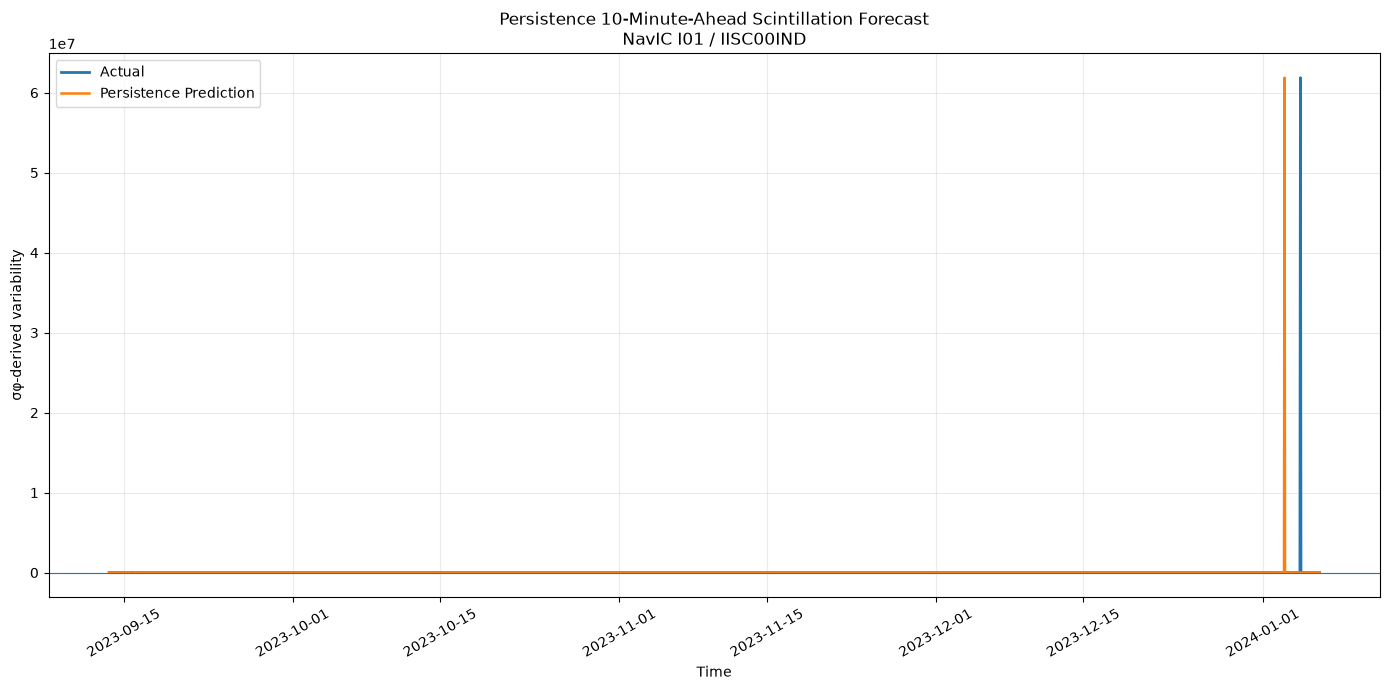

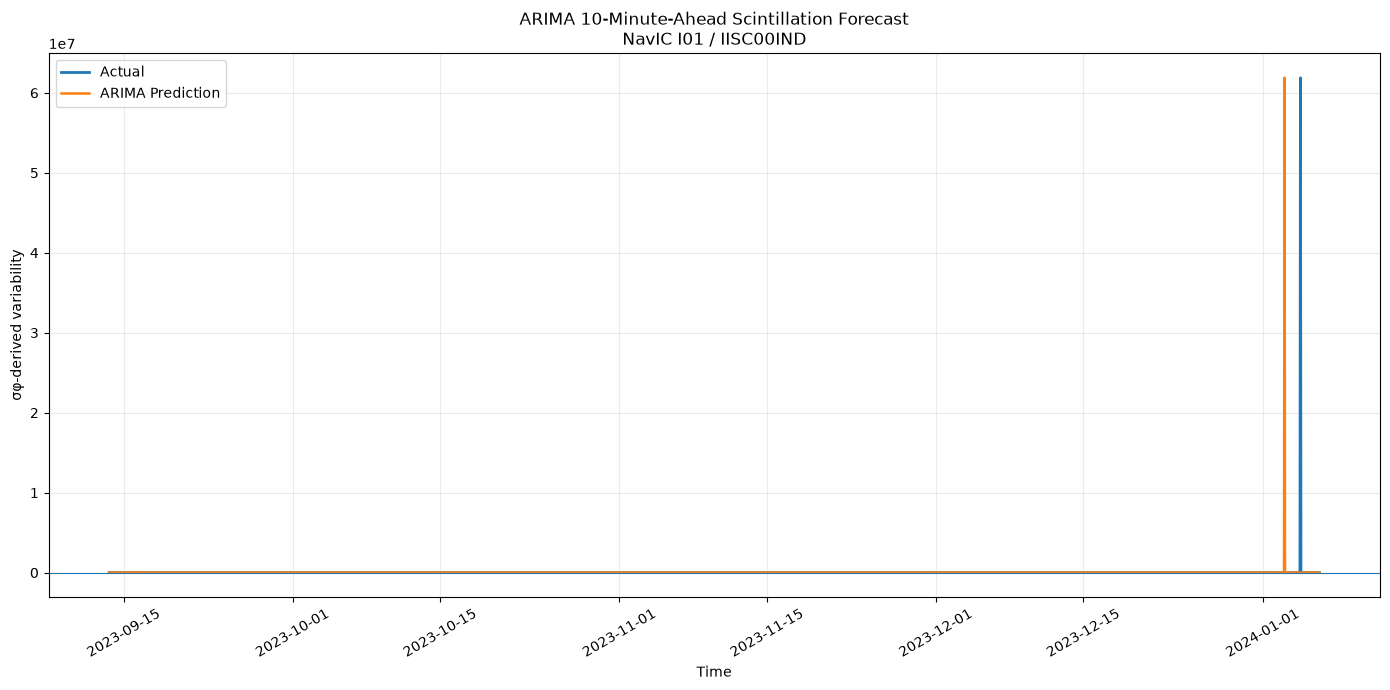

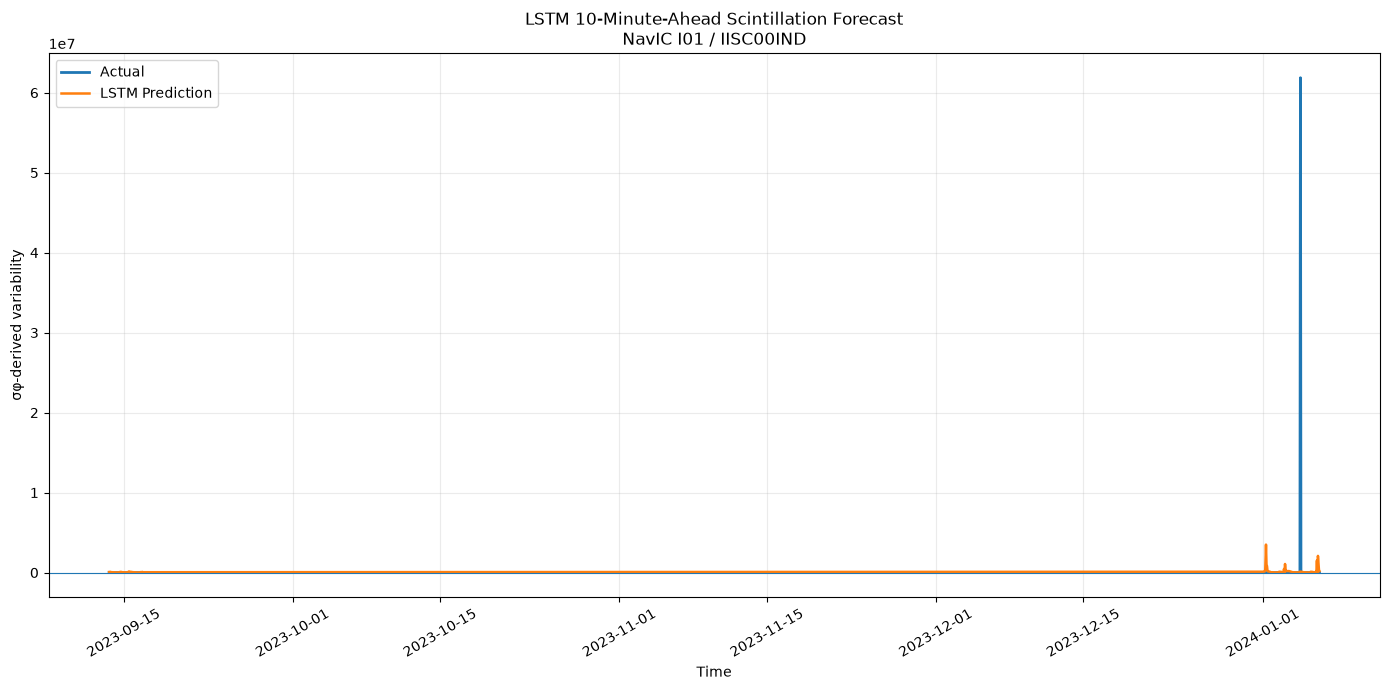

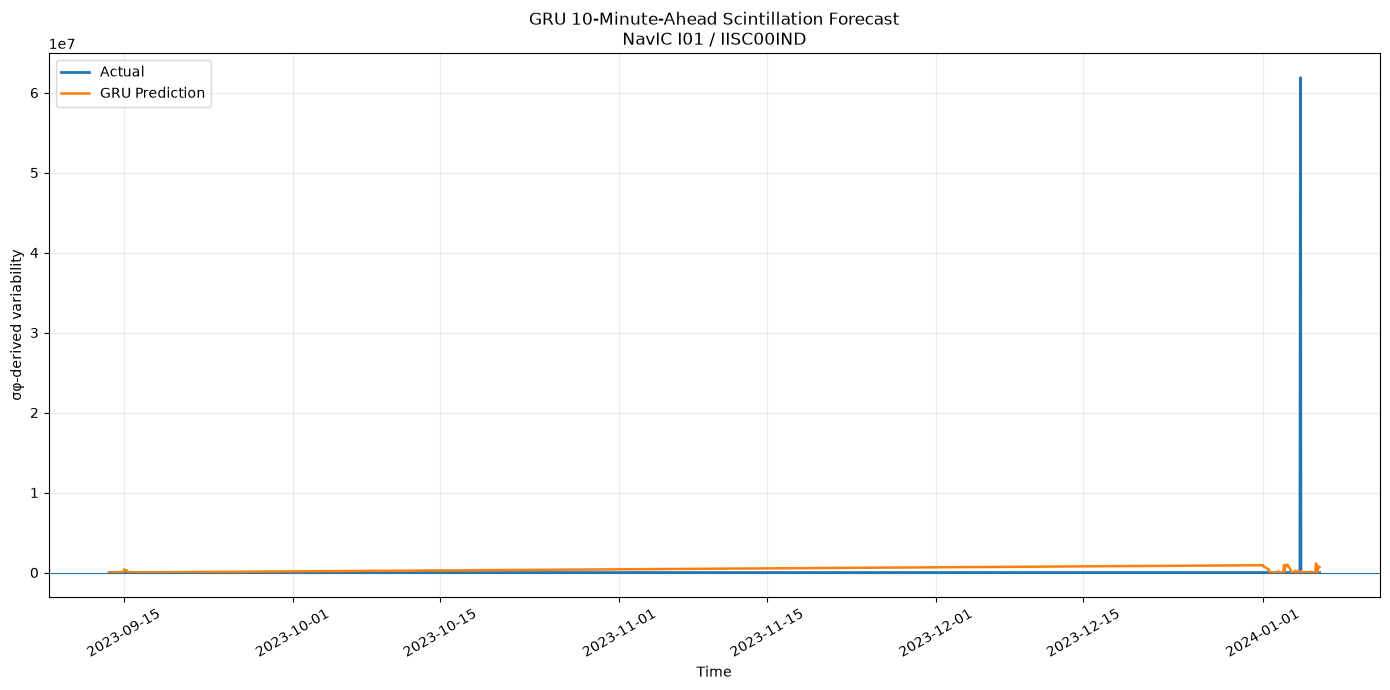

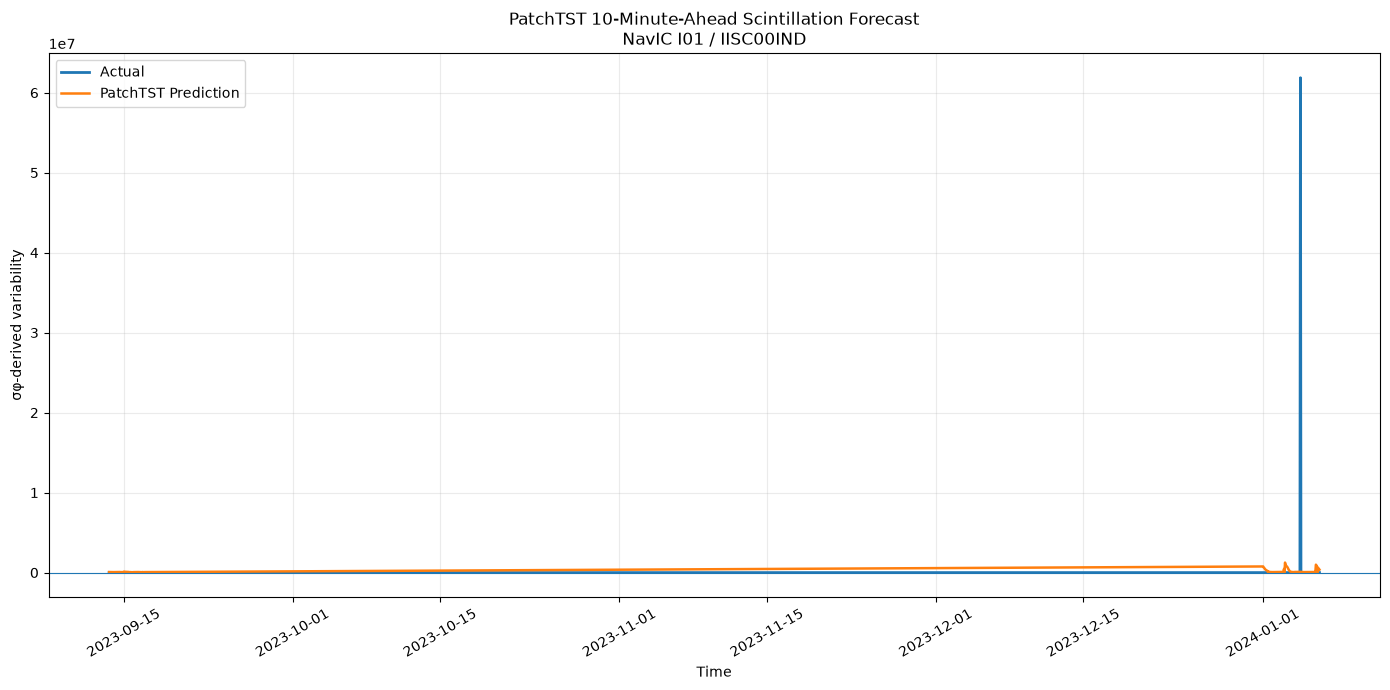

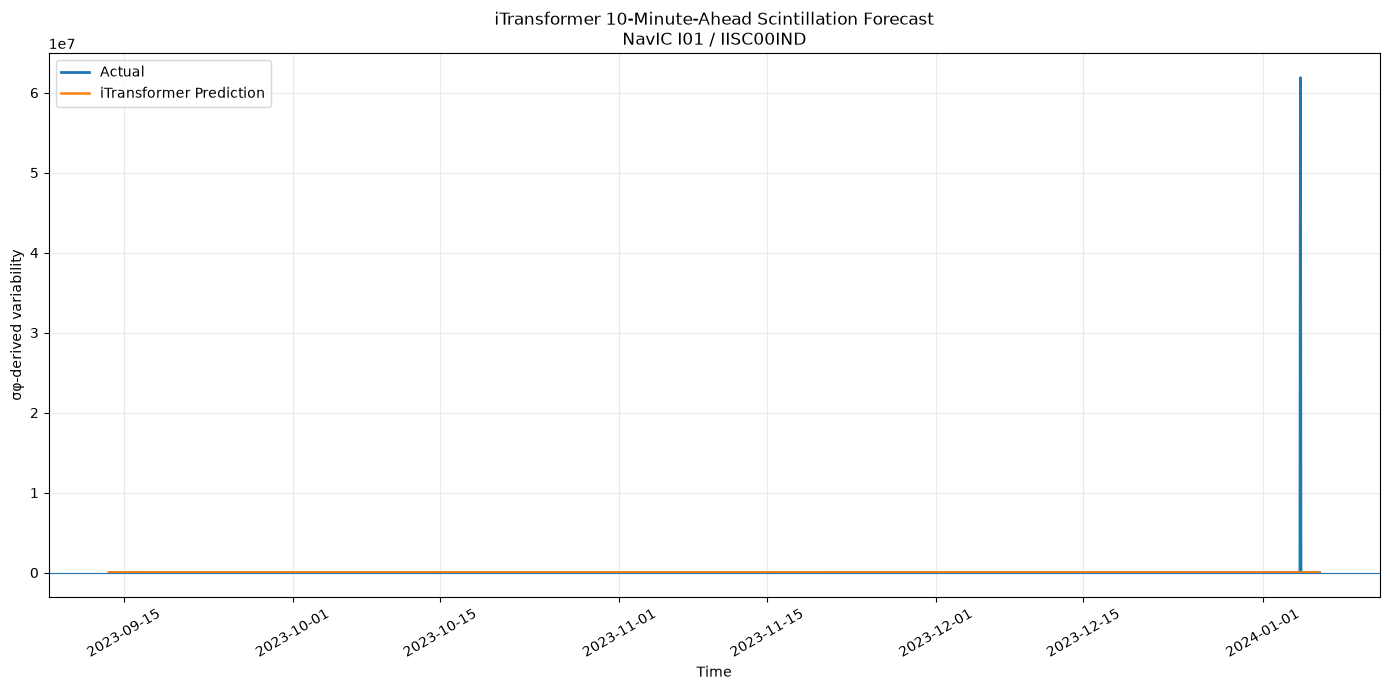

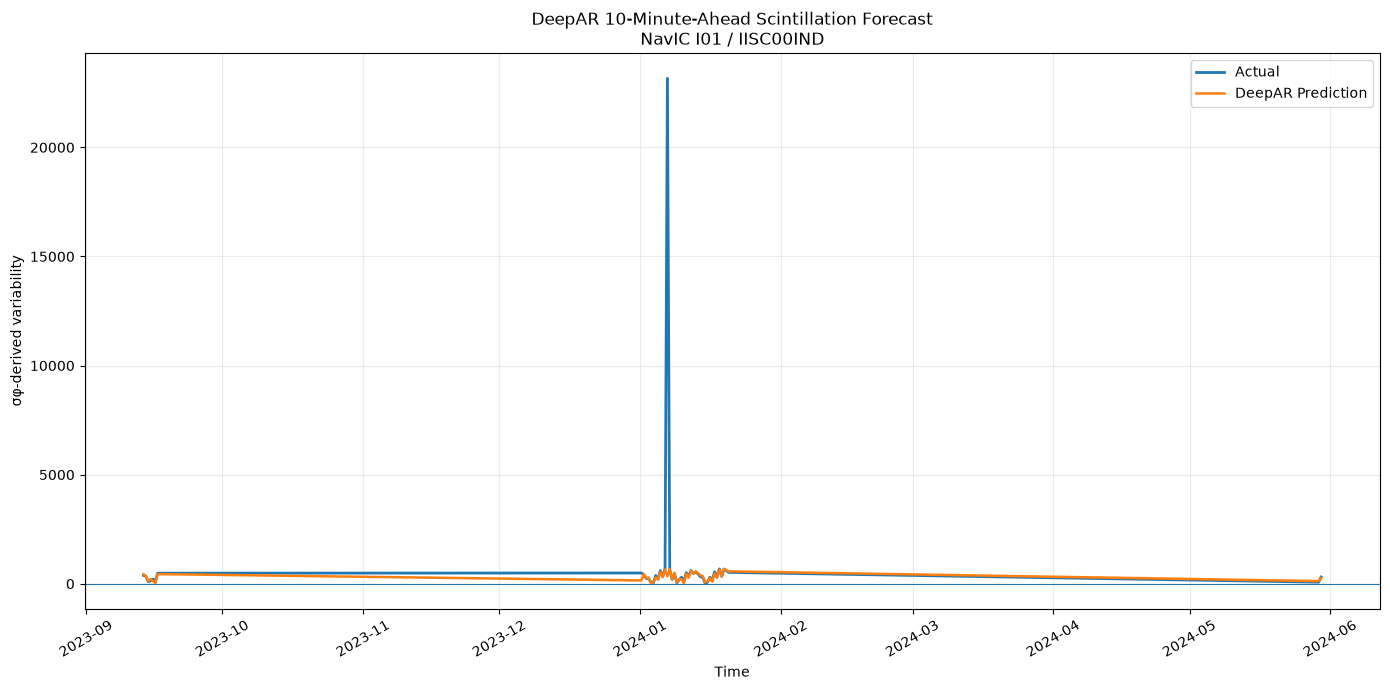

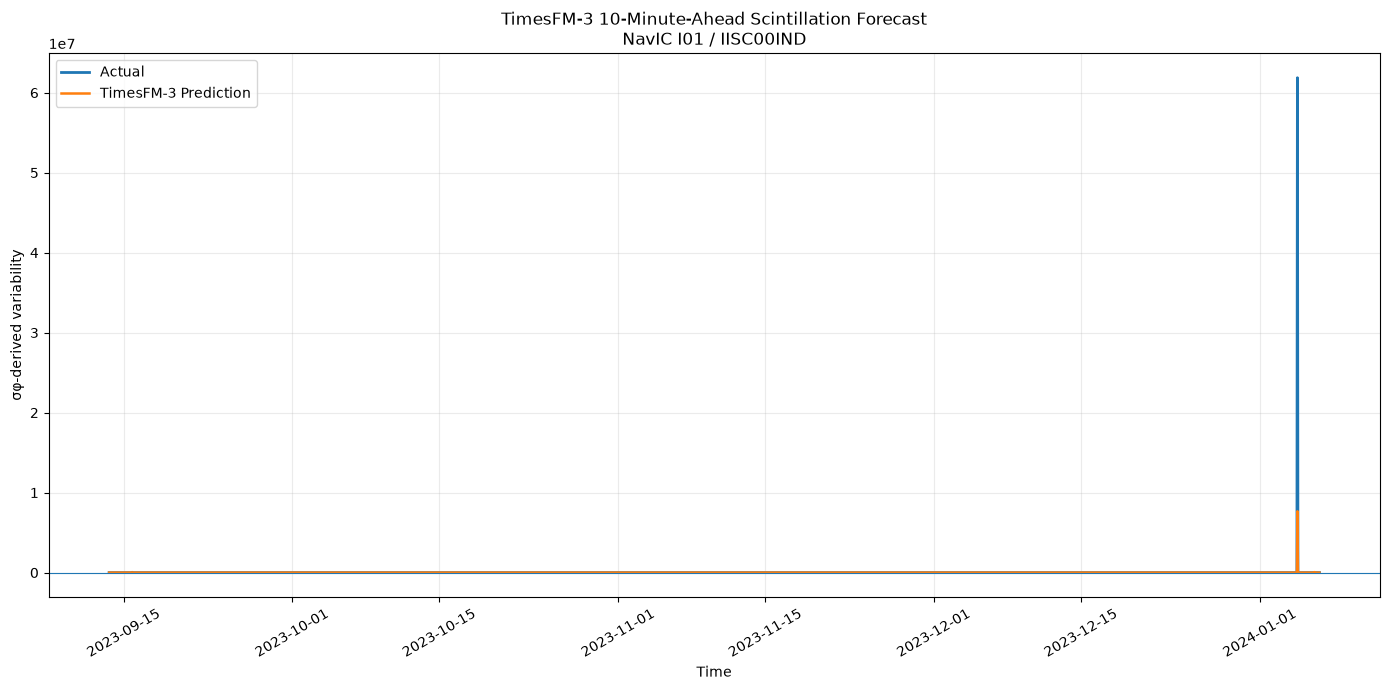

In [118]:
# ============================================================
# ACTUAL VS PREDICTED — ONE GRAPH PER MODEL
# ============================================================

rep = final_predictions[
    (final_predictions["station"] == REP_STATION) &
    (final_predictions["sv"] == REP_SV)
].copy()

rep["time"] = pd.to_datetime(rep["time"])
rep = rep.sort_values("time")

for model_name in available_models:

    m = rep[rep["model"] == model_name].copy()

    if m.empty:
        continue

    m = m.iloc[
        PLOT_START_INDEX:PLOT_START_INDEX + PLOT_POINTS
    ]

    if m.empty:
        continue

    plt.figure(figsize=(14, 7))

    plt.plot(
        m["time"],
        m["actual"],
        label="Actual",
        linewidth=2
    )

    plt.plot(
        m["time"],
        m["prediction"],
        label=f"{model_name} Prediction",
        linewidth=1.8
    )

    plt.axhline(0, linewidth=0.8)

    plt.xlabel("Time")
    plt.ylabel("σφ-derived variability")

    plt.title(
        f"{model_name} 10-Minute-Ahead Scintillation Forecast\n"
        f"NavIC {REP_SV} / {REP_STATION}"
    )

    plt.legend()
    plt.xticks(rotation=30)
    plt.grid(True, alpha=0.25)
    plt.tight_layout()

    safe_name = (
        model_name
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    plt.savefig(
        OUTPUT_DIR /
        f"forecast_trace_{safe_name}_{REP_STATION}_{REP_SV}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

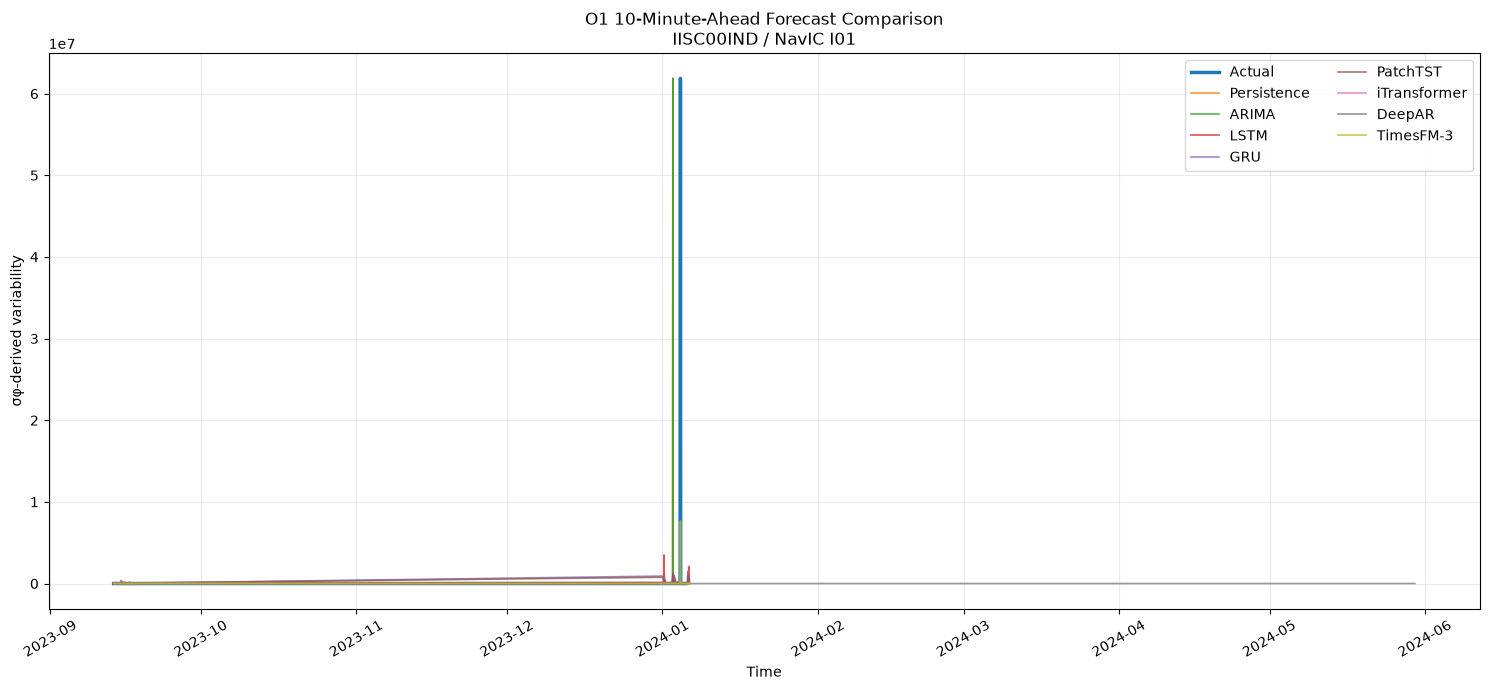

In [119]:
# ============================================================
# ALL-MODEL FORECAST OVERLAY
# ============================================================

rep = final_predictions[
    (final_predictions["station"] == REP_STATION) &
    (final_predictions["sv"] == REP_SV)
].copy()

rep["time"] = pd.to_datetime(rep["time"])

actual = (
    rep[["time", "actual"]]
    .drop_duplicates("time")
    .sort_values("time")
    .iloc[
        PLOT_START_INDEX:PLOT_START_INDEX + PLOT_POINTS
    ]
)

plt.figure(figsize=(15, 7))

plt.plot(
    actual["time"],
    actual["actual"],
    label="Actual",
    linewidth=2.5
)

for model_name in available_models:

    m = (
        rep[rep["model"] == model_name]
        .sort_values("time")
        .iloc[
            PLOT_START_INDEX:PLOT_START_INDEX + PLOT_POINTS
        ]
    )

    if not m.empty:

        plt.plot(
            m["time"],
            m["prediction"],
            label=model_name,
            alpha=0.8,
            linewidth=1.2
        )

plt.xlabel("Time")
plt.ylabel("σφ-derived variability")

plt.title(
    f"O1 10-Minute-Ahead Forecast Comparison\n"
    f"{REP_STATION} / NavIC {REP_SV}"
)

plt.legend(ncol=2)
plt.xticks(rotation=30)
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "all_models_forecast_overlay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

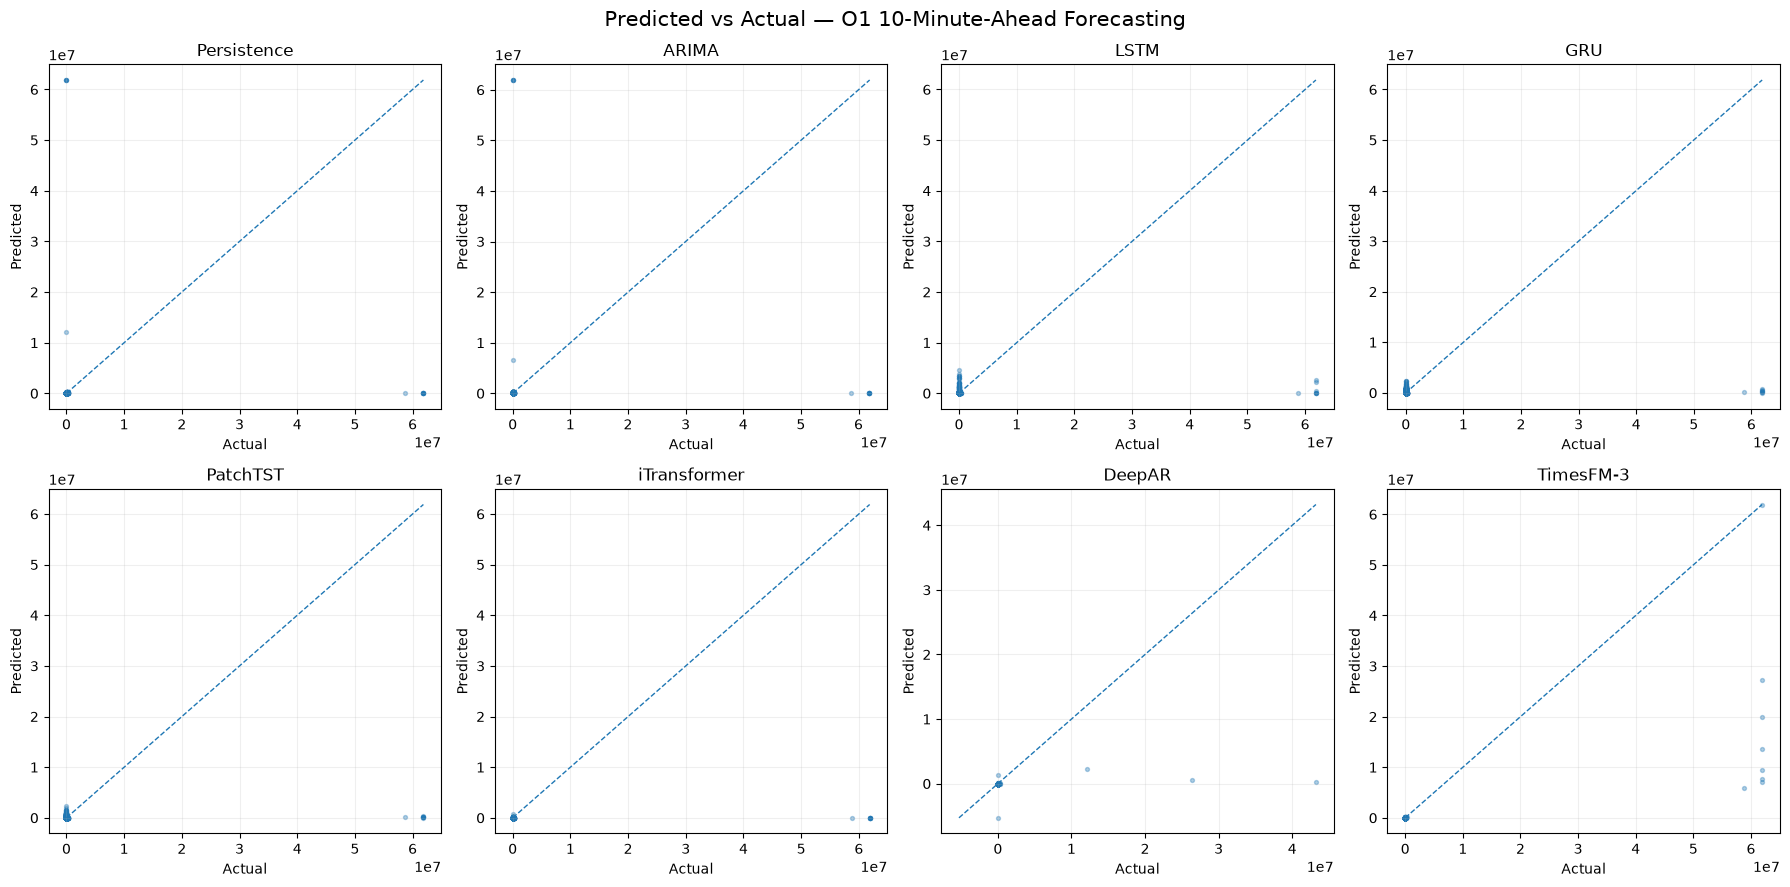

In [120]:
# ============================================================
# PREDICTED VS ACTUAL — ALL MODELS
# ============================================================

fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 9)
)

axes = axes.ravel()

for ax, model_name in zip(axes, available_models):

    g = final_predictions[
        final_predictions["model"] == model_name
    ].copy()

    g = g.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna(
        subset=["actual", "prediction"]
    )

    if g.empty:
        ax.set_visible(False)
        continue

    ax.scatter(
        g["actual"],
        g["prediction"],
        s=8,
        alpha=0.35
    )

    lo = min(
        g["actual"].min(),
        g["prediction"].min()
    )

    hi = max(
        g["actual"].max(),
        g["prediction"].max()
    )

    ax.plot(
        [lo, hi],
        [lo, hi],
        linestyle="--",
        linewidth=1
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.grid(True, alpha=0.2)

for ax in axes[len(available_models):]:
    ax.set_visible(False)

fig.suptitle(
    "Predicted vs Actual — O1 10-Minute-Ahead Forecasting",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "predicted_vs_actual_all_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

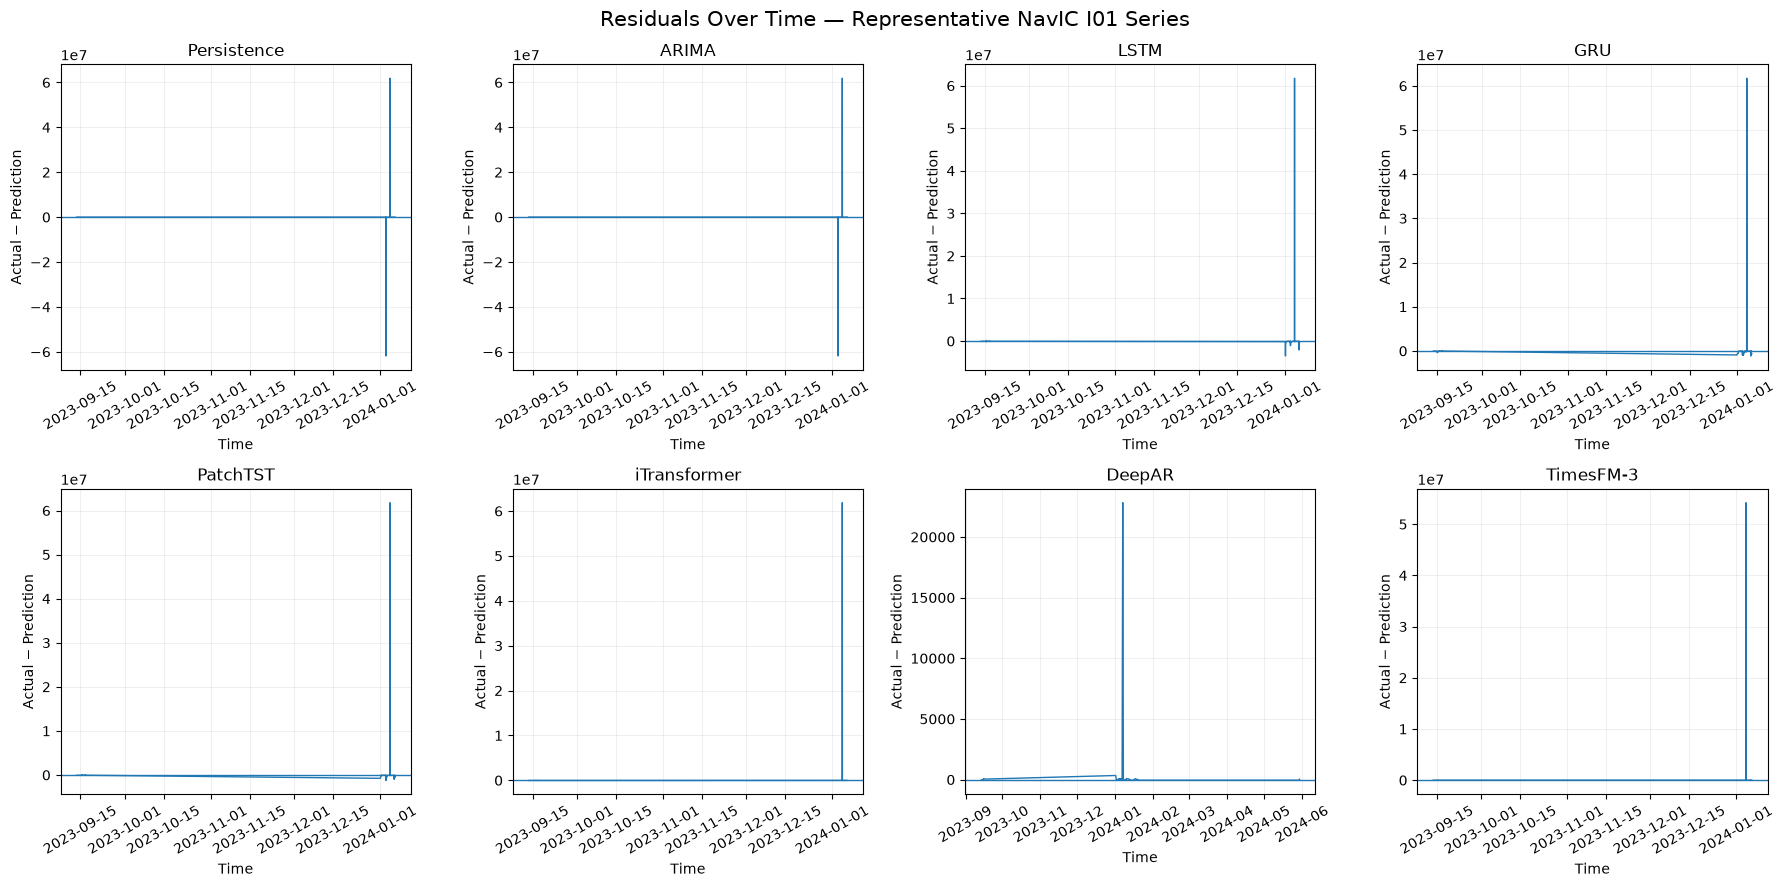

In [121]:
# ============================================================
# RESIDUALS OVER TIME
# Residual = Actual - Prediction
# ============================================================

fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 9)
)

axes = axes.ravel()

for ax, model_name in zip(axes, available_models):

    g = final_predictions[
        final_predictions["model"] == model_name
    ].copy()

    g["time"] = pd.to_datetime(g["time"])

    g["residual"] = (
        g["actual"] -
        g["prediction"]
    )

    g = g.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna(
        subset=["residual"]
    )

    # Representative IISC / I01 series
    g = g[
        (g["station"] == REP_STATION) &
        (g["sv"] == REP_SV)
    ].sort_values("time")

    g = g.iloc[
        PLOT_START_INDEX:
        PLOT_START_INDEX + PLOT_POINTS
    ]

    if g.empty:
        ax.set_visible(False)
        continue

    ax.plot(
        g["time"],
        g["residual"],
        linewidth=1
    )

    ax.axhline(
        0,
        linewidth=1
    )

    ax.set_title(model_name)
    ax.set_xlabel("Time")
    ax.set_ylabel("Actual − Prediction")

    ax.tick_params(
        axis="x",
        rotation=30
    )

    ax.grid(True, alpha=0.2)

for ax in axes[len(available_models):]:
    ax.set_visible(False)

fig.suptitle(
    "Residuals Over Time — Representative NavIC I01 Series",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "residuals_over_time_all_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

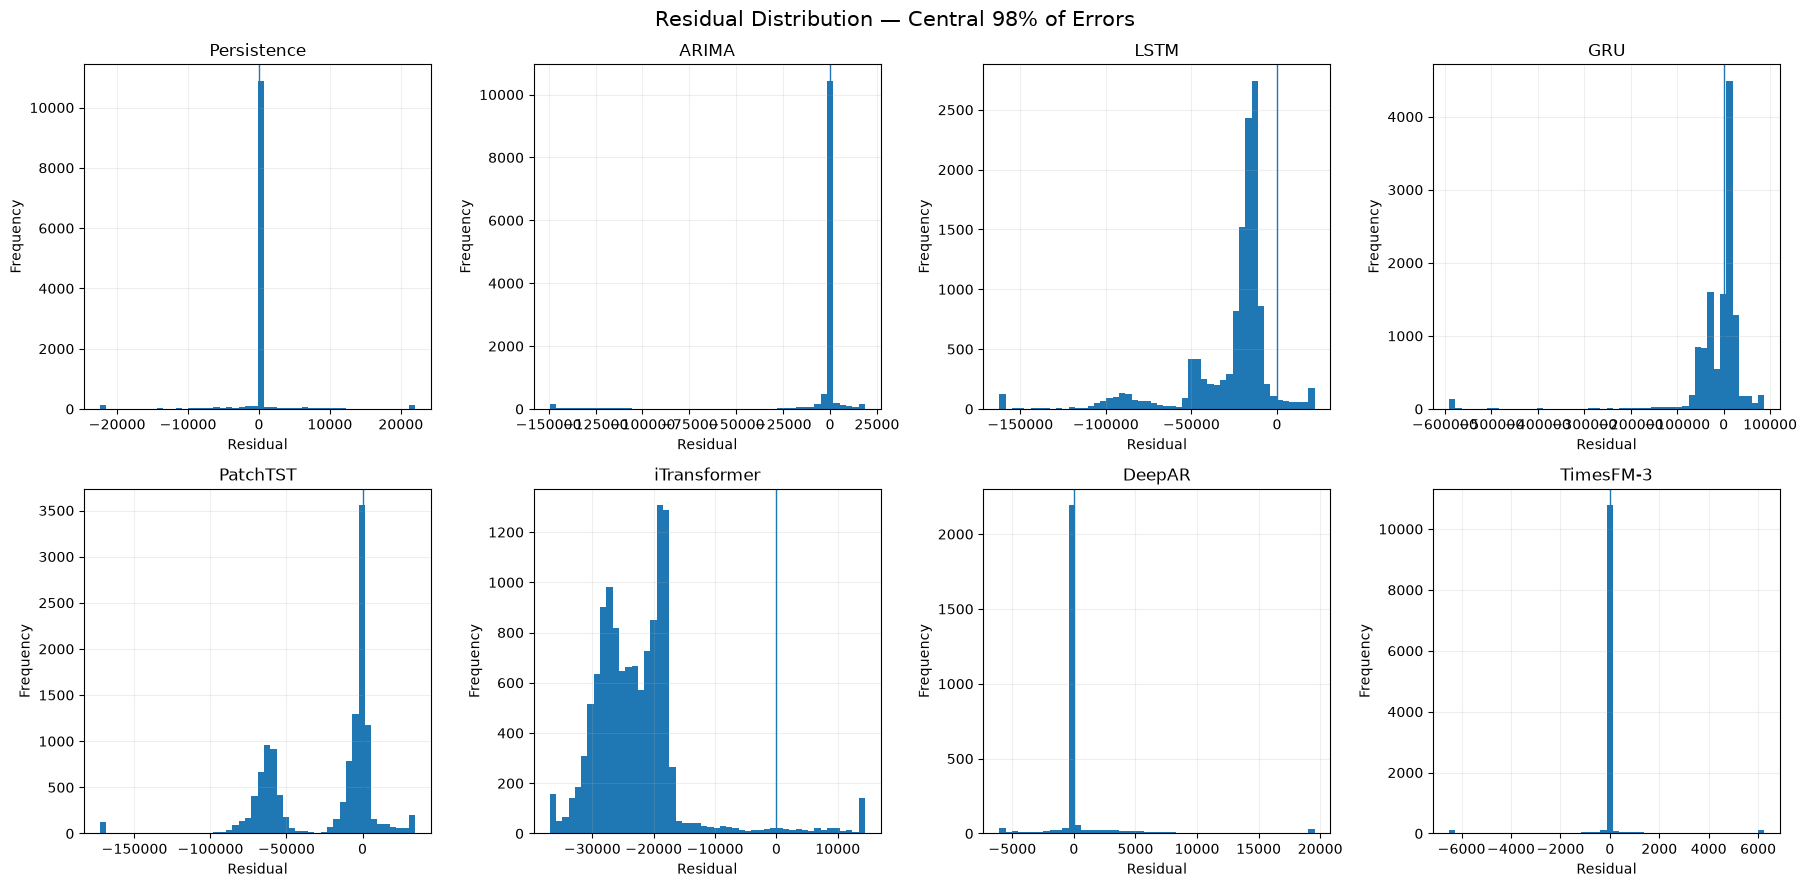

In [122]:
# ============================================================
# RESIDUAL DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 9)
)

axes = axes.ravel()

for ax, model_name in zip(axes, available_models):

    g = final_predictions[
        final_predictions["model"] == model_name
    ].copy()

    residual = (
        g["actual"] -
        g["prediction"]
    )

    residual = (
        residual
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if residual.empty:
        ax.set_visible(False)
        continue

    # Only for visualisation:
    # prevents extreme values from flattening histogram
    q_low, q_high = residual.quantile(
        [0.01, 0.99]
    )

    clipped = residual.clip(
        q_low,
        q_high
    )

    ax.hist(
        clipped,
        bins=50
    )

    ax.axvline(
        0,
        linewidth=1
    )

    ax.set_title(model_name)
    ax.set_xlabel("Residual")
    ax.set_ylabel("Frequency")

    ax.grid(True, alpha=0.2)

for ax in axes[len(available_models):]:
    ax.set_visible(False)

fig.suptitle(
    "Residual Distribution — Central 98% of Errors",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "residual_distribution_all_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

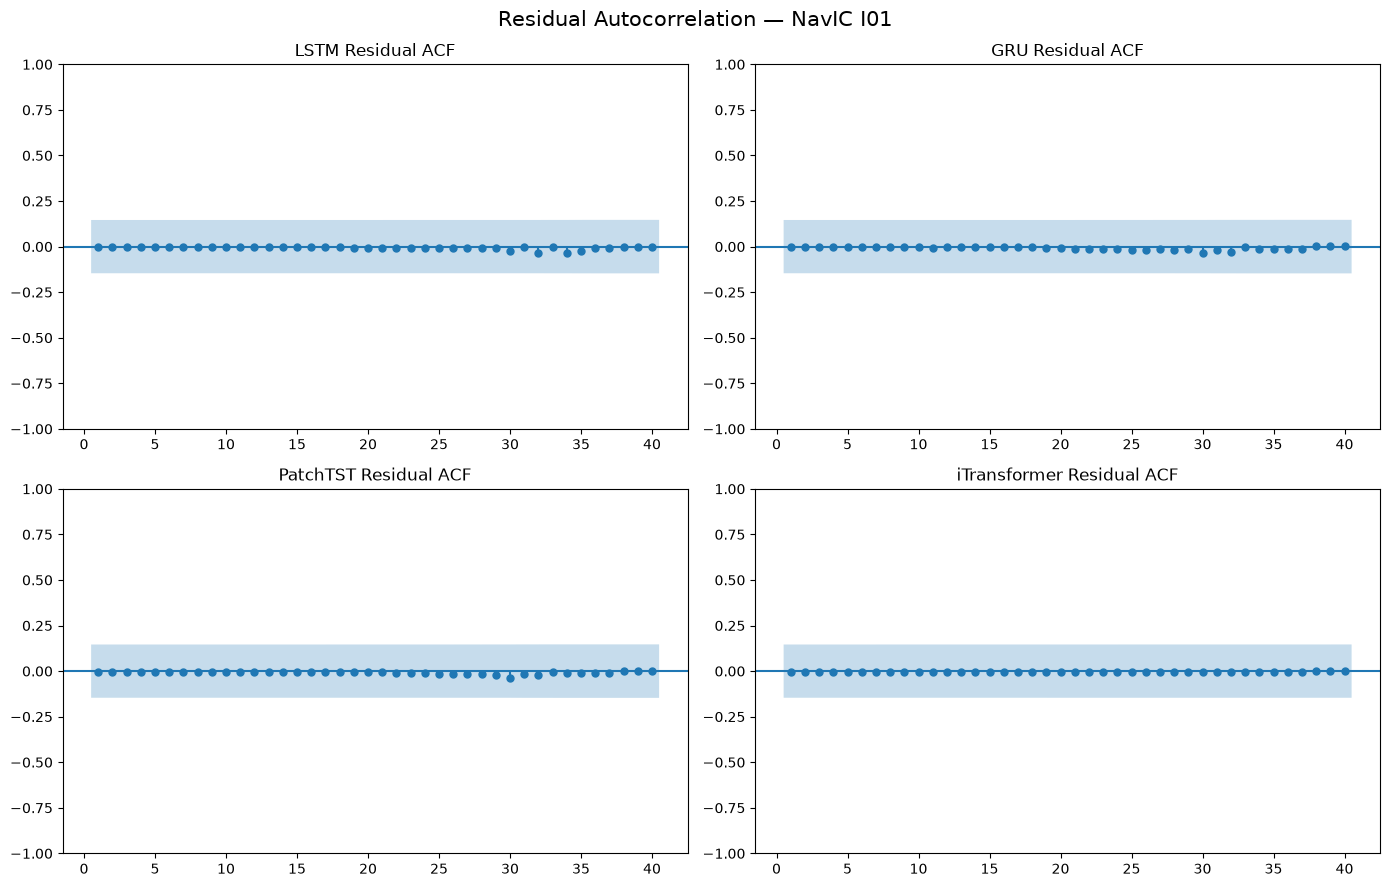

In [123]:
# ============================================================
# RESIDUAL AUTOCORRELATION
# ============================================================

if HAS_ACF:

    selected = [
        m for m in
        ["LSTM", "GRU", "PatchTST", "iTransformer"]
        if m in available_models
    ]

    fig, axes = plt.subplots(
        2, 2,
        figsize=(14, 9)
    )

    axes = np.asarray(axes).ravel()

    for ax, model_name in zip(axes, selected):

        g = final_predictions[
            final_predictions["model"] == model_name
        ].copy()

        g = g[
            (g["station"] == REP_STATION) &
            (g["sv"] == REP_SV)
        ].sort_values("time")

        residual = (
            g["actual"] -
            g["prediction"]
        )

        residual = (
            residual
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        residual = residual.iloc[:PLOT_POINTS]

        if len(residual) > 10:

            plot_acf(
                residual,
                lags=min(
                    40,
                    len(residual) // 2 - 1
                ),
                ax=ax,
                zero=False
            )

            ax.set_title(
                f"{model_name} Residual ACF"
            )

    for ax in axes[len(selected):]:
        ax.set_visible(False)

    fig.suptitle(
        "Residual Autocorrelation — NavIC I01",
        fontsize=15
    )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "residual_acf_selected_models.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:

    print(
        "statsmodels is not available. "
        "Skipping residual ACF."
    )

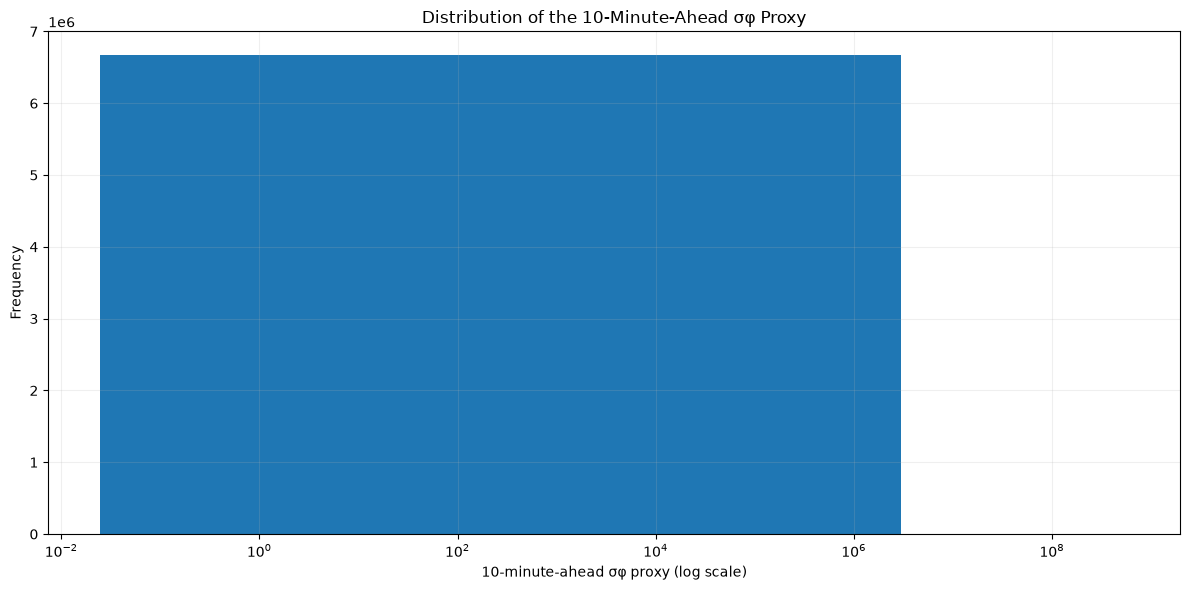

In [124]:
# ============================================================
# TARGET DISTRIBUTION
# ============================================================

x = pd.to_numeric(
    df[TARGET_COL],
    errors="coerce"
)

x = x[np.isfinite(x)]

# Remove zero values only for log-scale visualisation
x_positive = x[x > 0]

plt.figure(figsize=(12, 6))

plt.hist(
    x_positive,
    bins=200
)

plt.xscale("log")

plt.xlabel(
    "10-minute-ahead σφ proxy (log scale)"
)

plt.ylabel("Frequency")

plt.title(
    "Distribution of the 10-Minute-Ahead σφ Proxy"
)

plt.grid(
    True,
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "target_distribution_log.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

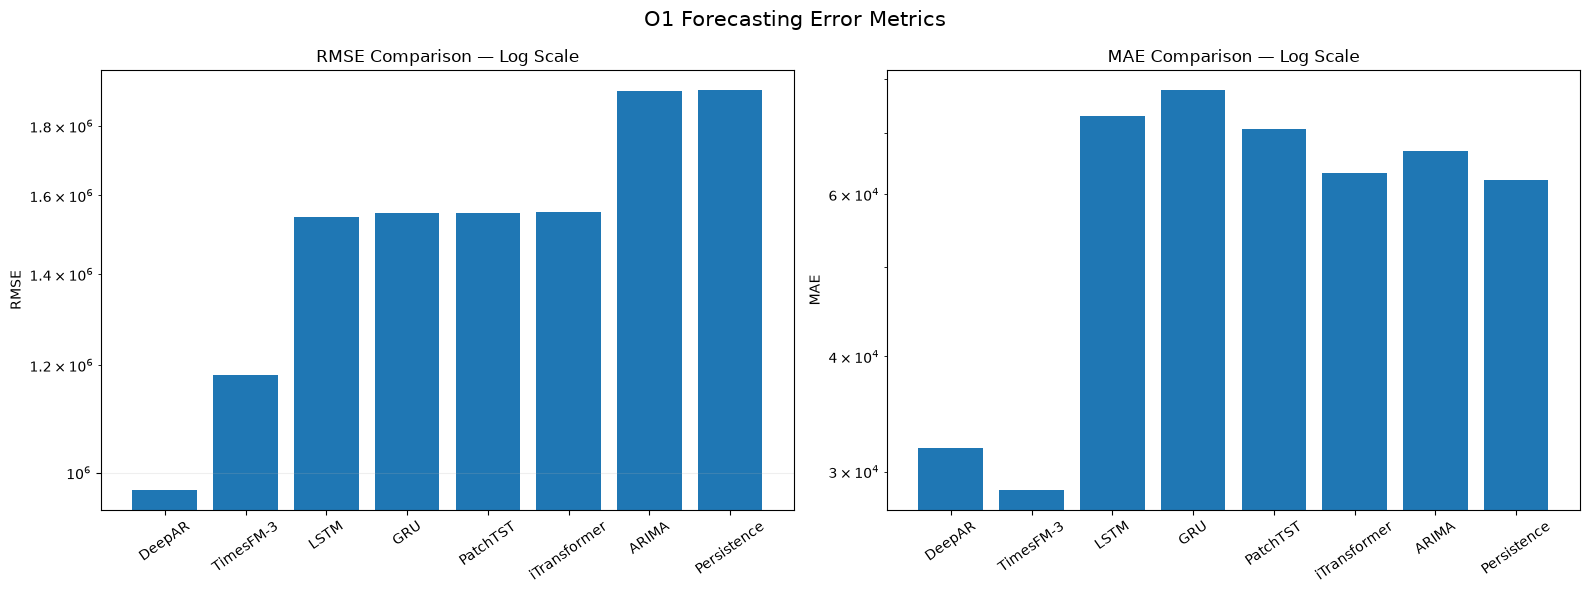

In [125]:
# ============================================================
# RMSE / MAE COMPARISON
# ============================================================

metric_plot = final_benchmark.copy()

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

# RMSE
axes[0].bar(
    metric_plot["Model"],
    metric_plot["RMSE"]
)

axes[0].set_yscale("log")

axes[0].set_title(
    "RMSE Comparison — Log Scale"
)

axes[0].set_ylabel("RMSE")

axes[0].tick_params(
    axis="x",
    rotation=35
)

axes[0].grid(
    True,
    axis="y",
    alpha=0.2
)

# MAE
axes[1].bar(
    metric_plot["Model"],
    metric_plot["MAE"]
)

axes[1].set_yscale("log")

axes[1].set_title(
    "MAE Comparison — Log Scale"
)

axes[1].set_ylabel("MAE")

axes[1].tick_params(
    axis="x",
    rotation=35
)

axes[1].grid(
    True,
    axis="y",
    alpha=0.2
)

fig.suptitle(
    "O1 Forecasting Error Metrics",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "rmse_mae_log_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

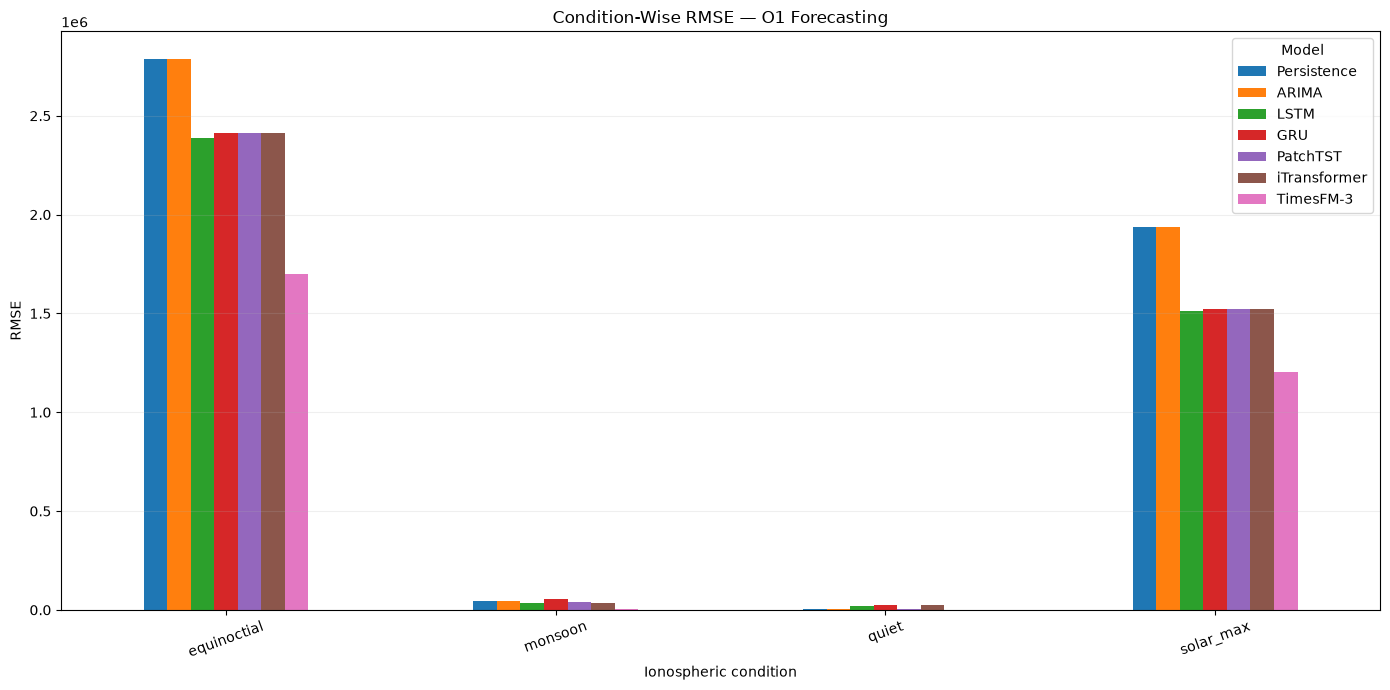

In [126]:
# ============================================================
# CONDITION-WISE RMSE
# ============================================================

if not condition_results.empty:

    cond_pivot = condition_results.pivot_table(
        index="Condition",
        columns="Model",
        values="RMSE",
        aggfunc="mean"
    )

    cond_pivot = cond_pivot[
        [
            m for m in available_models
            if m in cond_pivot.columns
        ]
    ]

    ax = cond_pivot.plot(
        kind="bar",
        figsize=(14, 7)
    )

    ax.set_xlabel(
        "Ionospheric condition"
    )

    ax.set_ylabel("RMSE")

    ax.set_title(
        "Condition-Wise RMSE — O1 Forecasting"
    )

    ax.tick_params(
        axis="x",
        rotation=20
    )

    ax.grid(
        True,
        axis="y",
        alpha=0.2
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "condition_wise_rmse.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

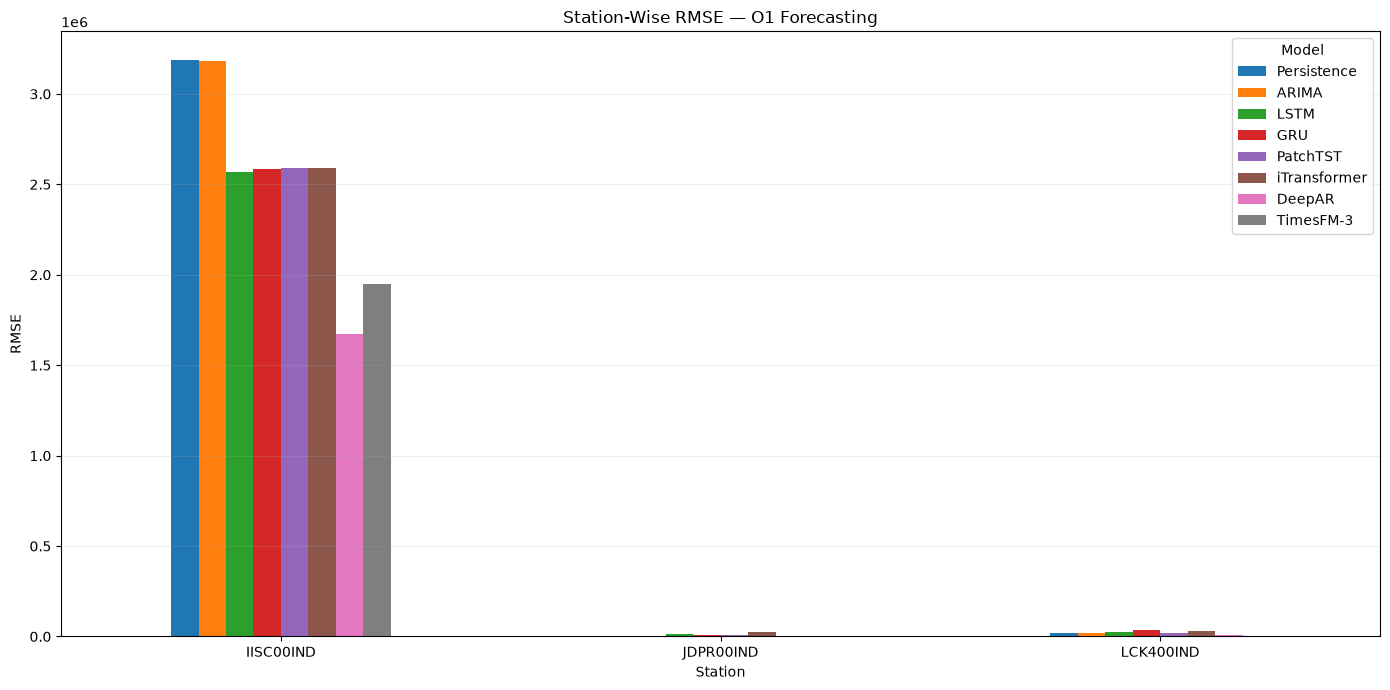

In [127]:
# ============================================================
# STATION-WISE RMSE
# ============================================================

if not station_results.empty:

    station_pivot = station_results.pivot_table(
        index="Station",
        columns="Model",
        values="RMSE",
        aggfunc="mean"
    )

    station_pivot = station_pivot[
        [
            m for m in available_models
            if m in station_pivot.columns
        ]
    ]

    ax = station_pivot.plot(
        kind="bar",
        figsize=(14, 7)
    )

    ax.set_xlabel("Station")
    ax.set_ylabel("RMSE")

    ax.set_title(
        "Station-Wise RMSE — O1 Forecasting"
    )

    ax.tick_params(
        axis="x",
        rotation=0
    )

    ax.grid(
        True,
        axis="y",
        alpha=0.2
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "station_wise_rmse.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

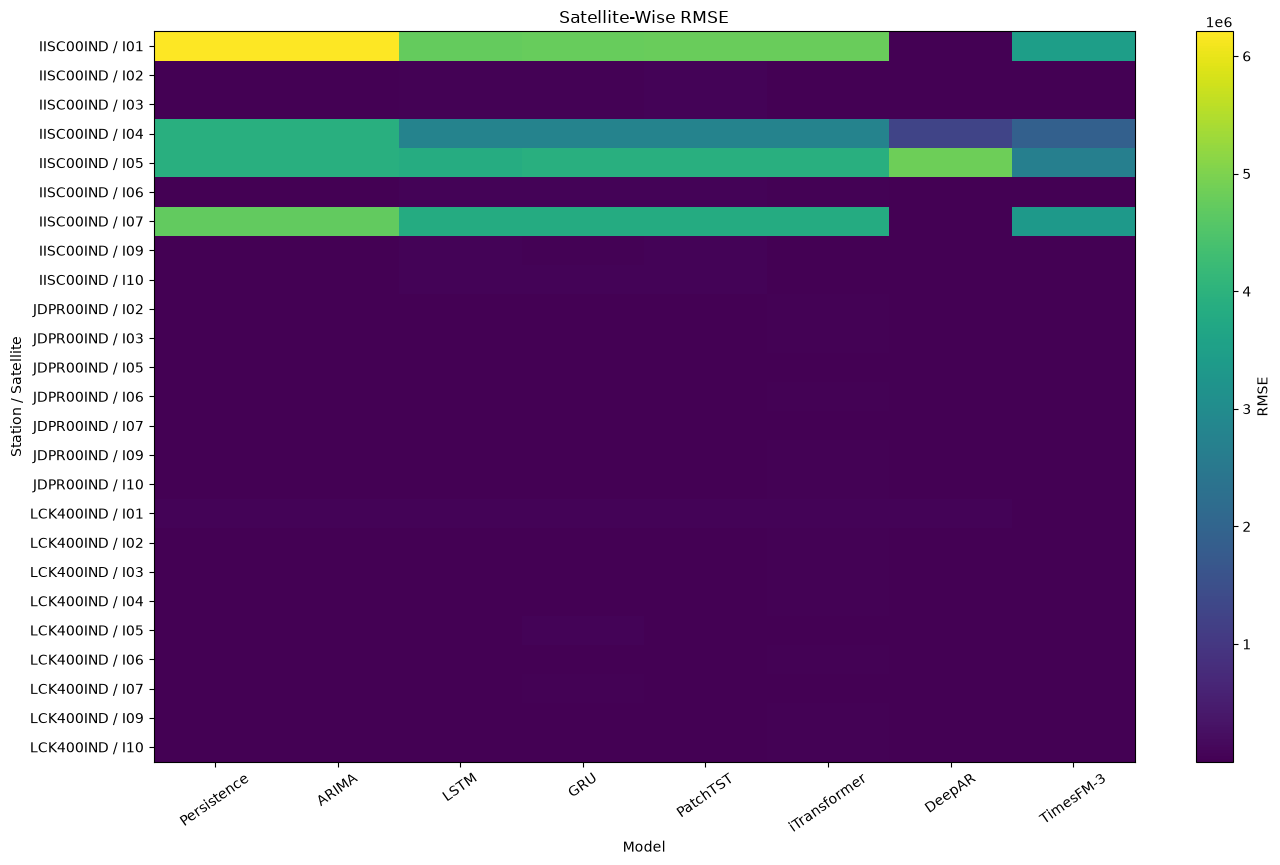

In [128]:
# ============================================================
# SATELLITE-WISE RMSE HEATMAP
# ============================================================

if not satellite_results.empty:

    sat_pivot = satellite_results.pivot_table(
        index=["Station", "Satellite"],
        columns="Model",
        values="RMSE",
        aggfunc="mean"
    )

    sat_pivot = sat_pivot[
        [
            m for m in available_models
            if m in sat_pivot.columns
        ]
    ]

    plt.figure(
        figsize=(
            14,
            max(6, 0.35 * len(sat_pivot))
        )
    )

    plt.imshow(
        sat_pivot.values,
        aspect="auto"
    )

    plt.colorbar(
        label="RMSE"
    )

    plt.xticks(
        range(len(sat_pivot.columns)),
        sat_pivot.columns,
        rotation=35
    )

    plt.yticks(
        range(len(sat_pivot.index)),
        [
            f"{station} / {sv}"
            for station, sv in sat_pivot.index
        ]
    )

    plt.xlabel("Model")
    plt.ylabel("Station / Satellite")

    plt.title(
        "Satellite-Wise RMSE"
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "satellite_wise_rmse_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

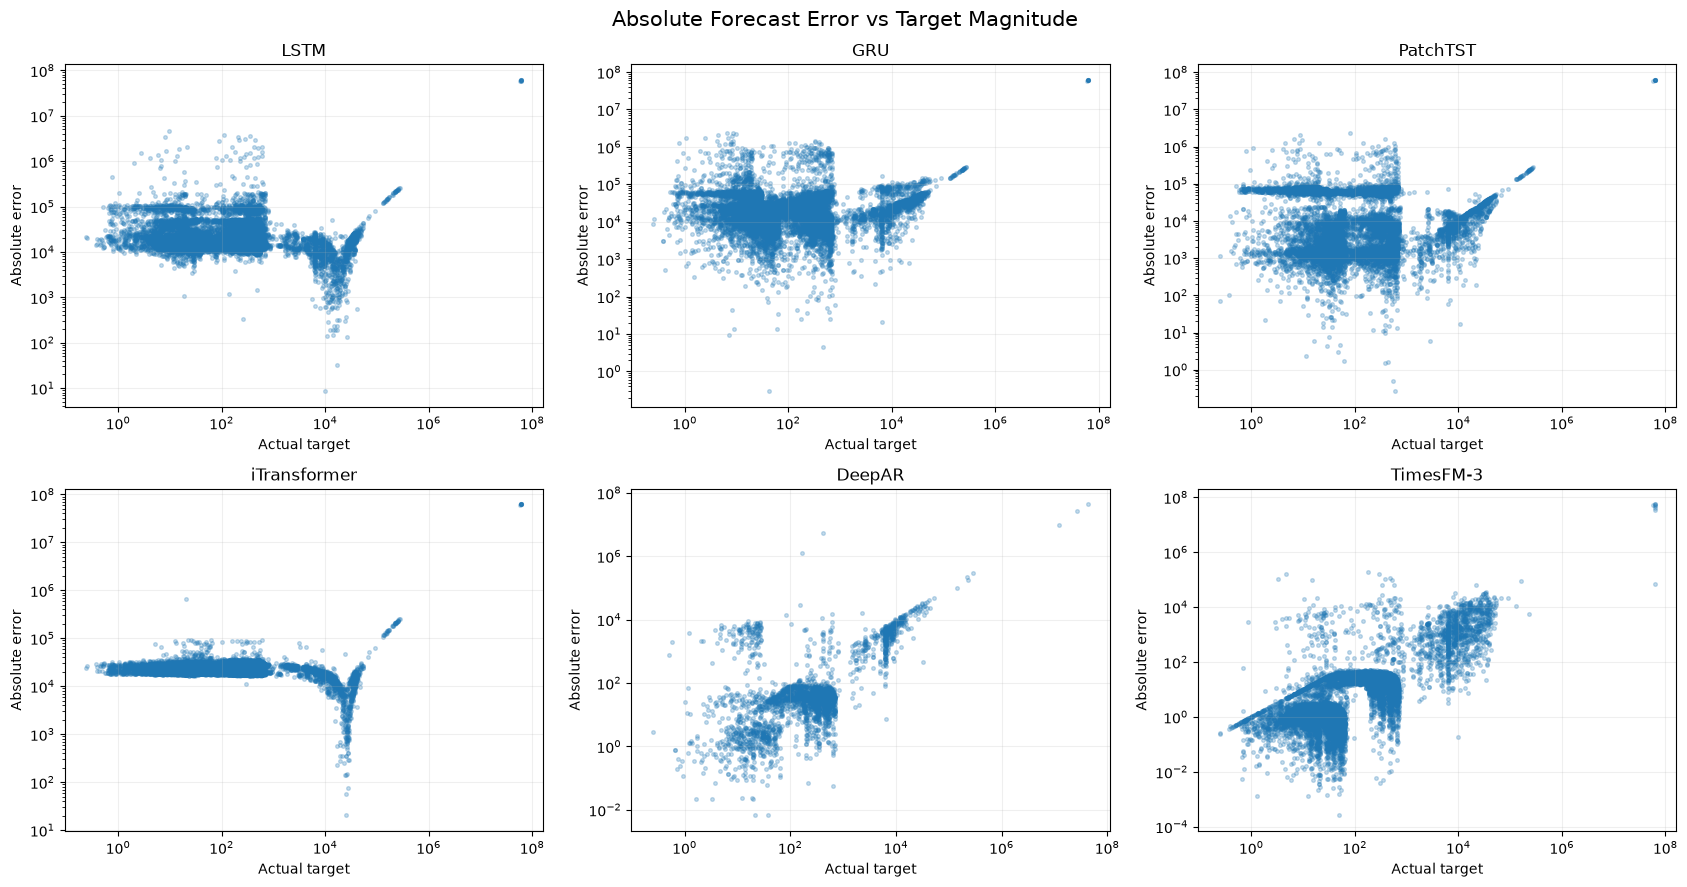

In [129]:
# ============================================================
# ABSOLUTE ERROR VS ACTUAL TARGET MAGNITUDE
# ============================================================

selected = [
    m for m in
    [
        "LSTM",
        "GRU",
        "PatchTST",
        "iTransformer",
        "DeepAR",
        "TimesFM-3"
    ]
    if m in available_models
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 9)
)

axes = np.asarray(axes).ravel()

for ax, model_name in zip(axes, selected):

    g = final_predictions[
        final_predictions["model"] == model_name
    ].copy()

    g["abs_error"] = (
        g["actual"] -
        g["prediction"]
    ).abs()

    g = g.replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna(
        subset=["actual", "abs_error"]
    )

    # Log scale requires positive values
    g = g[
        (g["actual"] > 0) &
        (g["abs_error"] > 0)
    ]

    if g.empty:
        ax.set_visible(False)
        continue

    ax.scatter(
        g["actual"],
        g["abs_error"],
        s=7,
        alpha=0.25
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_title(model_name)

    ax.set_xlabel(
        "Actual target"
    )

    ax.set_ylabel(
        "Absolute error"
    )

    ax.grid(
        True,
        alpha=0.2
    )

for ax in axes[len(selected):]:
    ax.set_visible(False)

fig.suptitle(
    "Absolute Forecast Error vs Target Magnitude",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "absolute_error_vs_target_magnitude.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

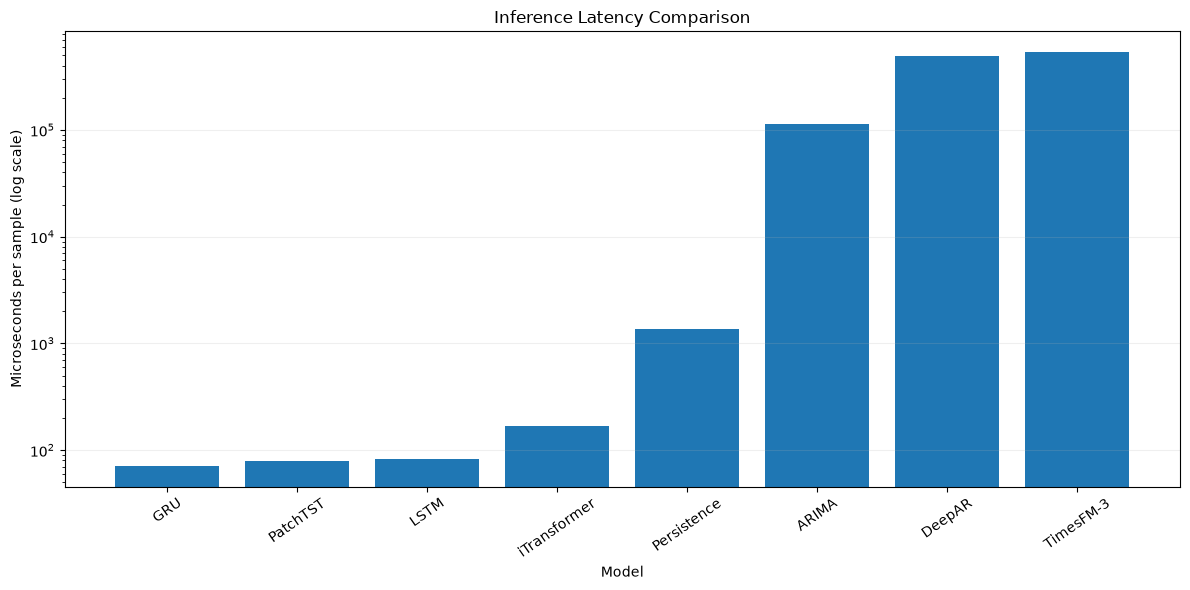

In [130]:
# ============================================================
# INFERENCE LATENCY
# ============================================================

if "latency_table" in globals() and not latency_table.empty:

    latency_plot = latency_table.copy()

    latency_plot = latency_plot.sort_values(
        "Microseconds_per_sample"
    )

    plt.figure(
        figsize=(12, 6)
    )

    plt.bar(
        latency_plot["Model"],
        latency_plot["Microseconds_per_sample"]
    )

    plt.yscale("log")

    plt.xlabel("Model")

    plt.ylabel(
        "Microseconds per sample (log scale)"
    )

    plt.title(
        "Inference Latency Comparison"
    )

    plt.xticks(
        rotation=35
    )

    plt.grid(
        True,
        axis="y",
        alpha=0.2
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "inference_latency_log.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [131]:
# ============================================================
# SAVE FIGURE INDEX
# ============================================================

figure_names = [
    "forecast_trace_<model>_IISC00IND_I01.png",
    "all_models_forecast_overlay.png",
    "predicted_vs_actual_all_models.png",
    "residuals_over_time_all_models.png",
    "residual_distribution_all_models.png",
    "residual_acf_selected_models.png",
    "target_distribution_log.png",
    "rmse_mae_log_comparison.png",
    "condition_wise_rmse.png",
    "station_wise_rmse.png",
    "satellite_wise_rmse_heatmap.png",
    "absolute_error_vs_target_magnitude.png",
    "inference_latency_log.png",
]

figure_index = pd.DataFrame({
    "Figure_file": figure_names
})

figure_index.to_csv(
    OUTPUT_DIR / "o1_extended_figure_index.csv",
    index=False
)

print("Visualization suite completed.")
print("Figures saved to:", OUTPUT_DIR.resolve())

Visualization suite completed.
Figures saved to: D:\My Files\A7-A\Kaushik\M.Tech-AI-CB.SC.P2AIE25030\CB.SC.P2AIE25030-Project\Code\Proto-7\navic_o1\results\o1_full_dataset
